# Sentinel-2 monthly views, Ryczołek

One cloud-free Sentinel-2 scene for each month from January 2019 through December 2024. The view is the mine polygon plus the same 200 m buffer used as the mine AOI. A scene is kept when its footprint covers that whole extent and SCL has no cloud, cloud shadow, cirrus or snow on it. If several scenes in a month qualify, the earliest one is shown. Each month is a separate figure.

### 1. Extent

In [1]:
import json
from pathlib import Path

import ee
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from pyproj import Transformer
from shapely.geometry import shape
from shapely.ops import transform, unary_union

HOME_DIR = Path(r"c:\space_technologies\Kopalnie\open-pit-mining\sar")
GEE_PROJECT_NAME = (HOME_DIR / "gee_project").read_text(encoding="utf-8").strip()
ee.Initialize(project=GEE_PROJECT_NAME)

POLYGON_PATH = HOME_DIR / "mines_polygons" / "ryczolek_mine_polygon.geojson"
BUFFER_M = 200
START_YEAR = 2019
END_YEAR = 2024

data = json.loads(POLYGON_PATH.read_text(encoding="utf-8"))
features = data["features"] if data.get("type") == "FeatureCollection" else [data]
mine = unary_union([shape(feature["geometry"]) for feature in features])

longitude, latitude = mine.centroid.x, mine.centroid.y
zone = int((longitude + 180) // 6) + 1
utm_epsg = (32600 if latitude >= 0 else 32700) + zone
to_utm = Transformer.from_crs("EPSG:4326", "EPSG:%d" % utm_epsg, always_xy=True)
to_wgs = Transformer.from_crs("EPSG:%d" % utm_epsg, "EPSG:4326", always_xy=True)
mine_utm = transform(to_utm.transform, mine)
view_wgs = transform(to_wgs.transform, mine_utm.buffer(BUFFER_M).envelope)

aoi = ee.Geometry(view_wgs.__geo_interface__)
extent = view_wgs.bounds
print("mine bounds:", [round(value, 5) for value in mine.bounds])
print("view bounds:", [round(value, 5) for value in extent])
print("buffer: %d m" % BUFFER_M)


c:\space_technologies\Kopalnie\open-pit-mining\.venv-backup\lib\site-packages\google\oauth2\__init__.py:40: FutureWarning: You are using a Python version 3.9 past its end of life. Google will update google-auth with critical bug fixes on a best-effort basis, but not with any other fixes or features. Please upgrade your Python version, and then update google-auth.
  warnings.warn(eol_message.format("3.9"), FutureWarning)
c:\space_technologies\Kopalnie\open-pit-mining\.venv-backup\lib\site-packages\google\auth\__init__.py:54: FutureWarning: You are using a Python version 3.9 past its end of life. Google will update google-auth with critical bug fixes on a best-effort basis, but not with any other fixes or features. Please upgrade your Python version, and then update google-auth.
  warnings.warn(eol_message.format("3.9"), FutureWarning)
c:\space_technologies\Kopalnie\open-pit-mining\.venv-backup\lib\site-packages\google\api_core\_python_version_support.py:242: FutureWarning: You are using

mine bounds: [21.78069, 52.19279, 21.78262, 52.19571]
view bounds: [21.77769, 52.19097, 21.78562, 52.19753]
buffer: 200 m


### 2. One clear scene per month

Cloud, cloud shadow, cirrus and snow are SCL classes 3, 8, 9 and 10. The fraction of those pixels on the buffered extent must be zero.

In [2]:
def flag_image(image):
    scene_class = image.select("SCL")
    cloud = scene_class.eq(3).Or(scene_class.eq(8)).Or(scene_class.eq(9)).Or(scene_class.eq(10)).rename("cloud")
    fraction = cloud.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=aoi,
        scale=20,
        maxPixels=1e8,
    ).get("cloud")
    covers = image.geometry().contains(aoi, ee.ErrorMargin(1))
    return image.set({"cloud": fraction, "covers": covers})


def scenes_for_year(year):
    months = ee.List.sequence(1, 12)

    def pack(month):
        start = ee.Date.fromYMD(year, ee.Number(month).int(), 1)
        end = start.advance(1, "month")
        clear = (
            ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
            .filterBounds(aoi)
            .filterDate(start, end)
            .map(flag_image)
            .filter(ee.Filter.eq("covers", True))
            .filter(ee.Filter.lte("cloud", 0))
            .sort("system:time_start")
        )
        first = ee.Image(clear.first())
        missing = clear.size().eq(0)
        return ee.Feature(None, {
            "month": start.format("YYYY-MM"),
            "missing": missing,
            "date": ee.Algorithms.If(missing, "", ee.Date(first.get("system:time_start")).format("YYYY-MM-dd")),
            "id": ee.Algorithms.If(missing, "", first.get("system:index")),
        })

    features = ee.FeatureCollection(months.map(pack)).getInfo()["features"]
    rows = []
    for feature in features:
        props = feature["properties"]
        rows.append({
            "month": props["month"],
            "date": props["date"] or None,
            "id": props["id"] or None,
        })
        if props["date"]:
            print("%s  %s  %s" % (props["month"], props["date"], props["id"]))
        else:
            print("%s  no cloud-free scene" % props["month"])
    return rows


monthly = []
for year in range(START_YEAR, END_YEAR + 1):
    print("Year %d" % year)
    monthly.extend(scenes_for_year(year))

found = sum(1 for row in monthly if row["id"])
print("%d months, %d cloud-free scenes" % (len(monthly), found))


Year 2019
2019-01  2019-01-03  20190103T095409_20190103T095535_T34UEC
2019-02  2019-02-19  20190219T094039_20190219T094304_T34UEC
2019-03  2019-03-24  20190324T095029_20190324T095522_T34UEC
2019-04  2019-04-03  20190403T095029_20190403T095557_T34UEC
2019-05  2019-05-25  20190525T094031_20190525T094034_T34UEC
2019-06  2019-06-09  20190609T094039_20190609T094208_T34UEC
2019-07  2019-07-17  20190717T095041_20190717T095154_T34UEC
2019-08  2019-08-23  20190823T094031_20190823T094536_T34UEC
2019-09  2019-09-05  20190905T095031_20190905T095319_T34UEC
2019-10  2019-10-12  20191012T094031_20191012T094345_T34UEC
2019-11  no cloud-free scene
2019-12  2019-12-06  20191206T094259_20191206T094328_T34UEC
Year 2020
2020-01  no cloud-free scene
2020-02  2020-02-07  20200207T095059_20200207T095055_T34UEC
2020-03  2020-03-05  20200305T094029_20200305T094028_T34UEC
2020-04  2020-04-07  20200407T095029_20200407T095026_T34UEC
2020-05  2020-05-07  20200507T095029_20200507T095027_T34UEC
2020-06  2020-06-06  2

### 3. True-colour views

One figure per month. The red line is the mine polygon. Reflectance is stretched from 0 to 0.3 so months stay comparable.

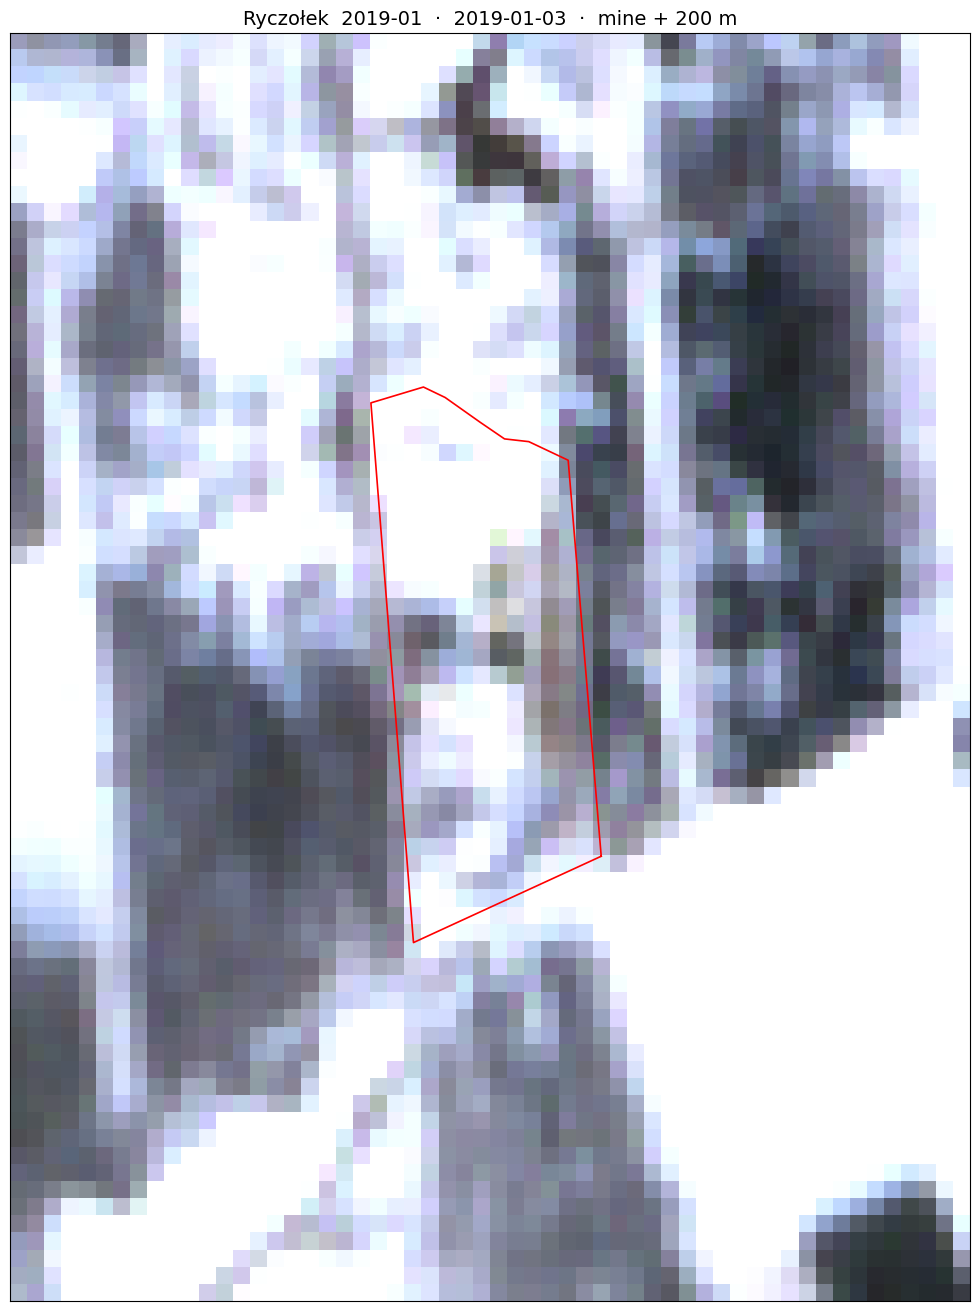

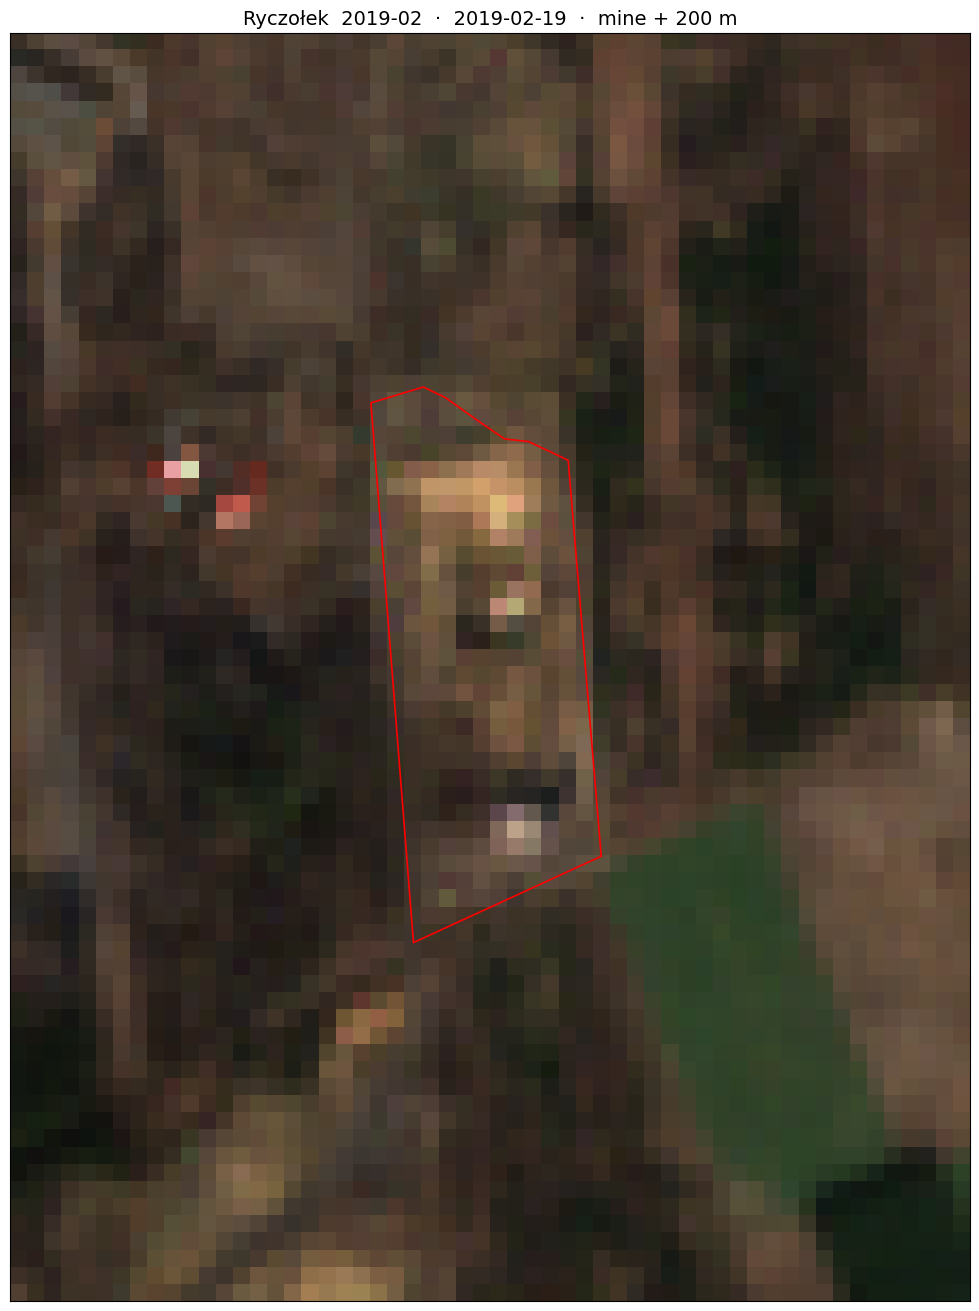

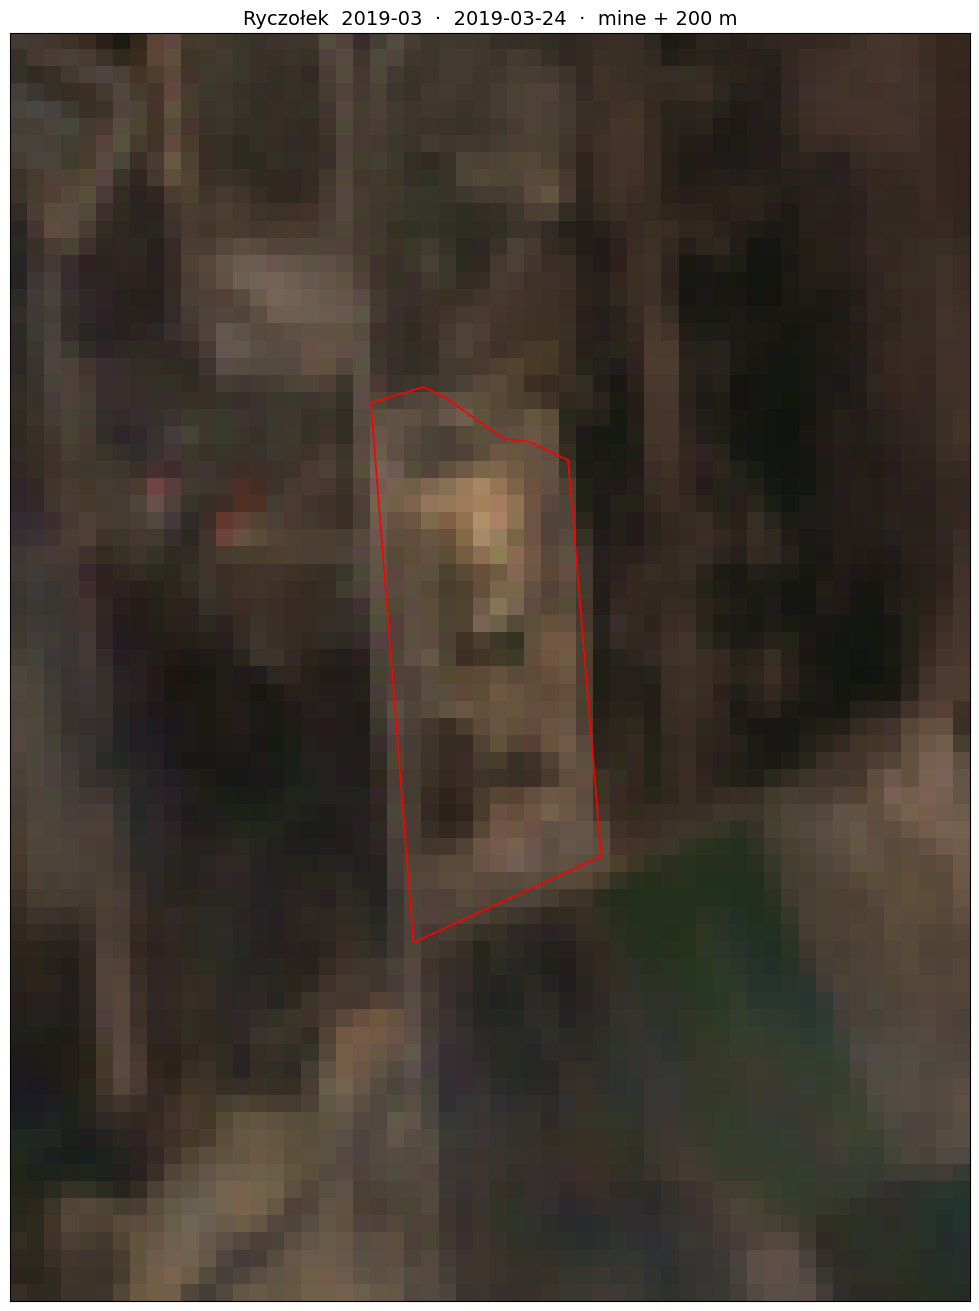

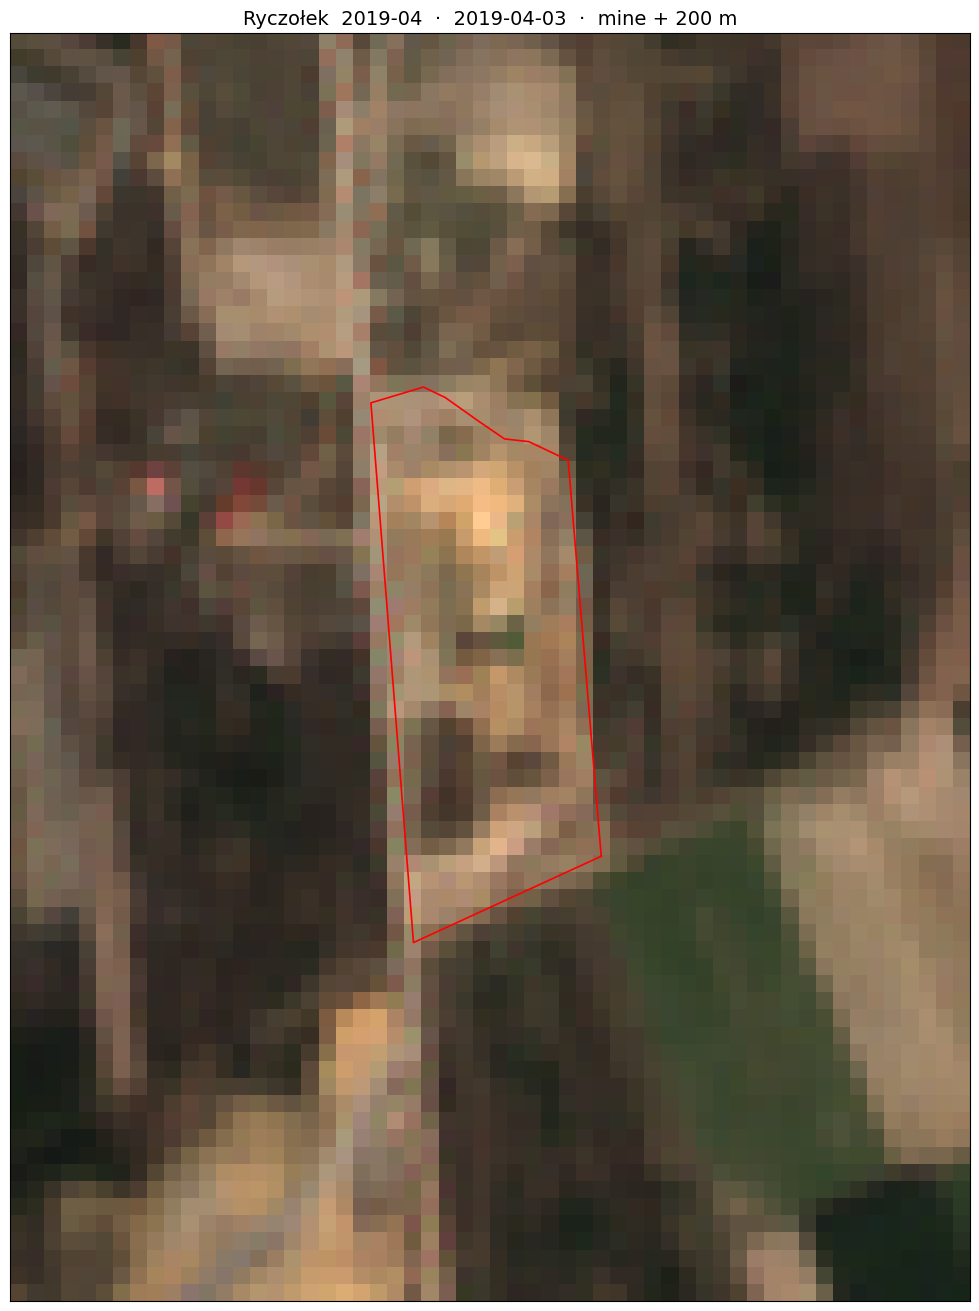

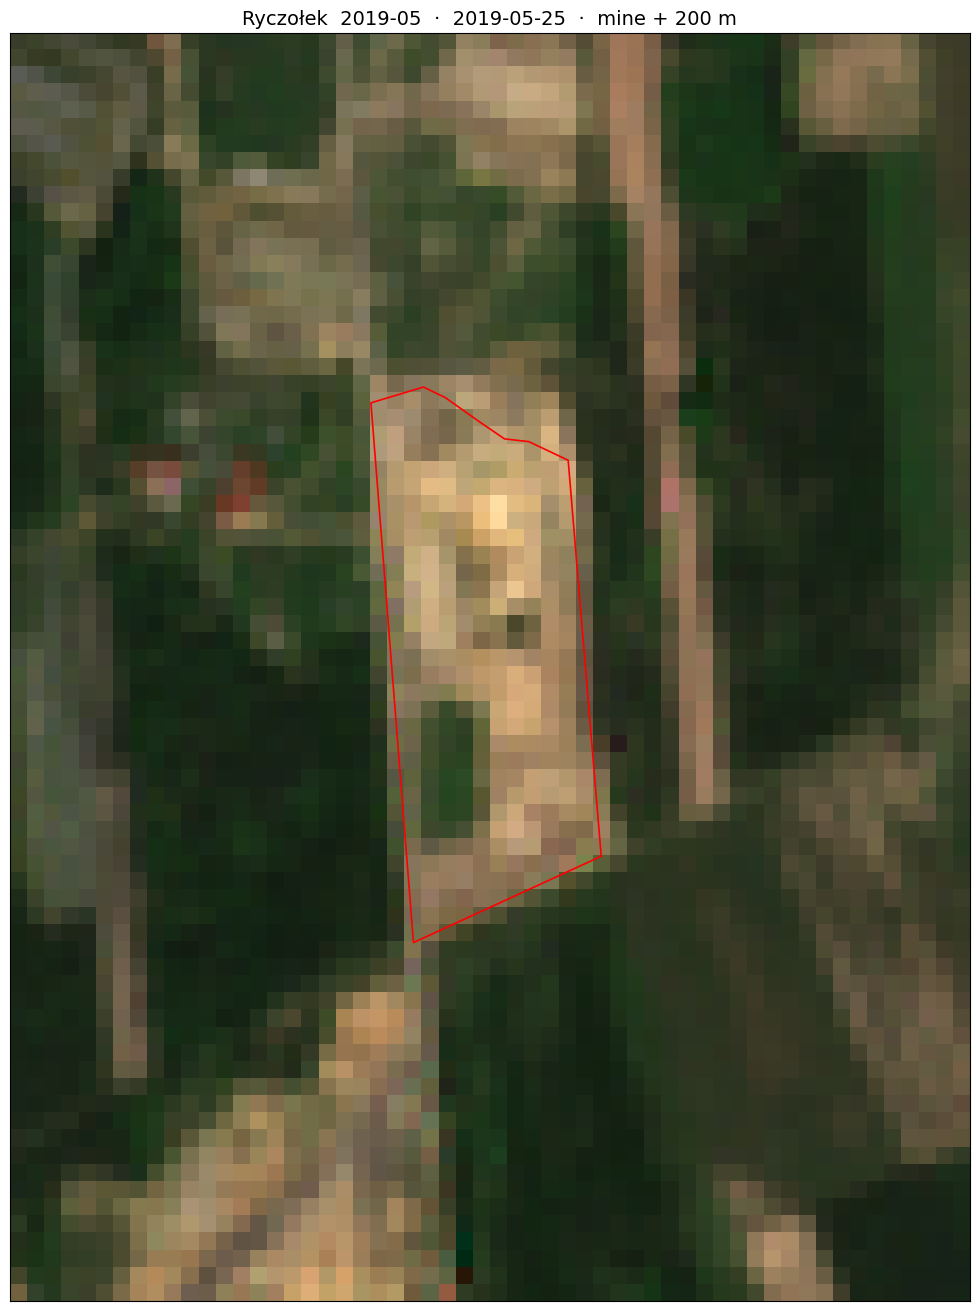

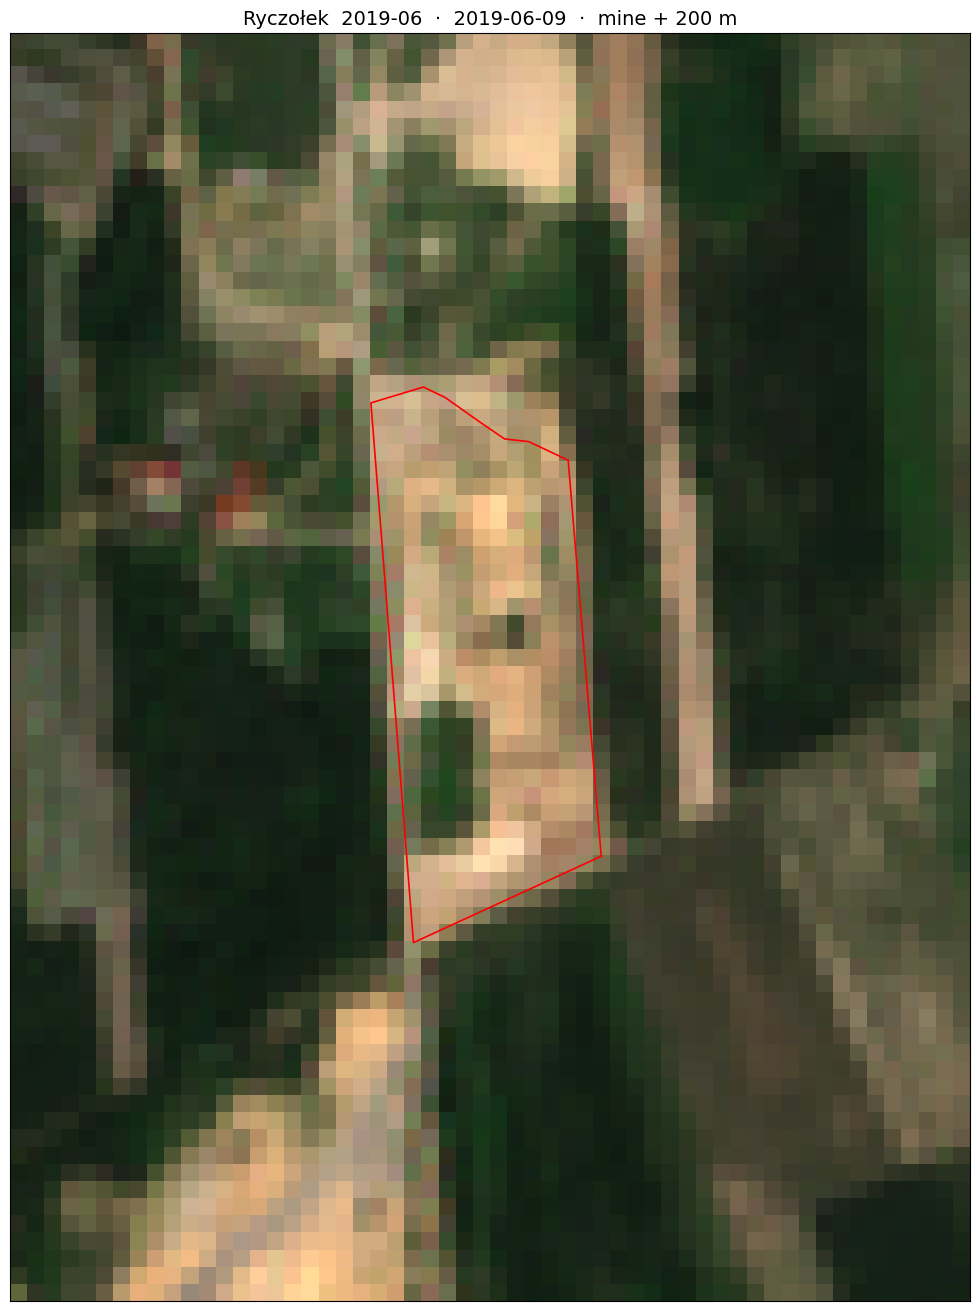

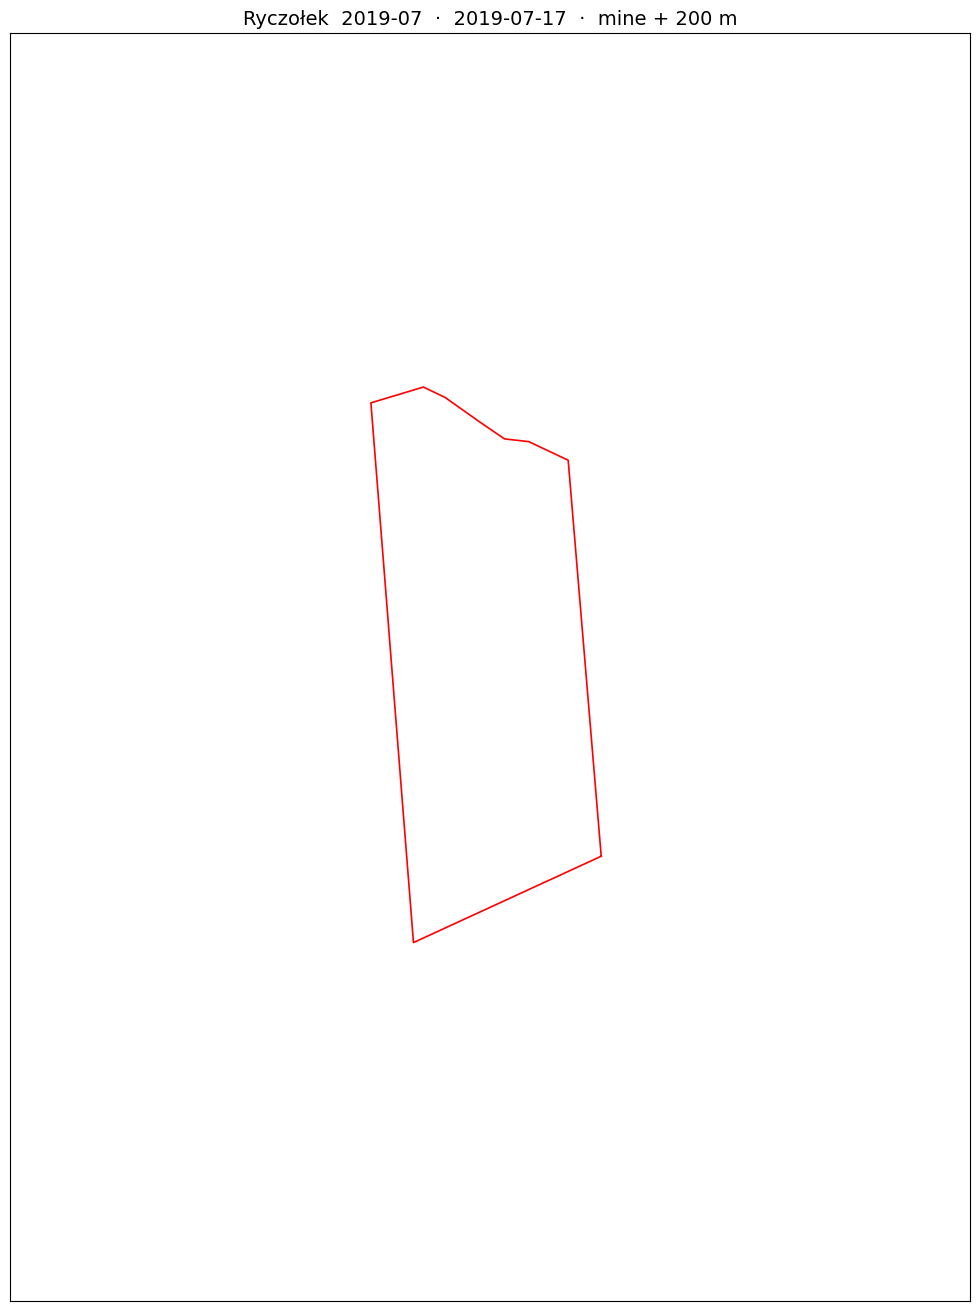

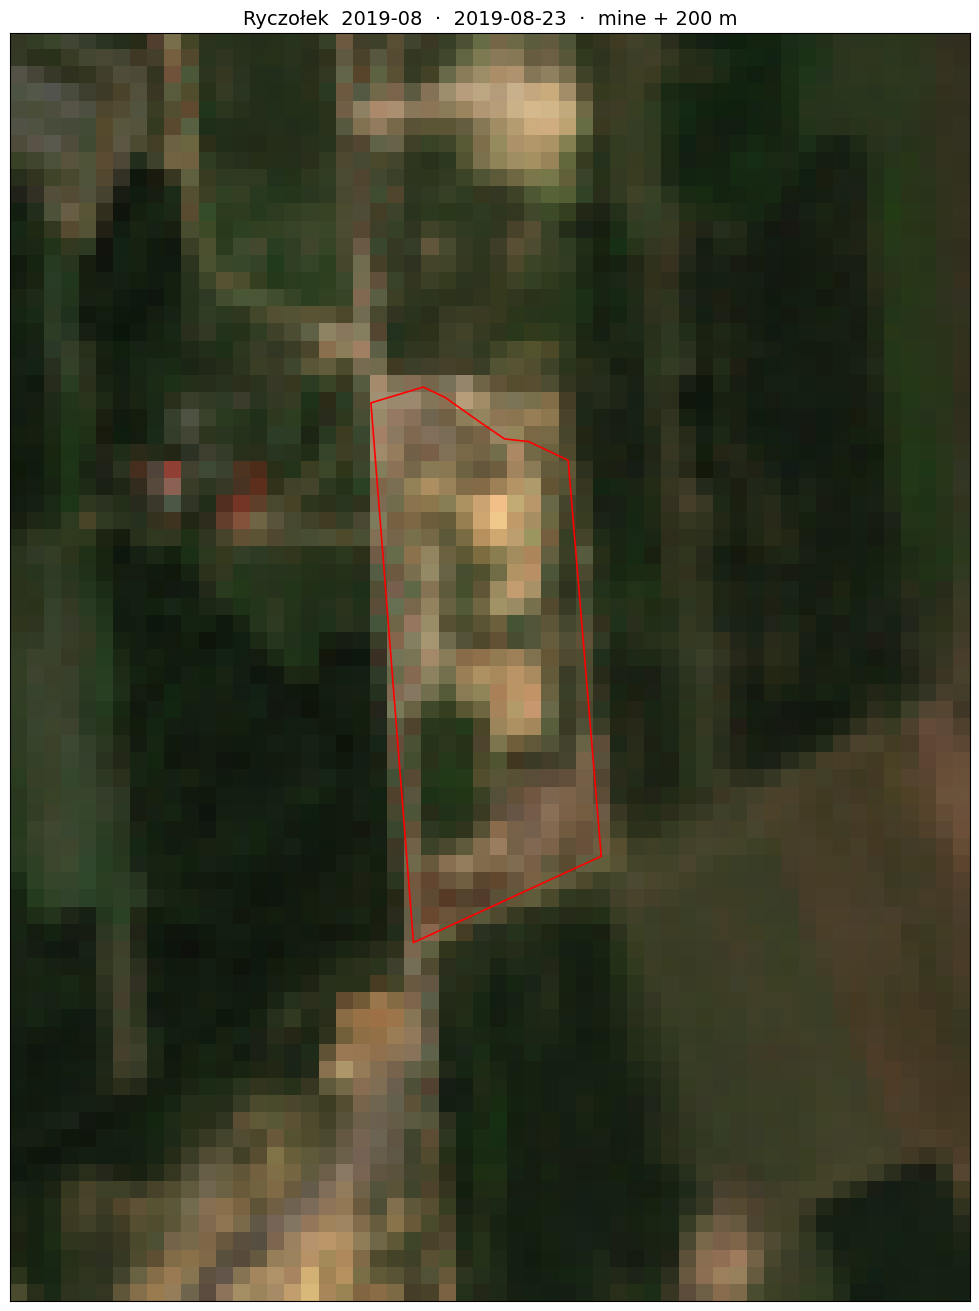

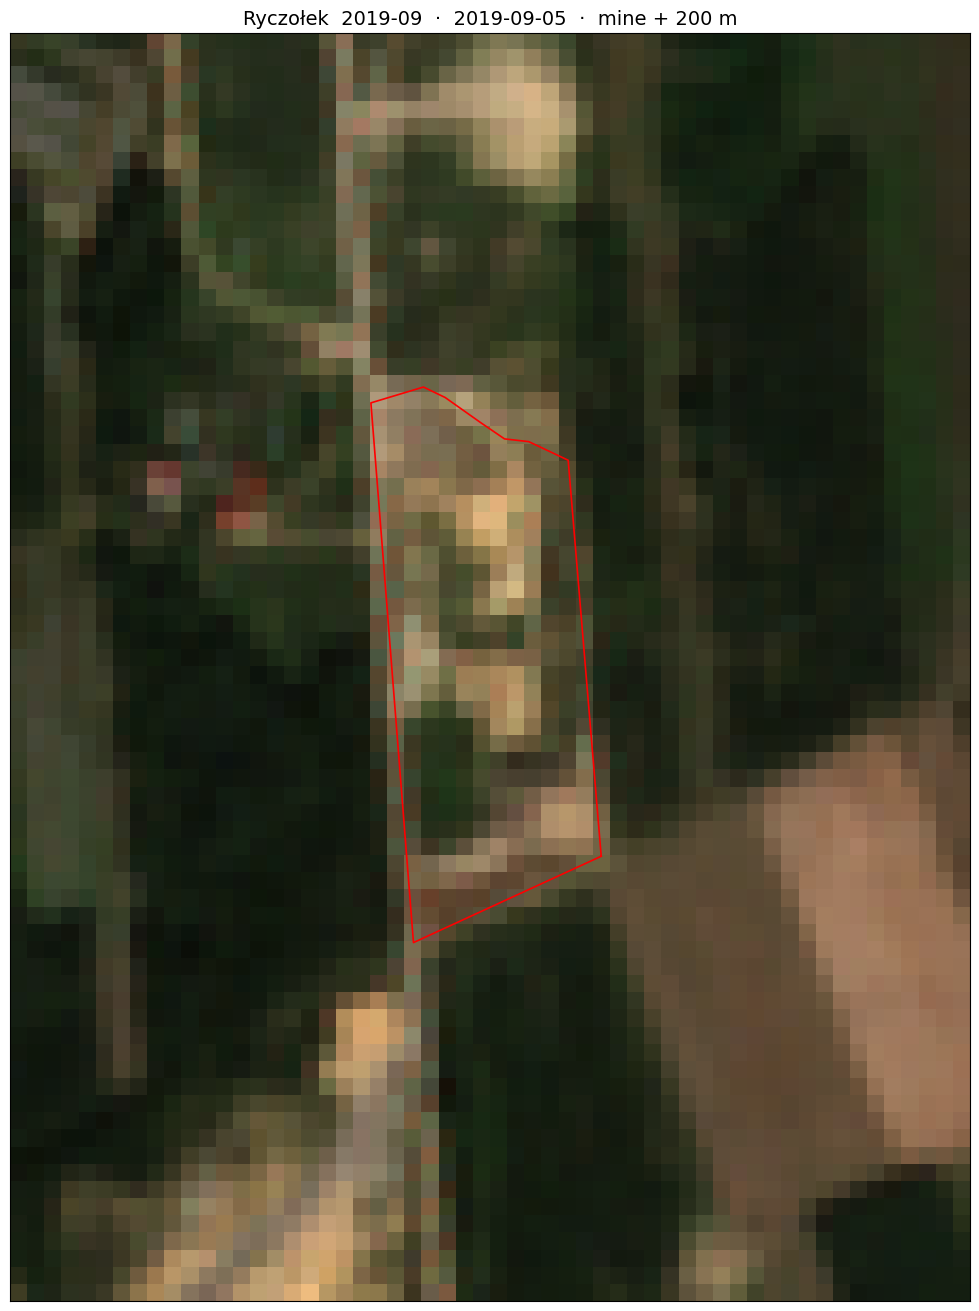

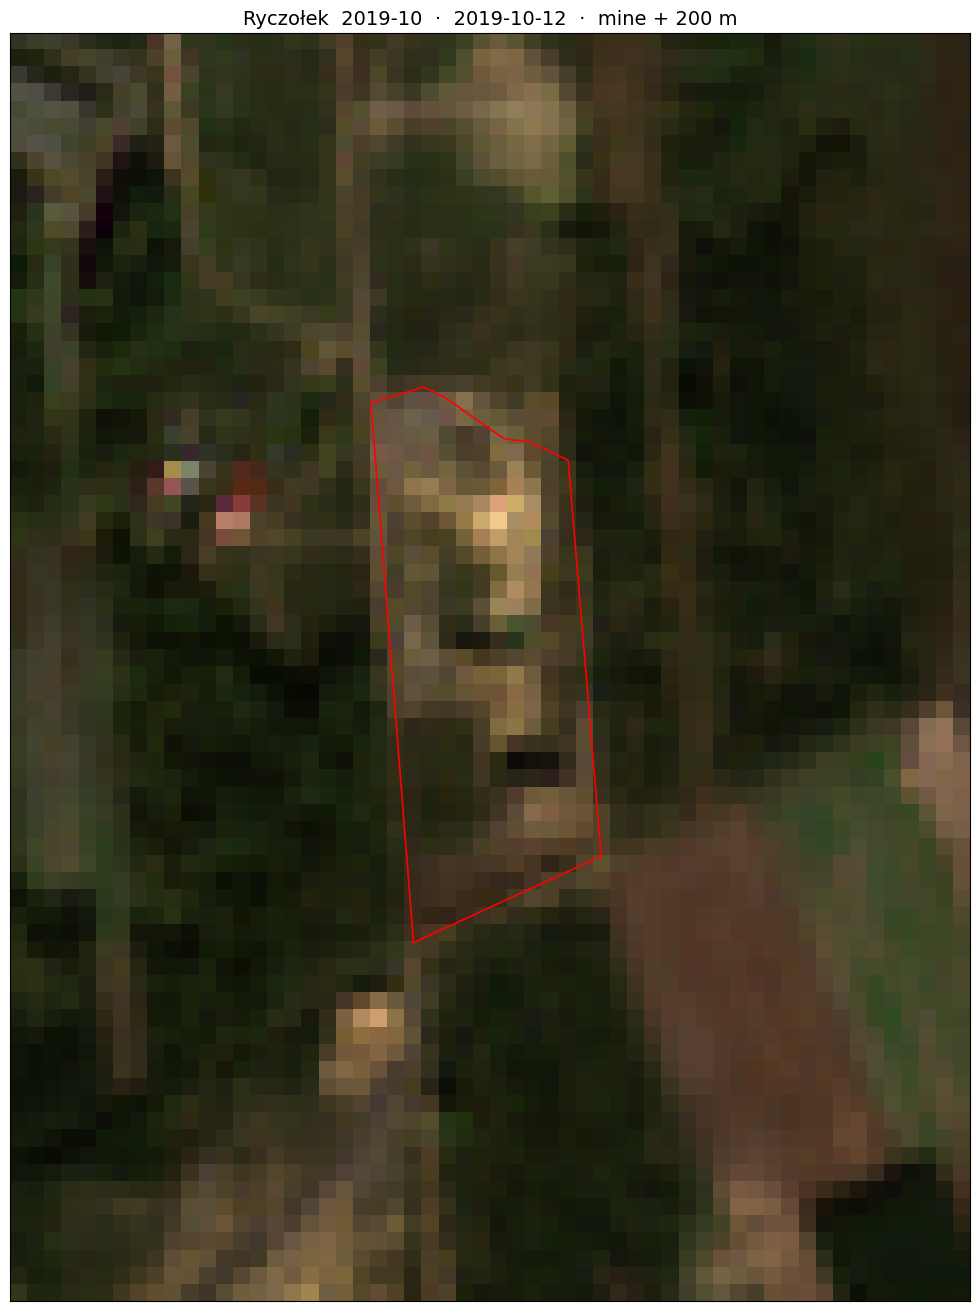

2019-11  no cloud-free scene


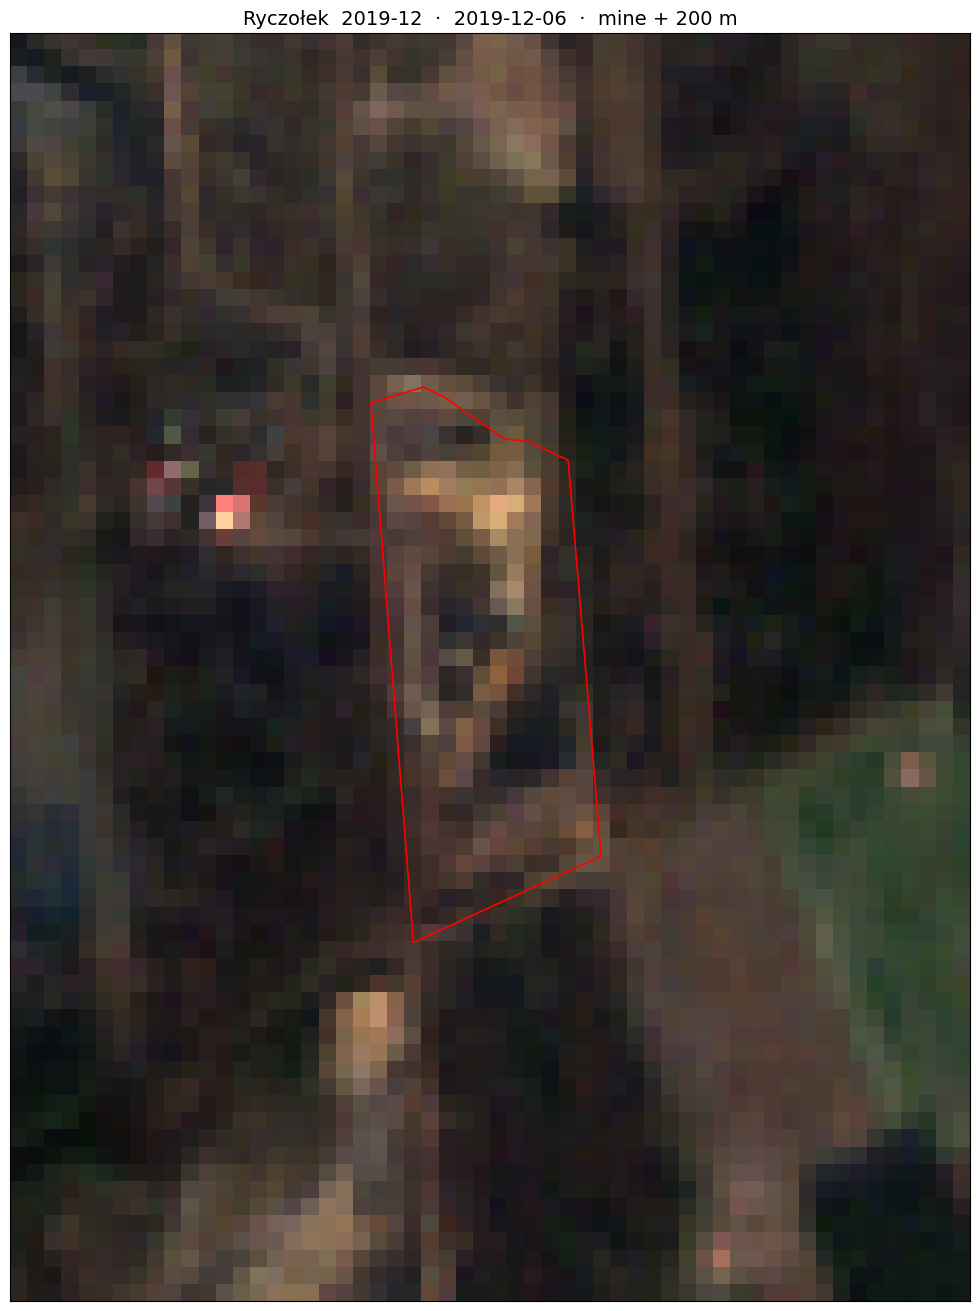

2020-01  no cloud-free scene


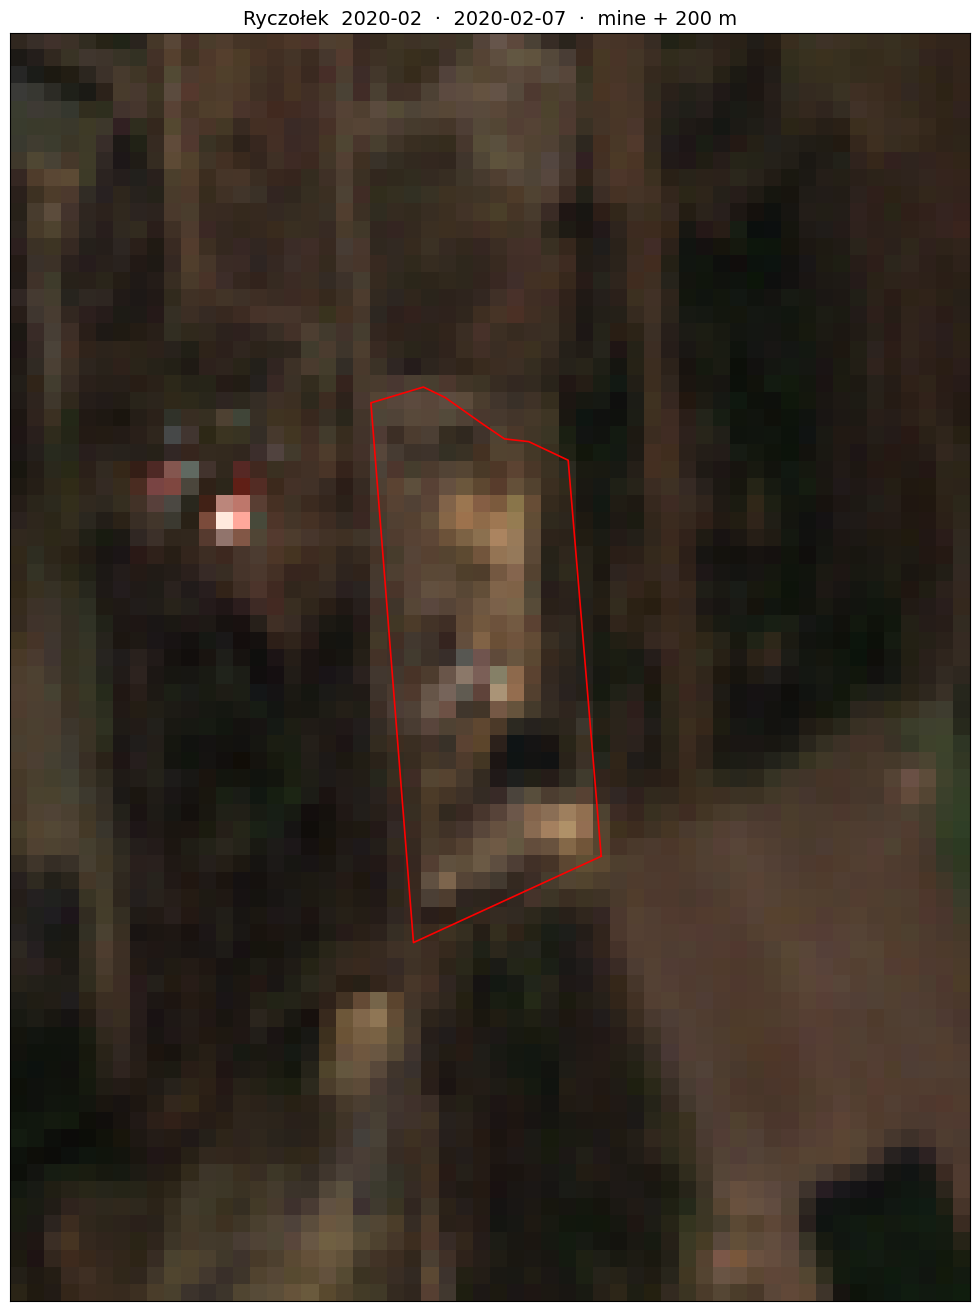

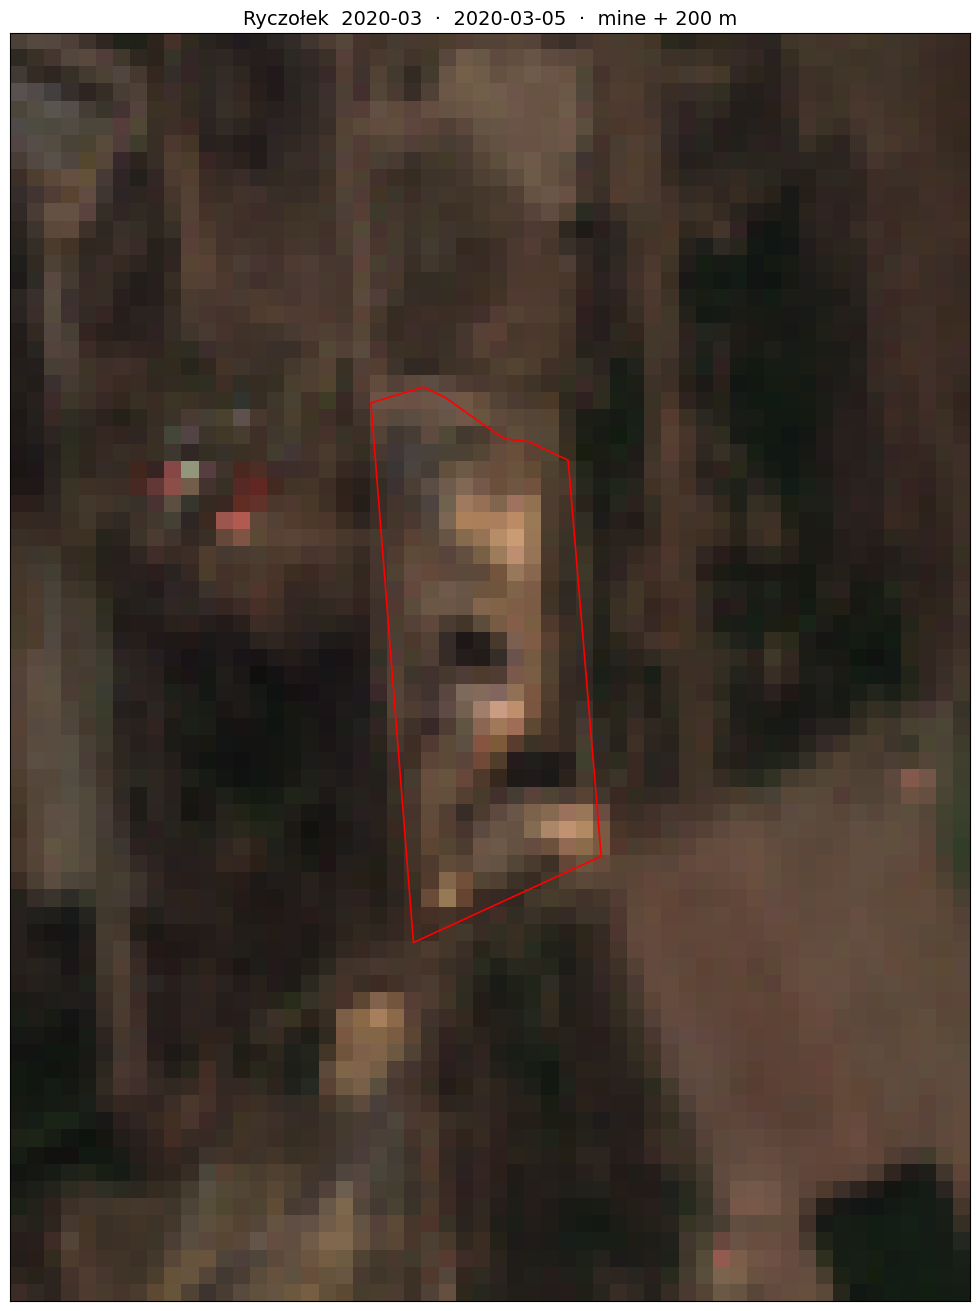

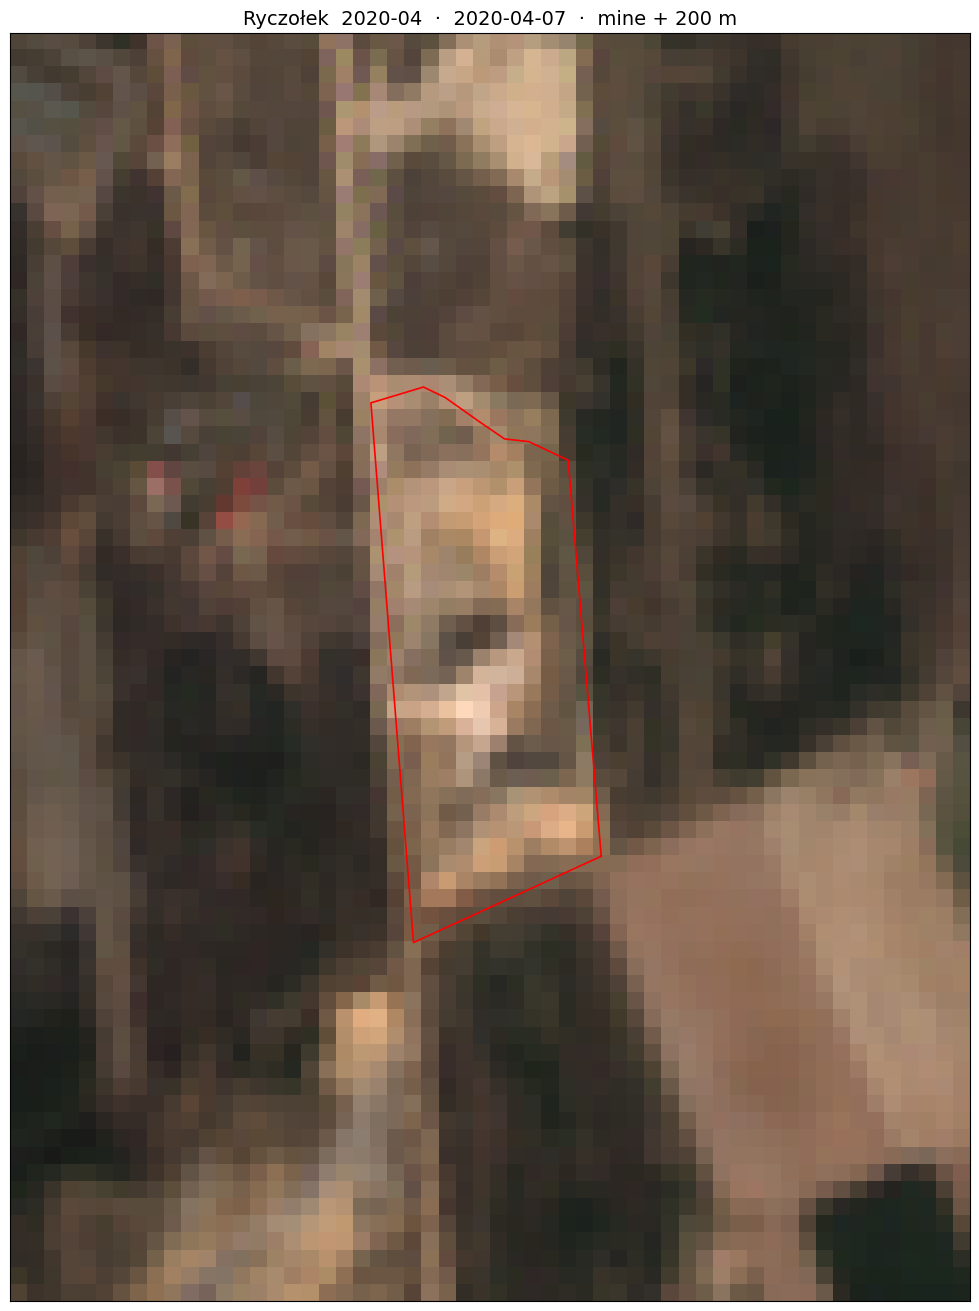

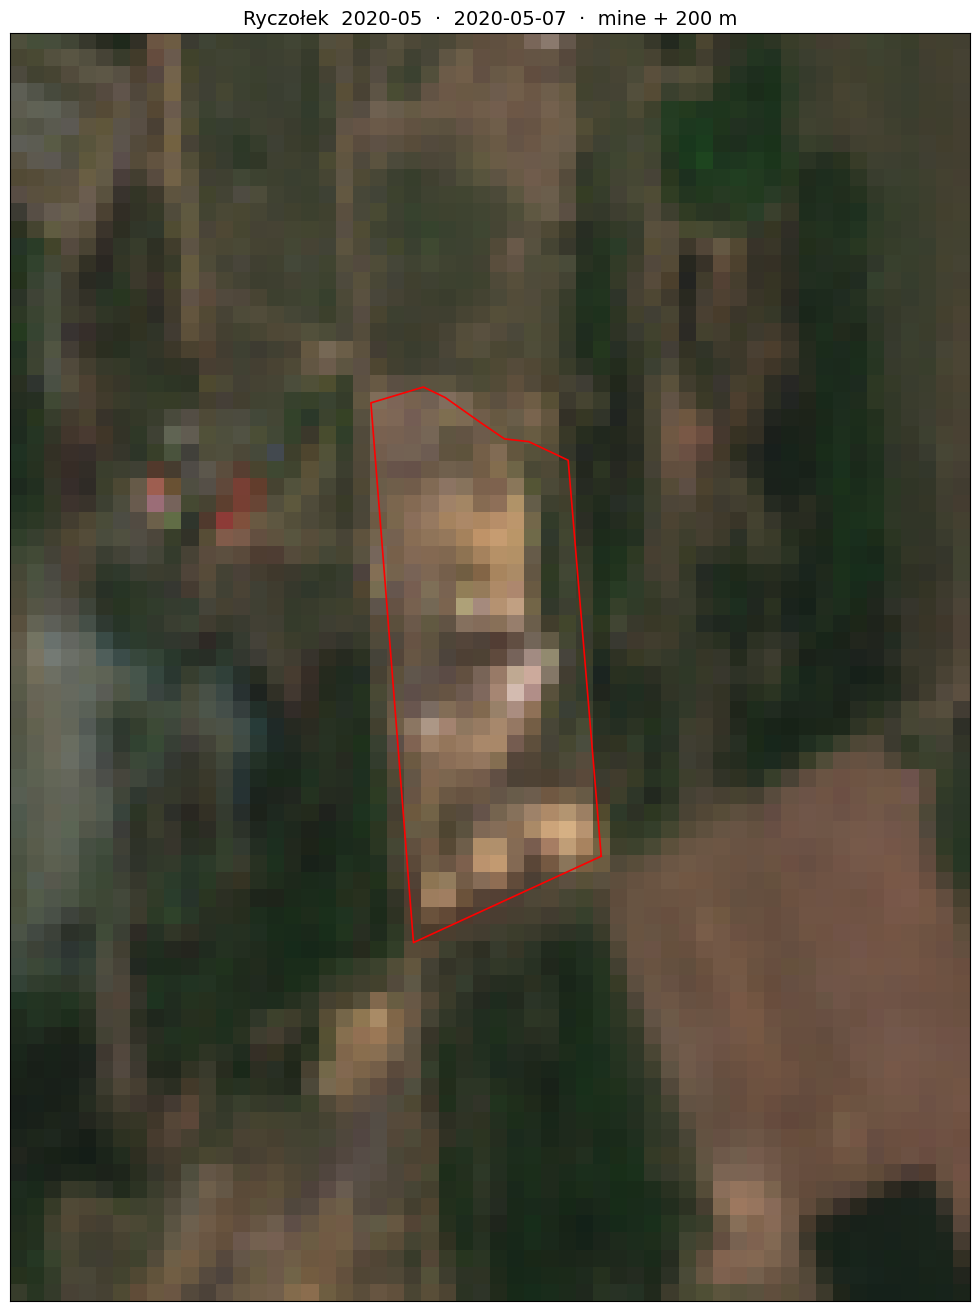

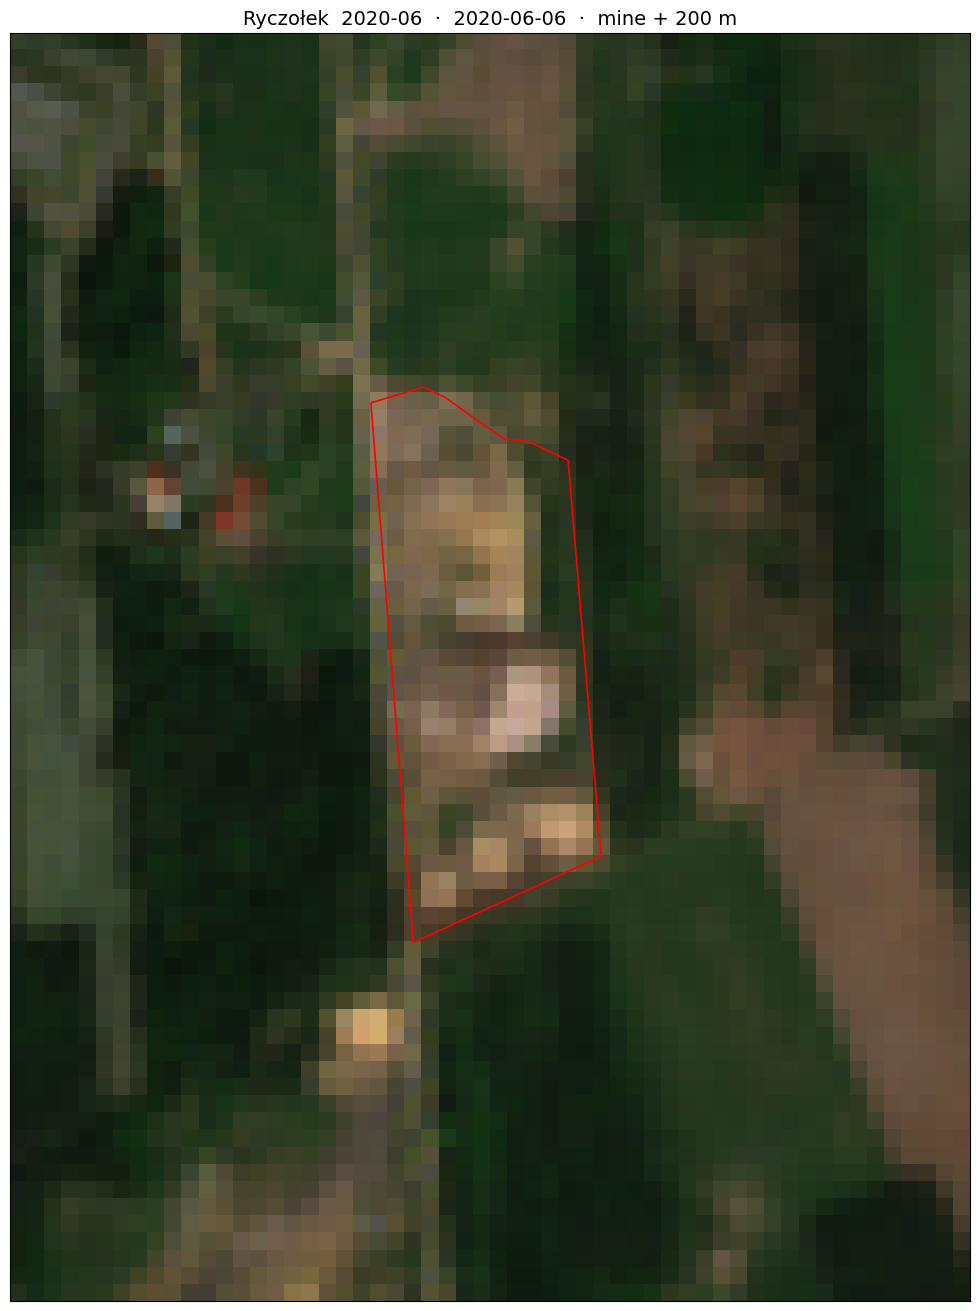

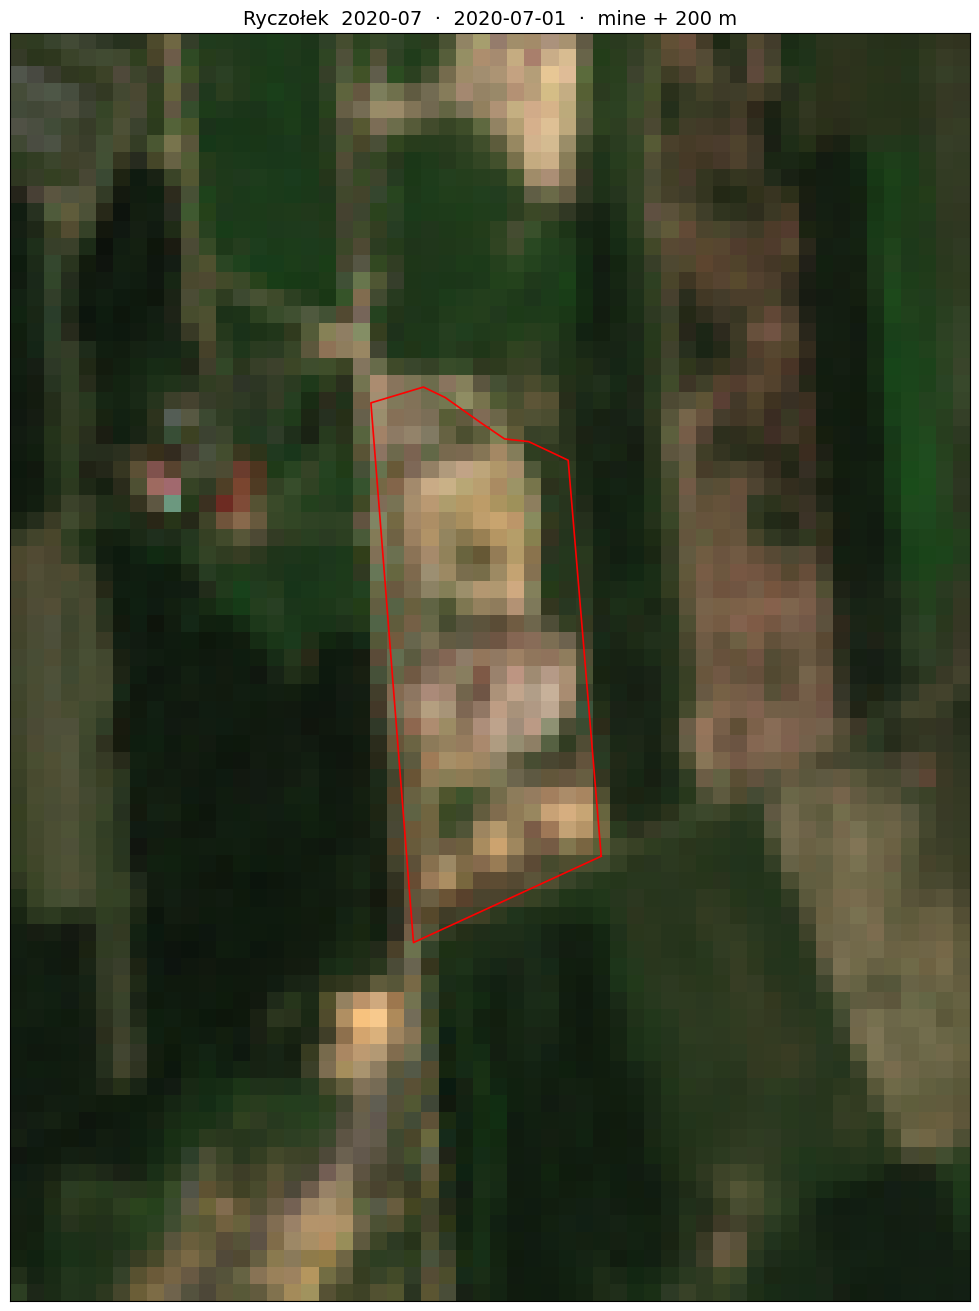

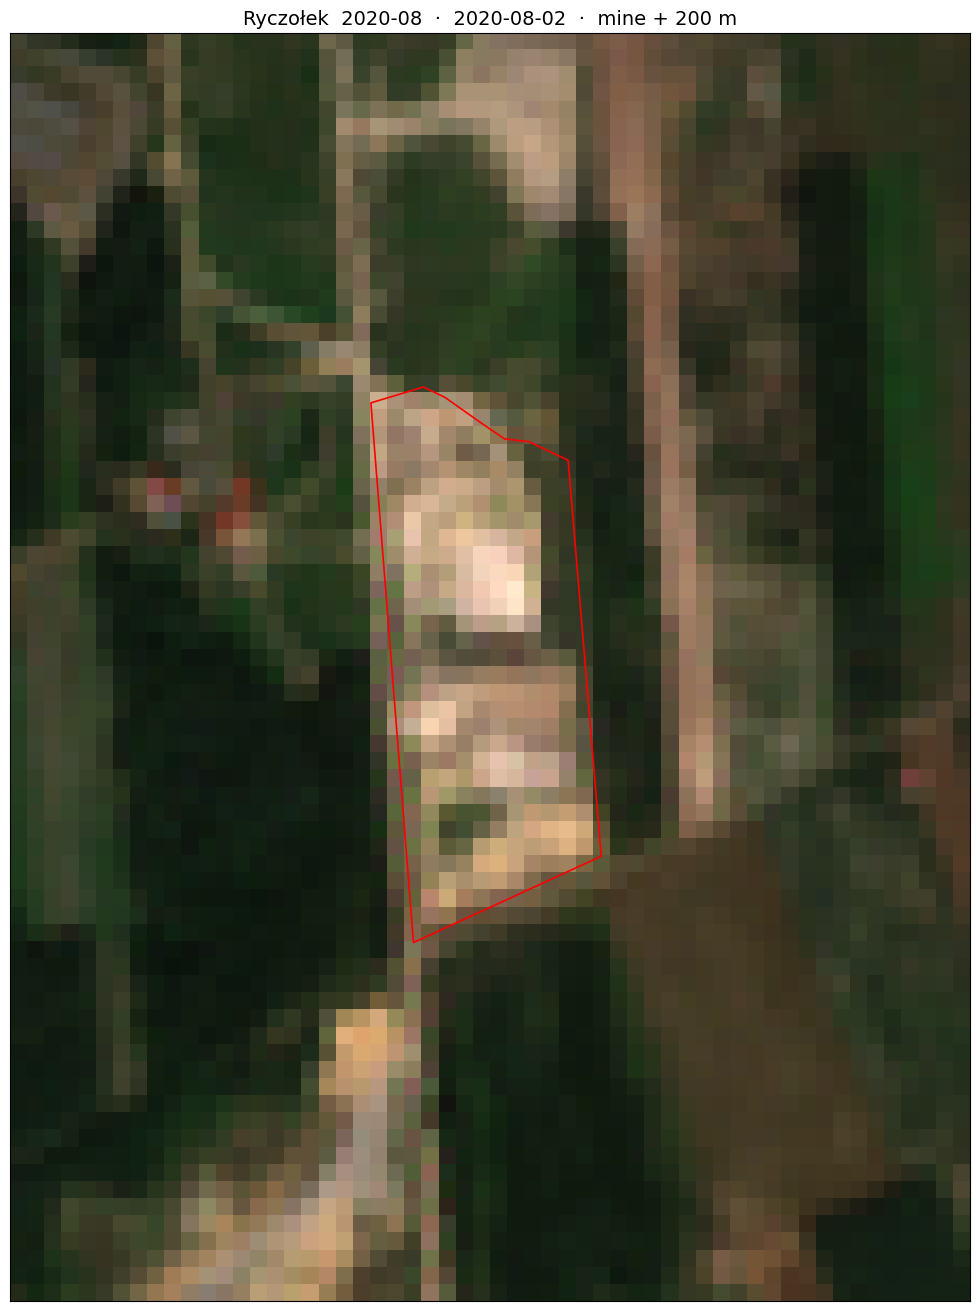

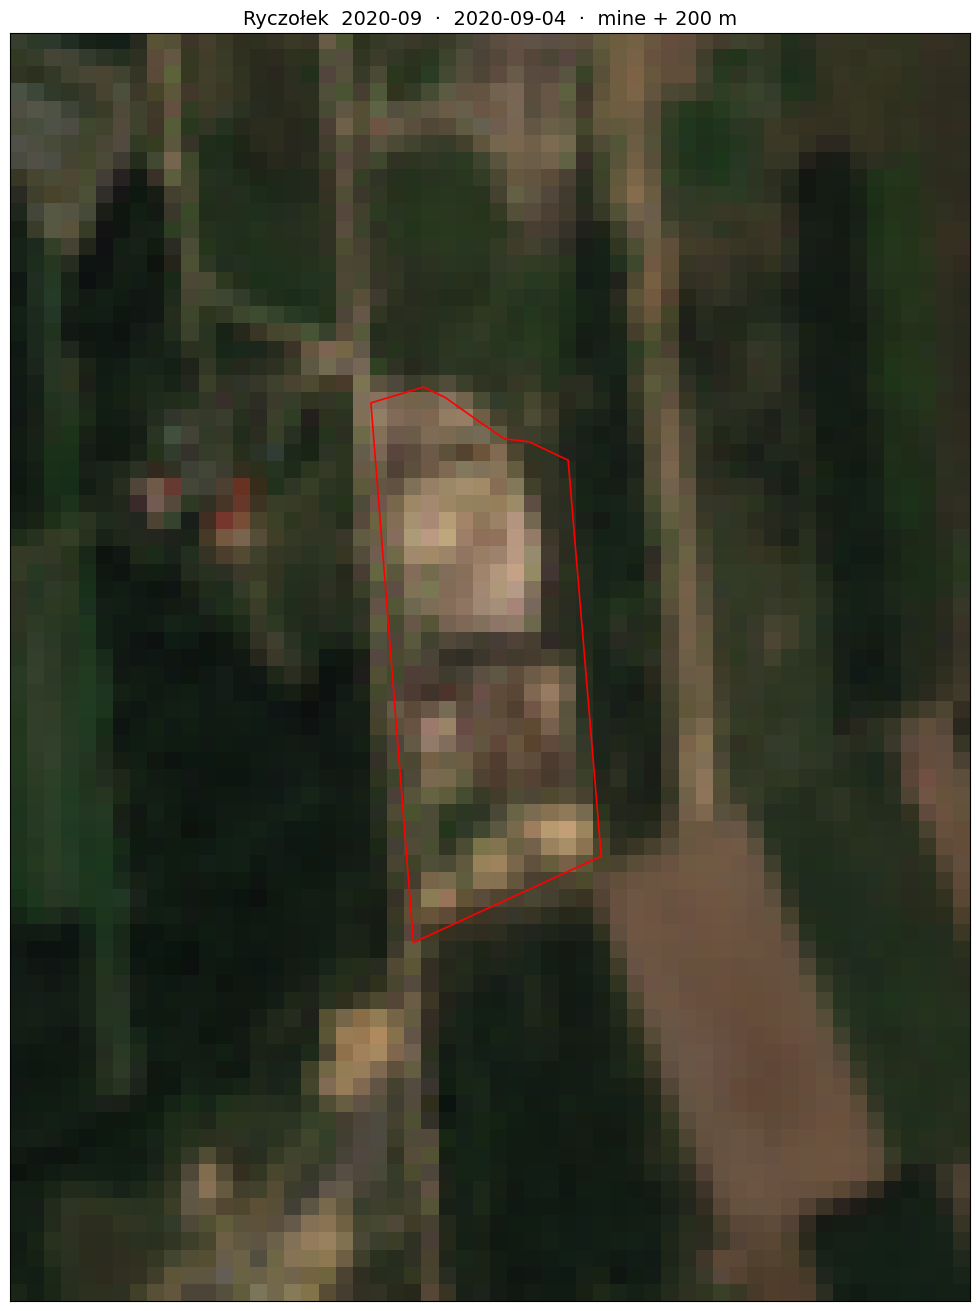

2020-10  no cloud-free scene


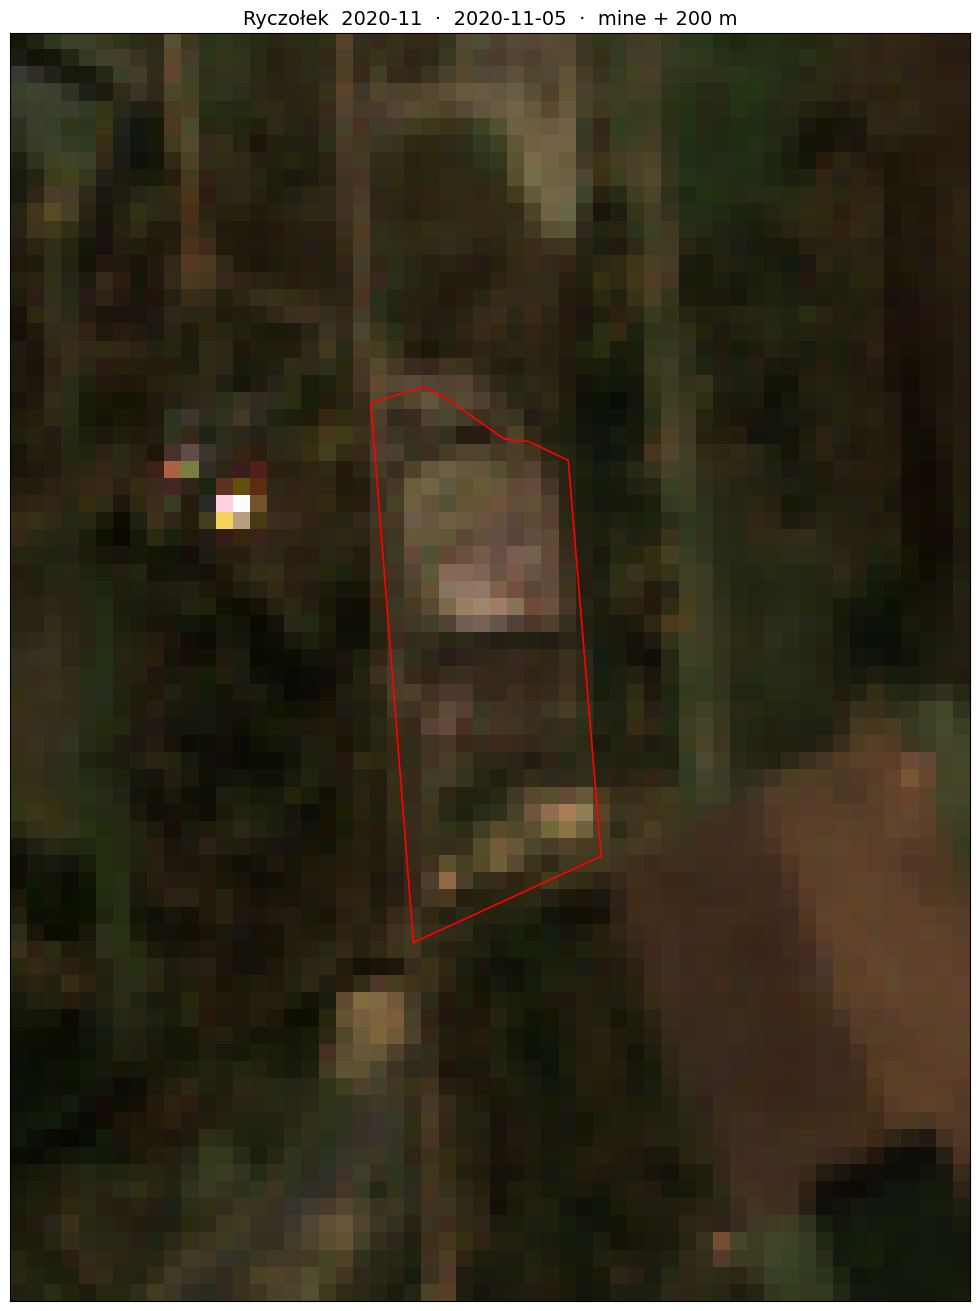

2020-12  no cloud-free scene
2021-01  no cloud-free scene


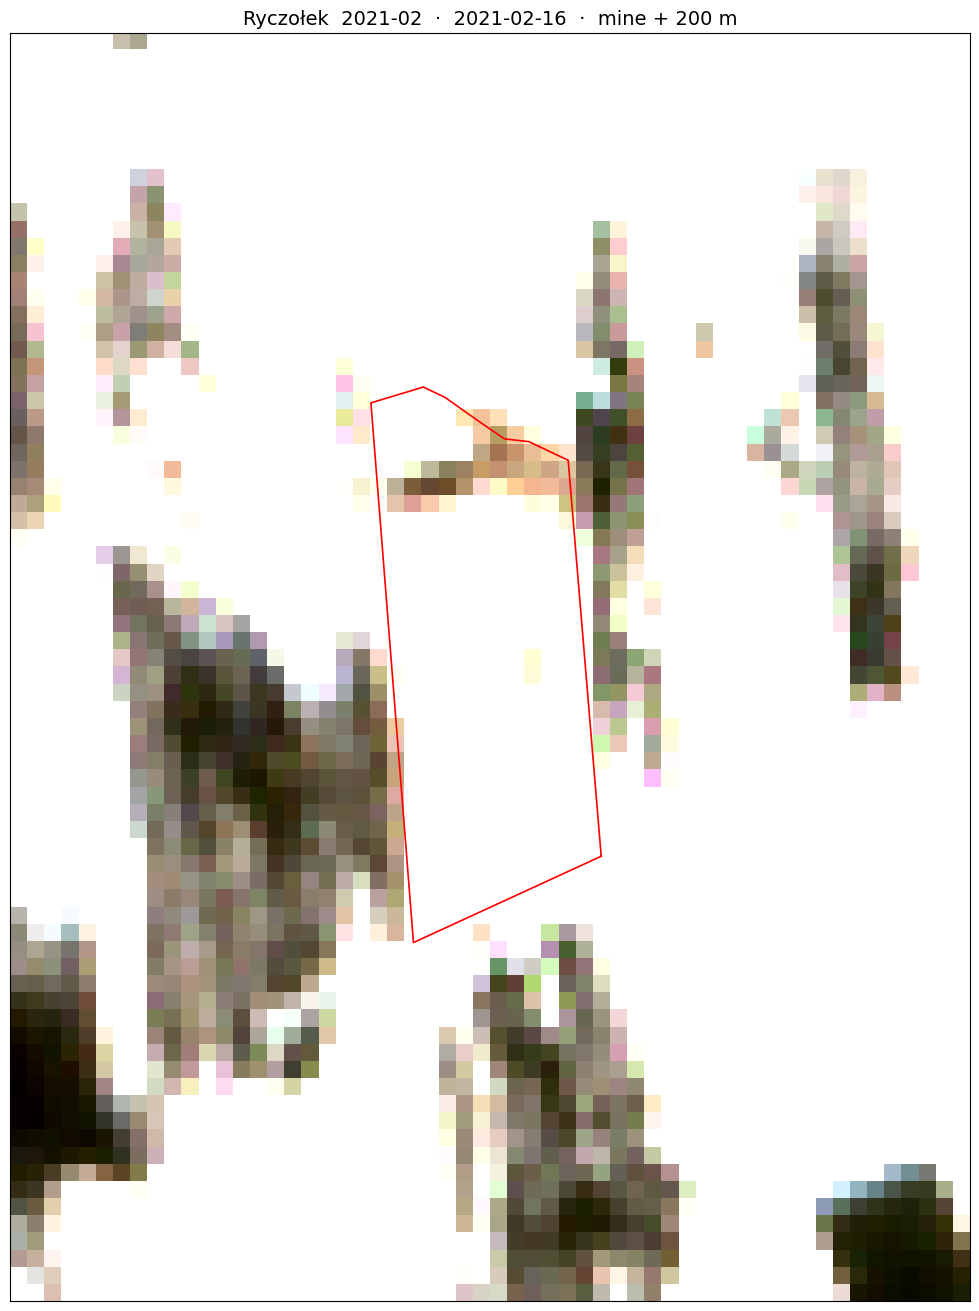

2021-03  no cloud-free scene


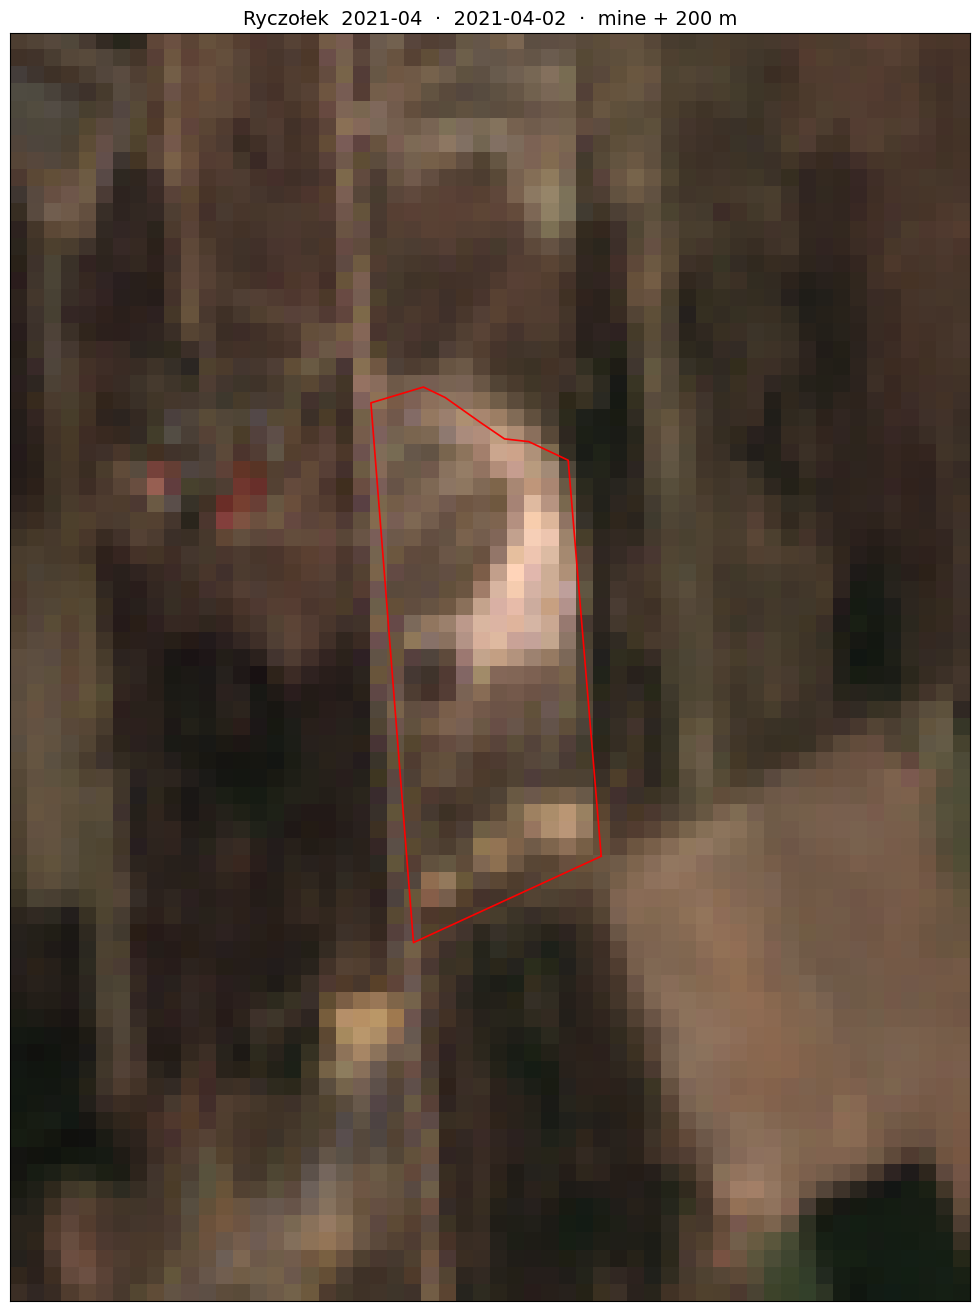

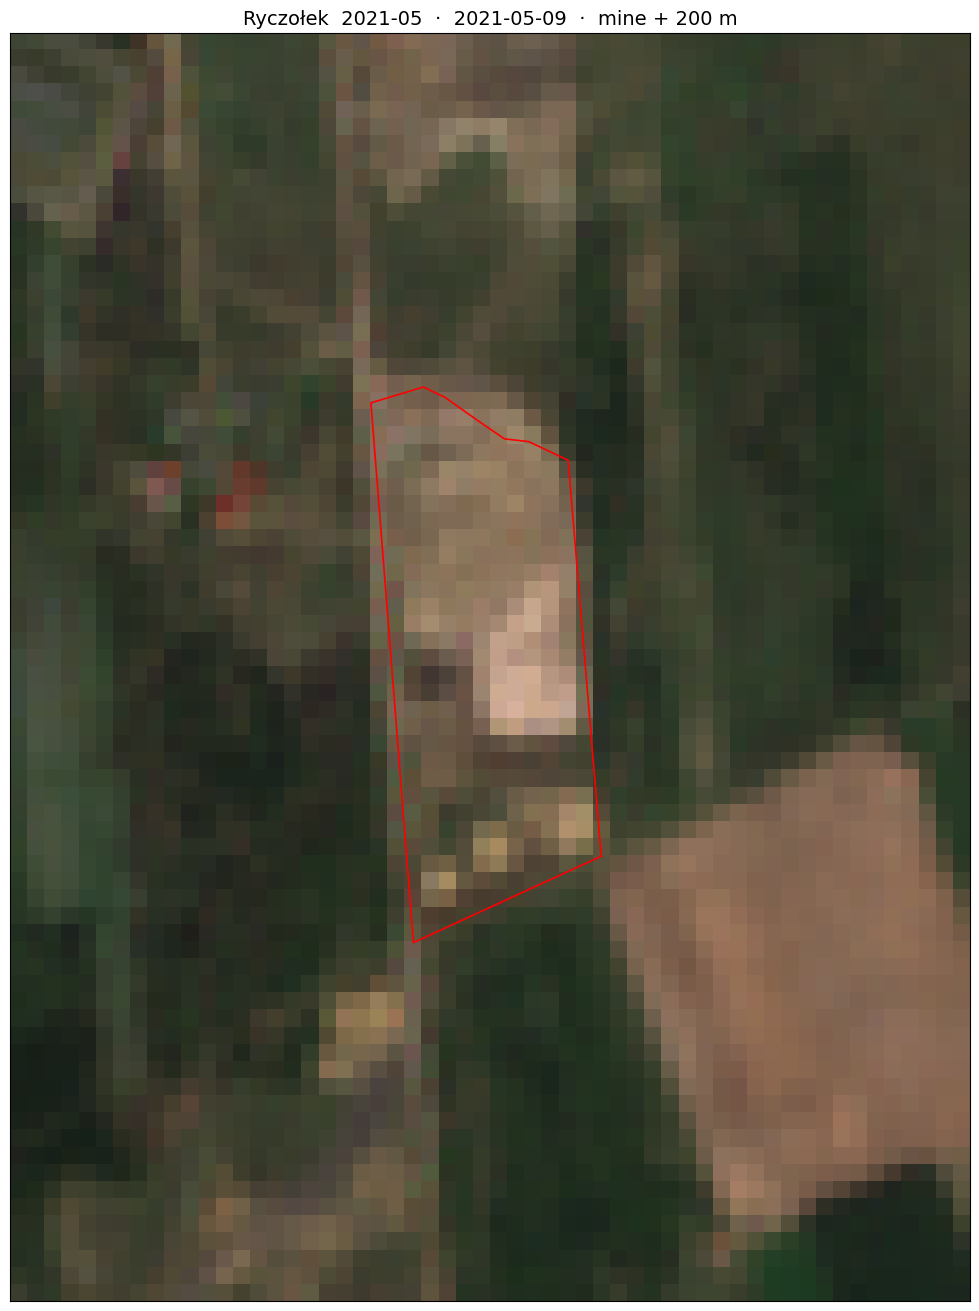

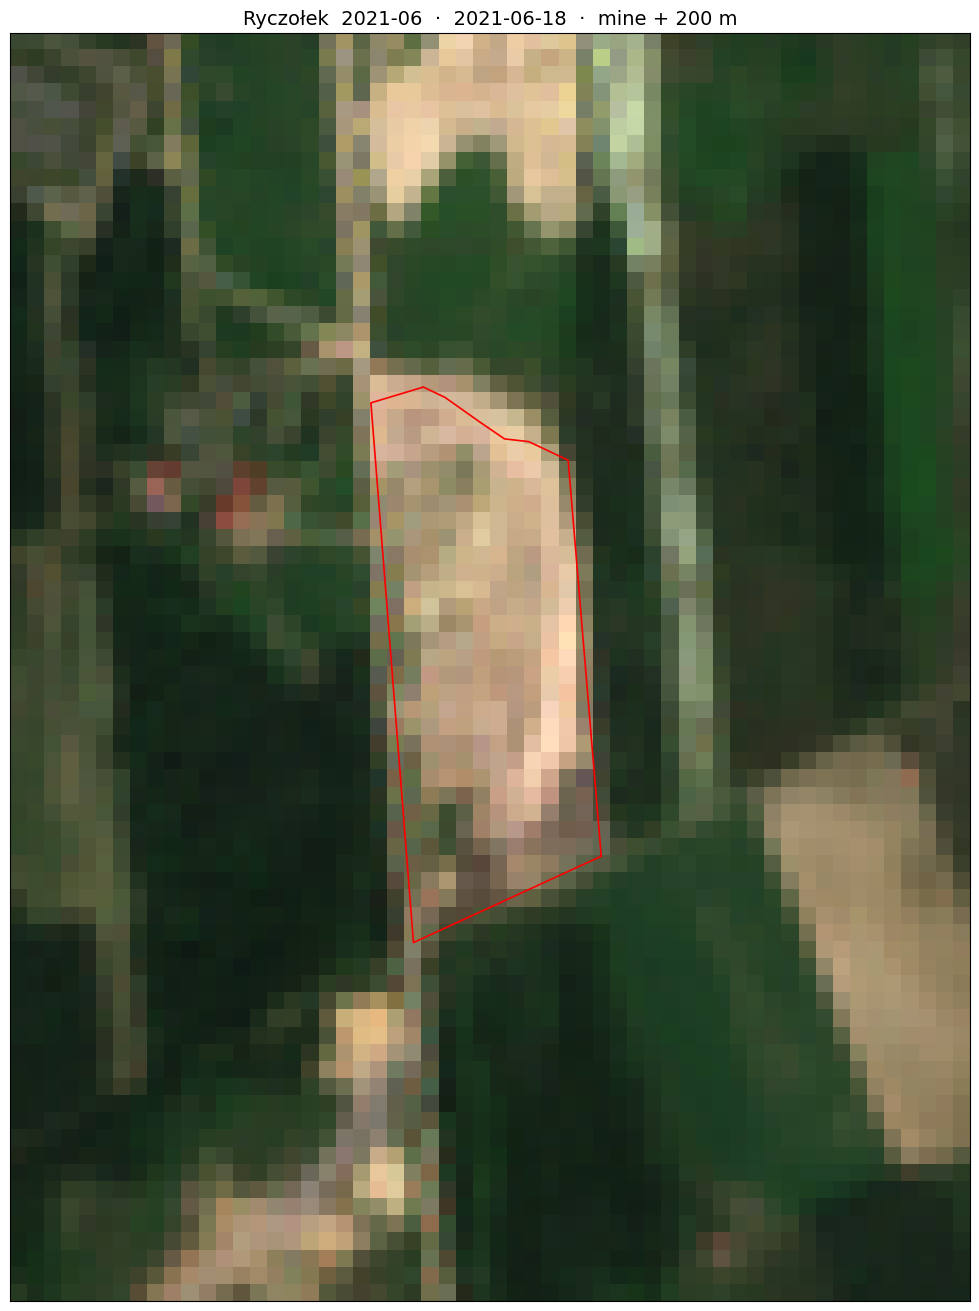

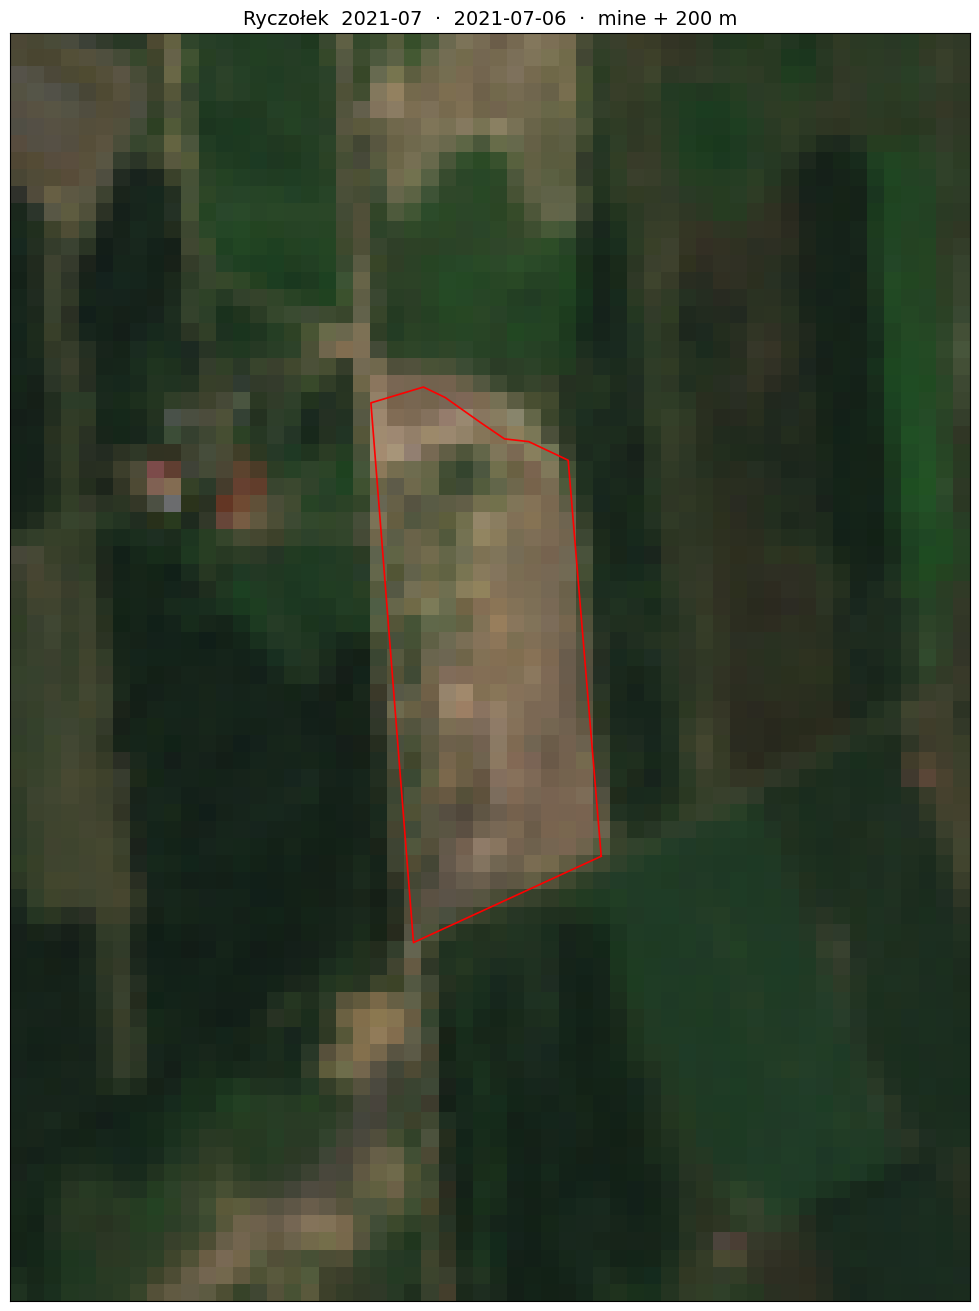

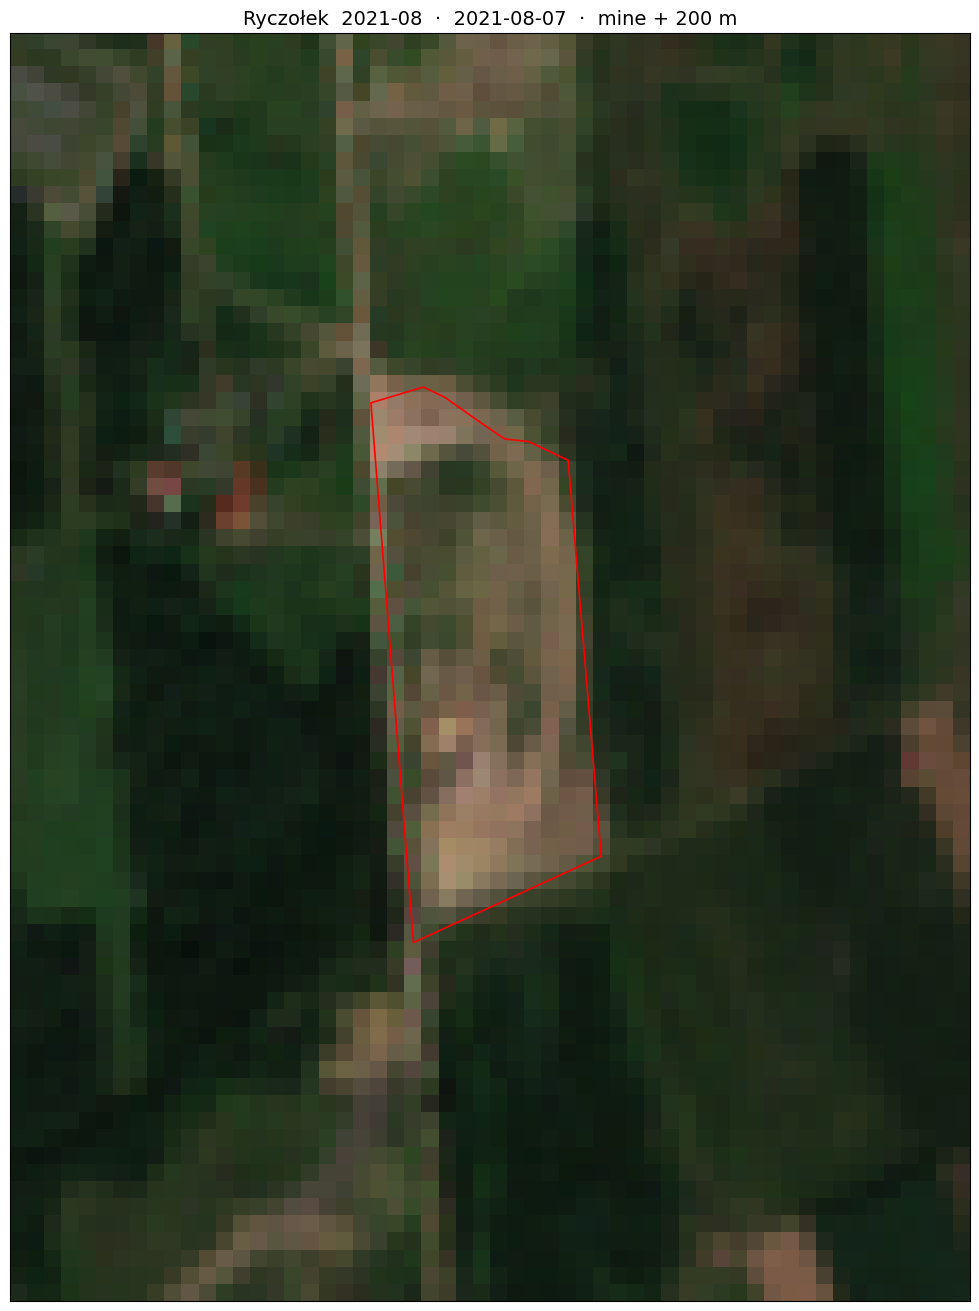

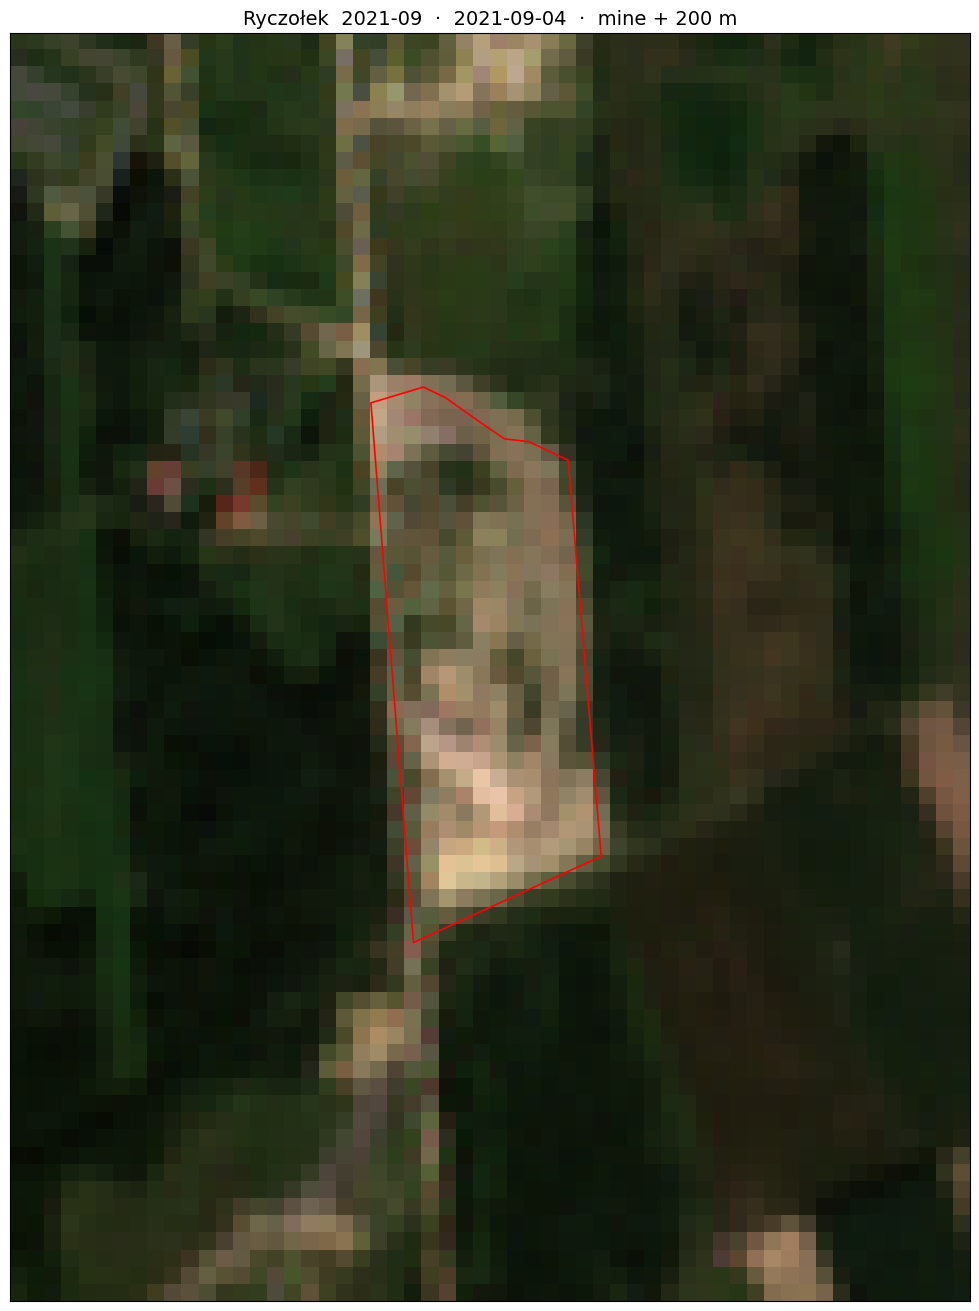

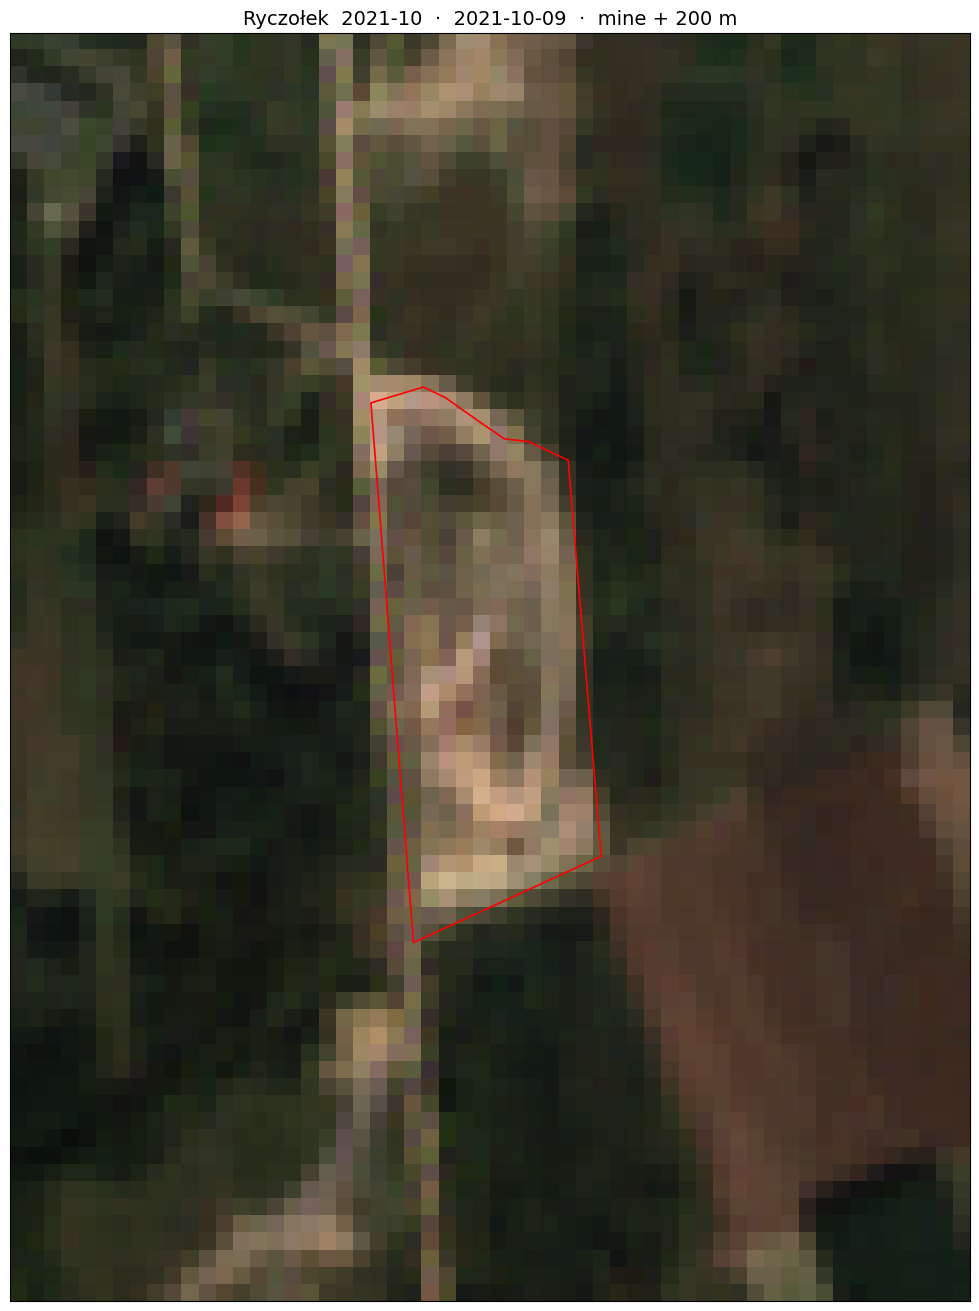

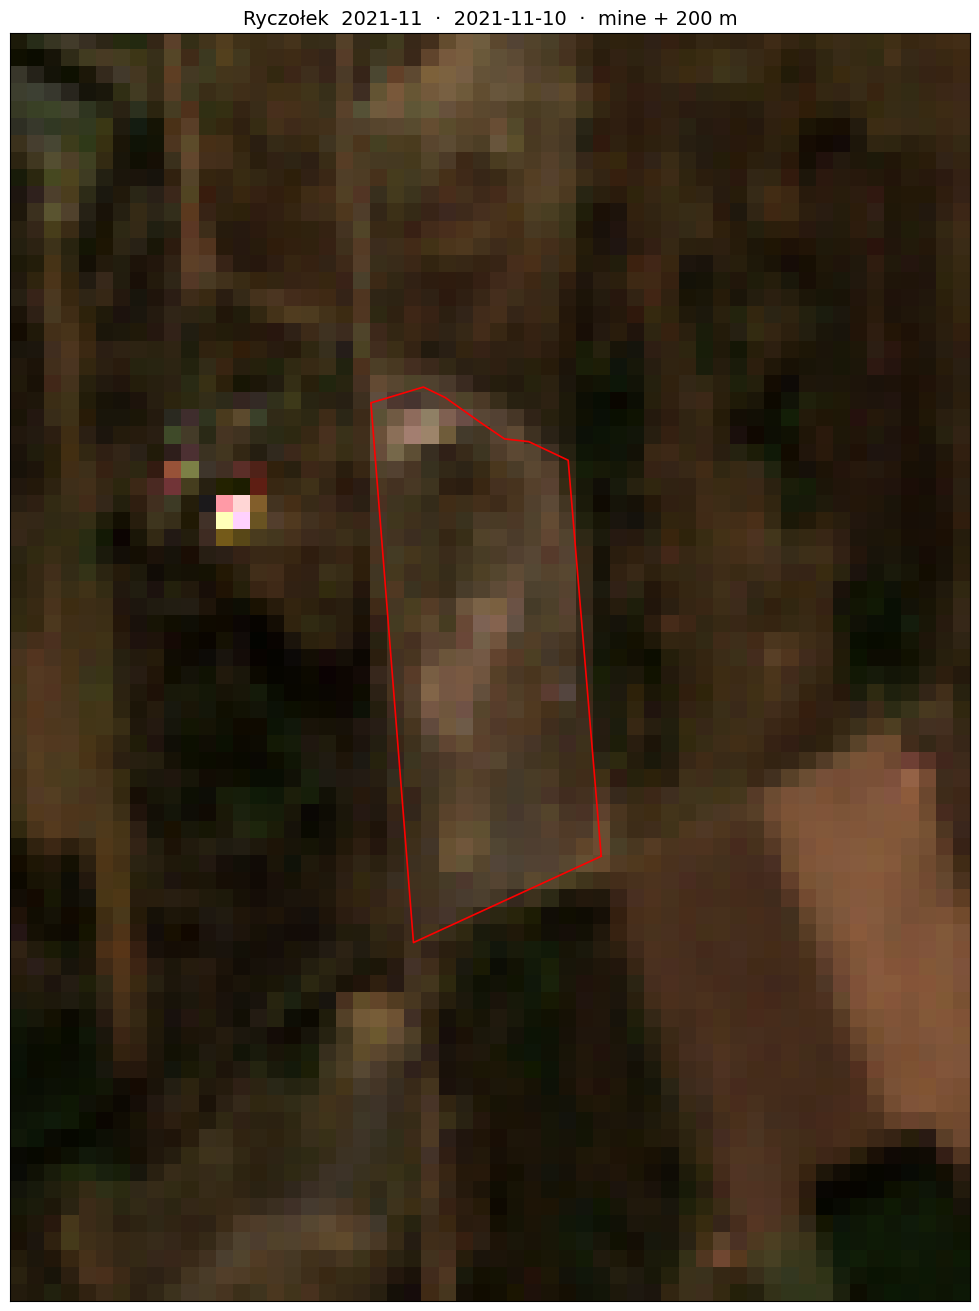

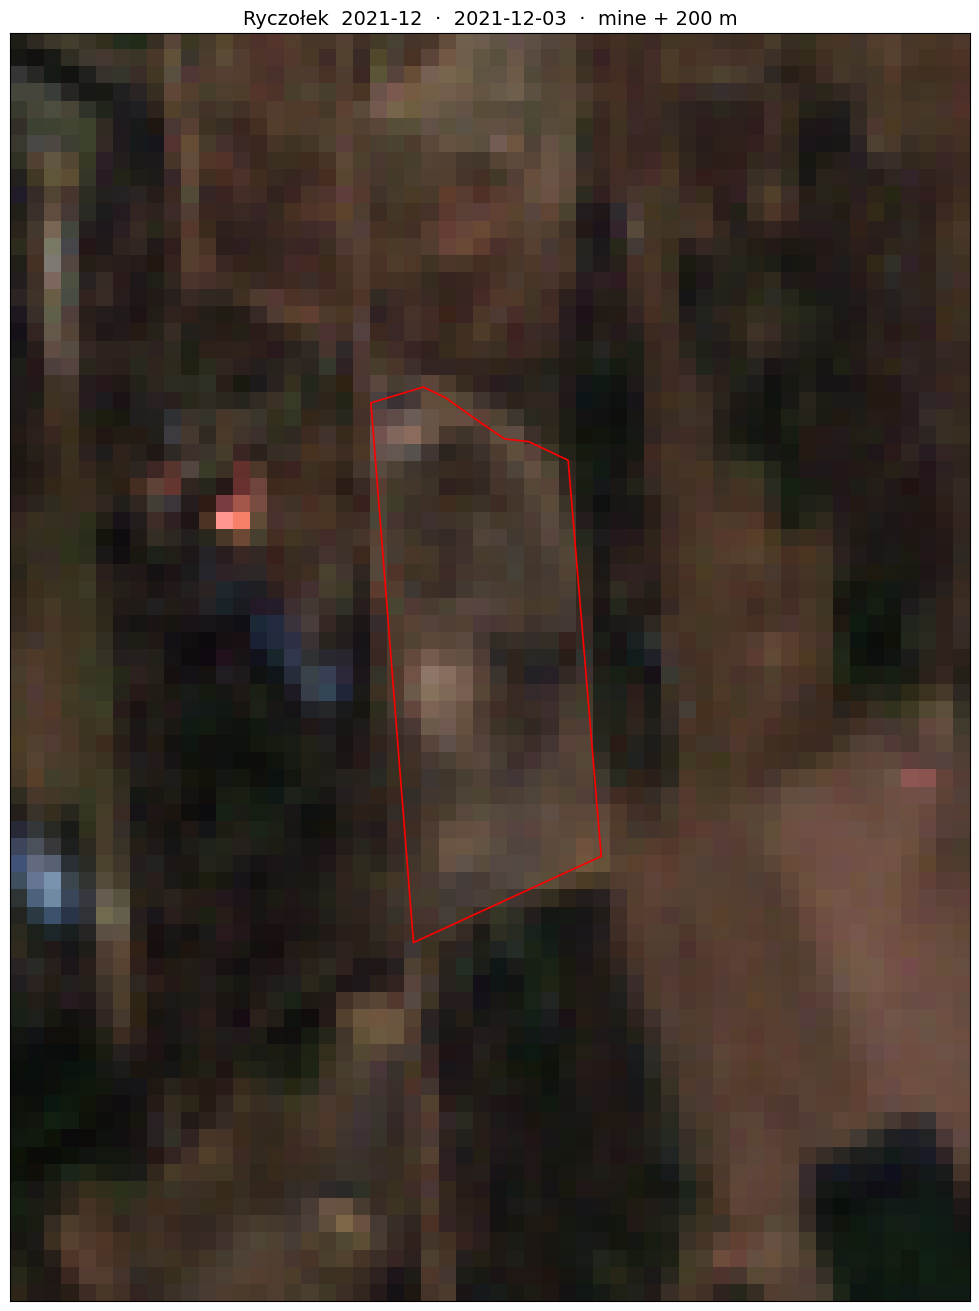

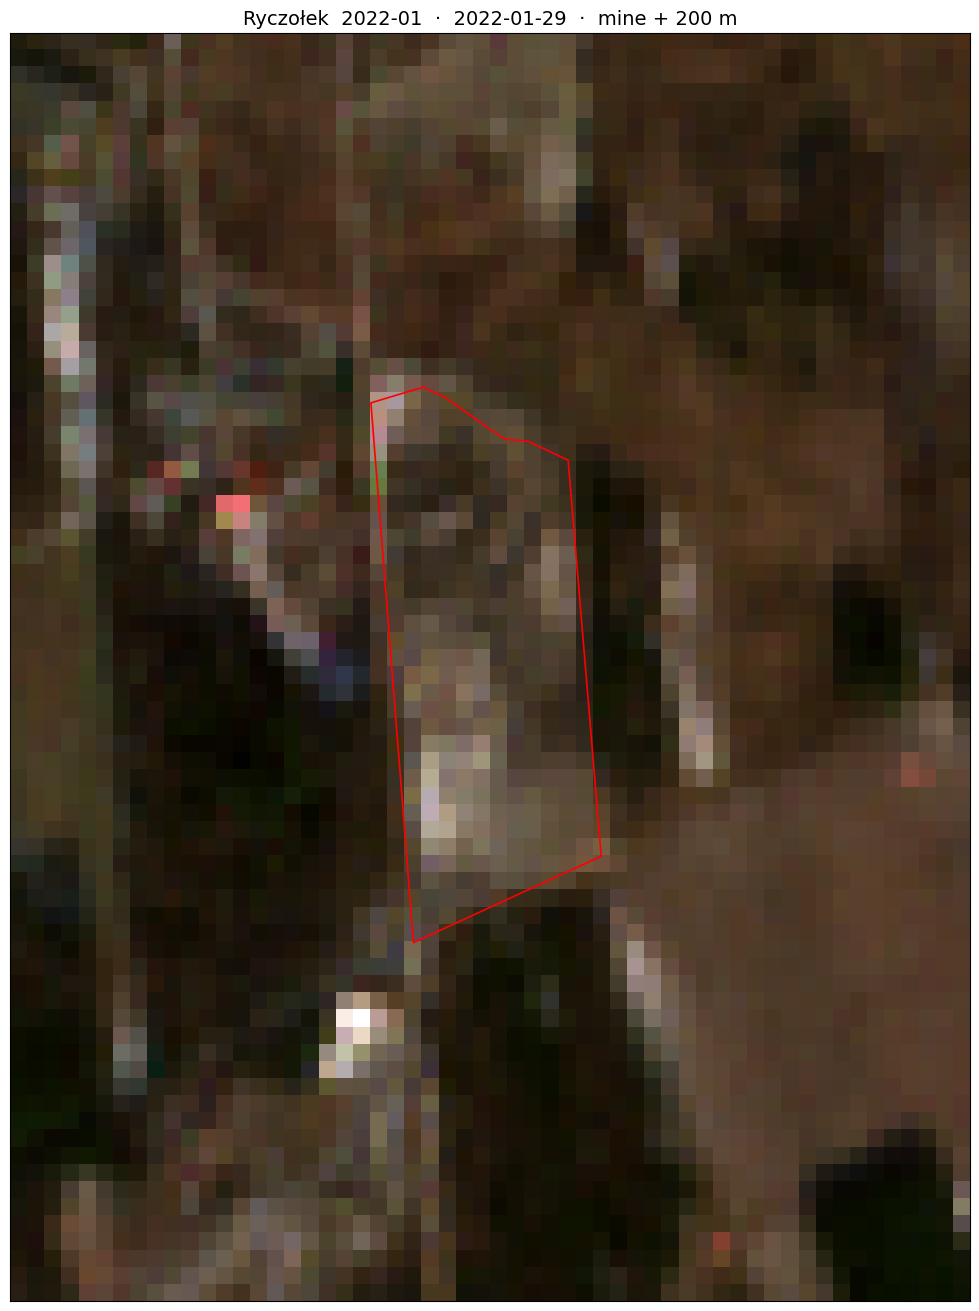

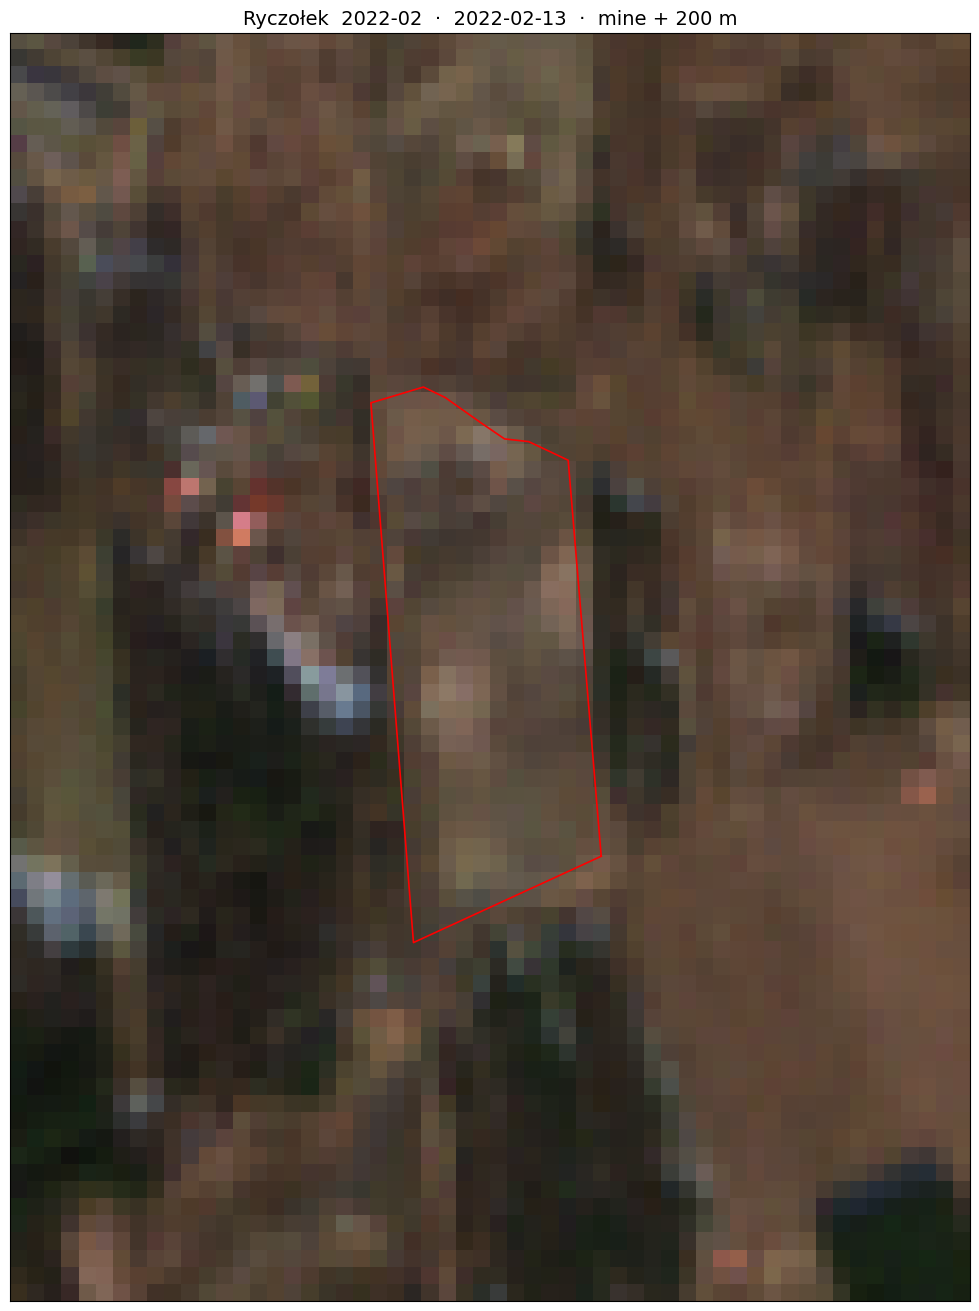

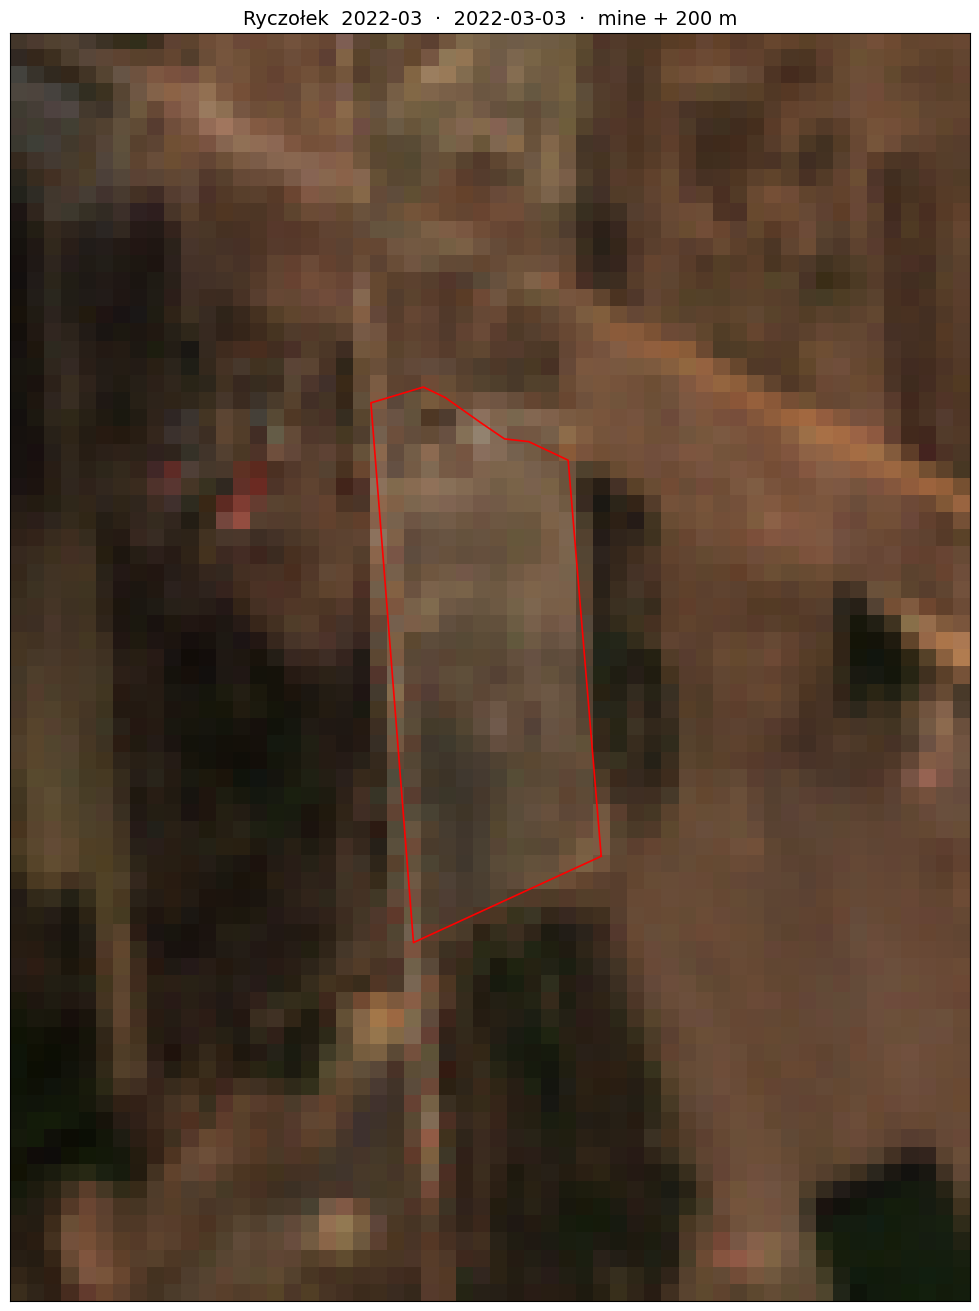

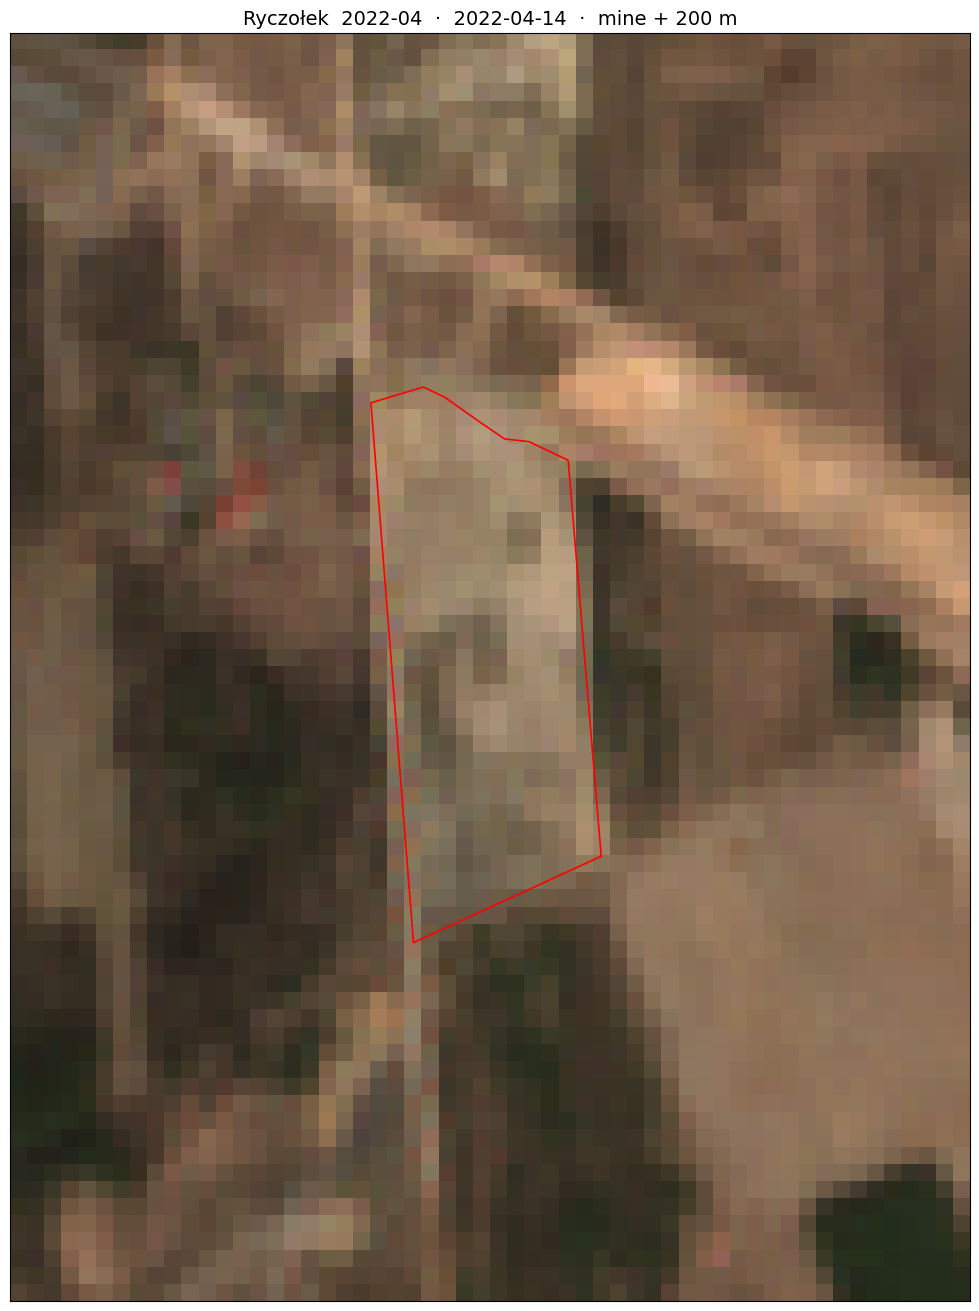

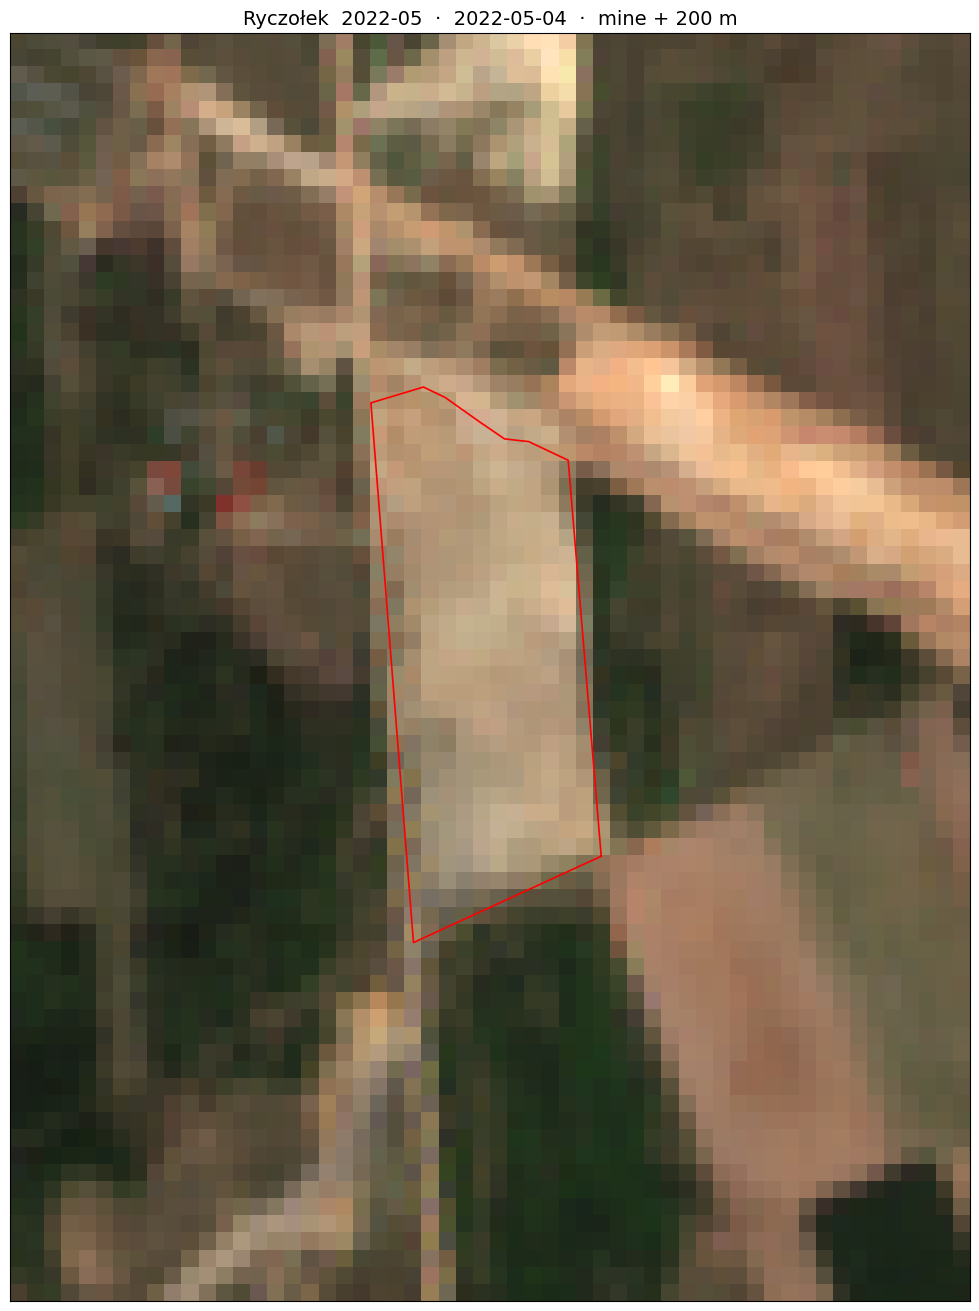

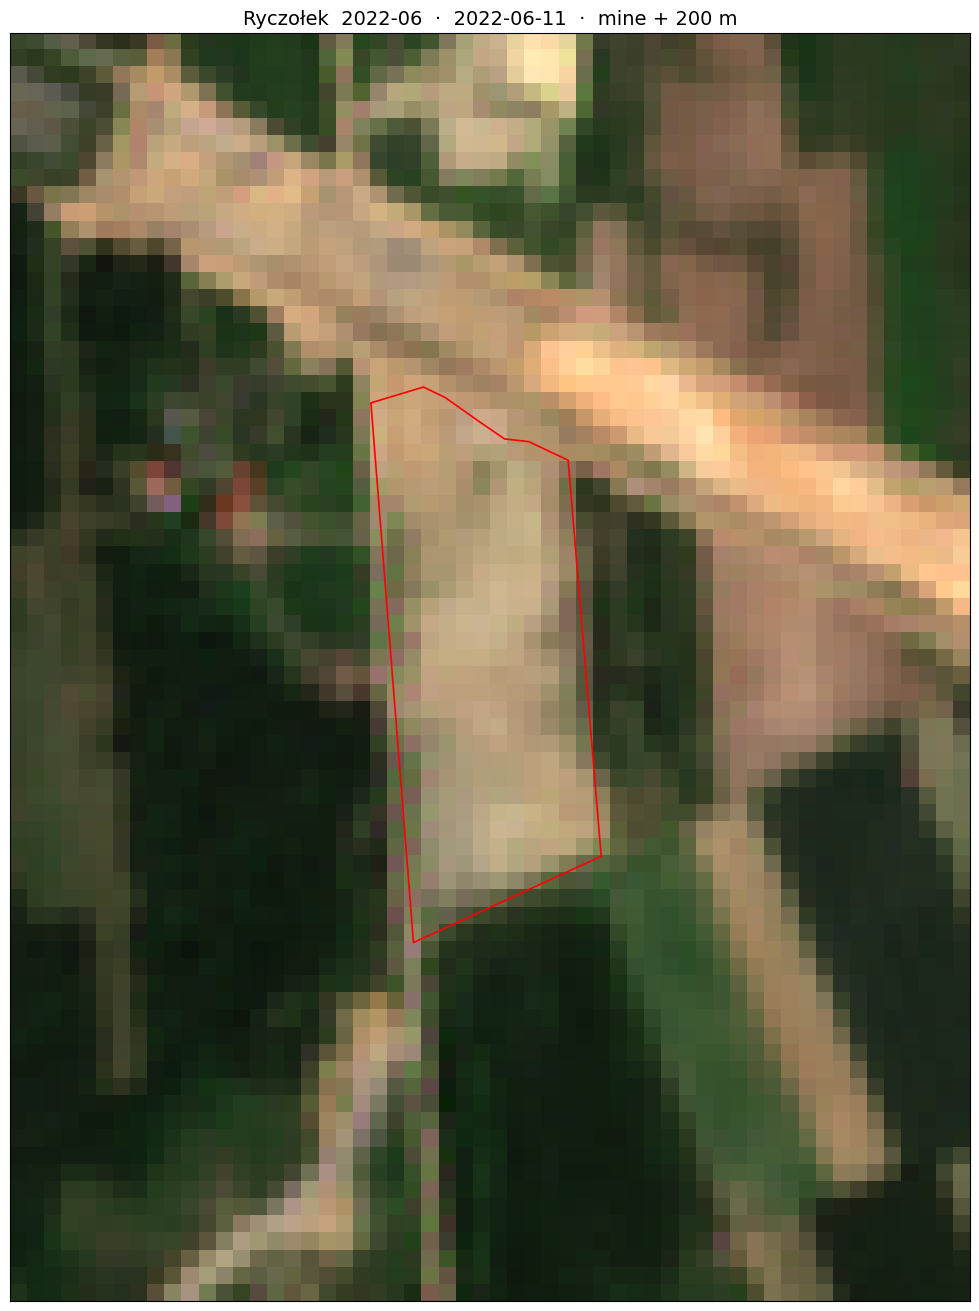

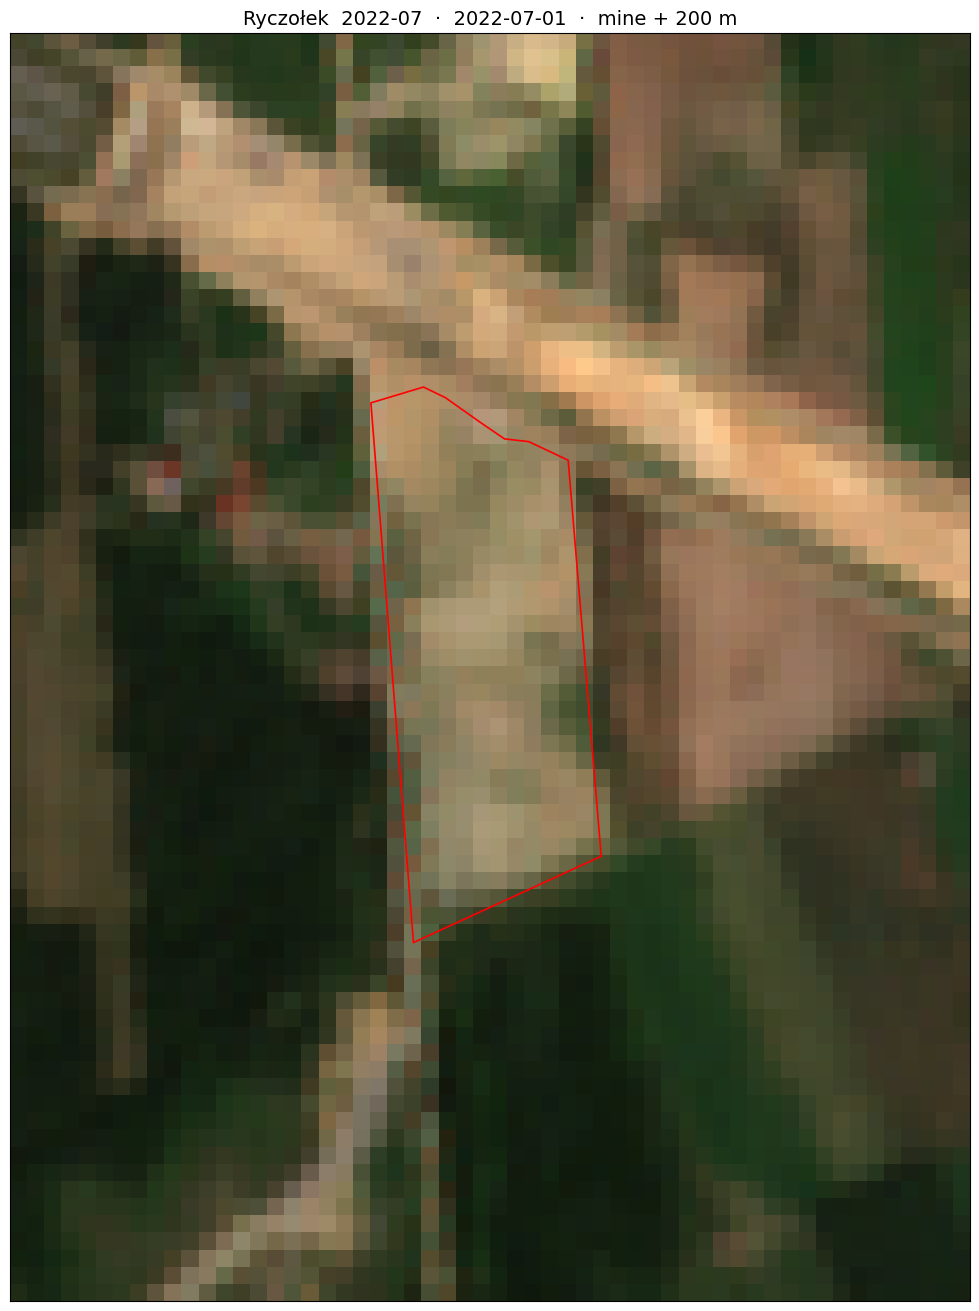

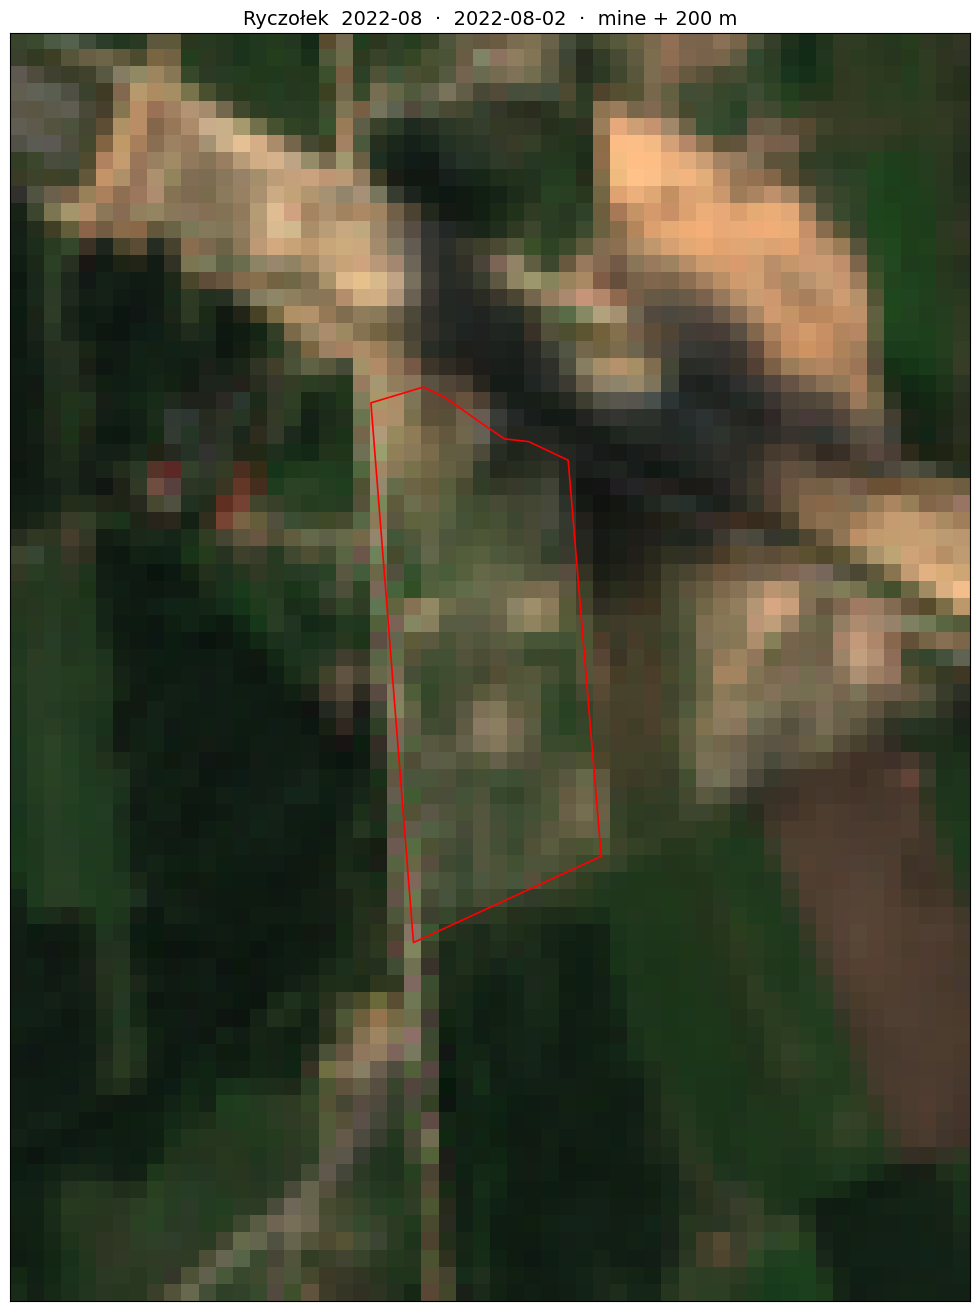

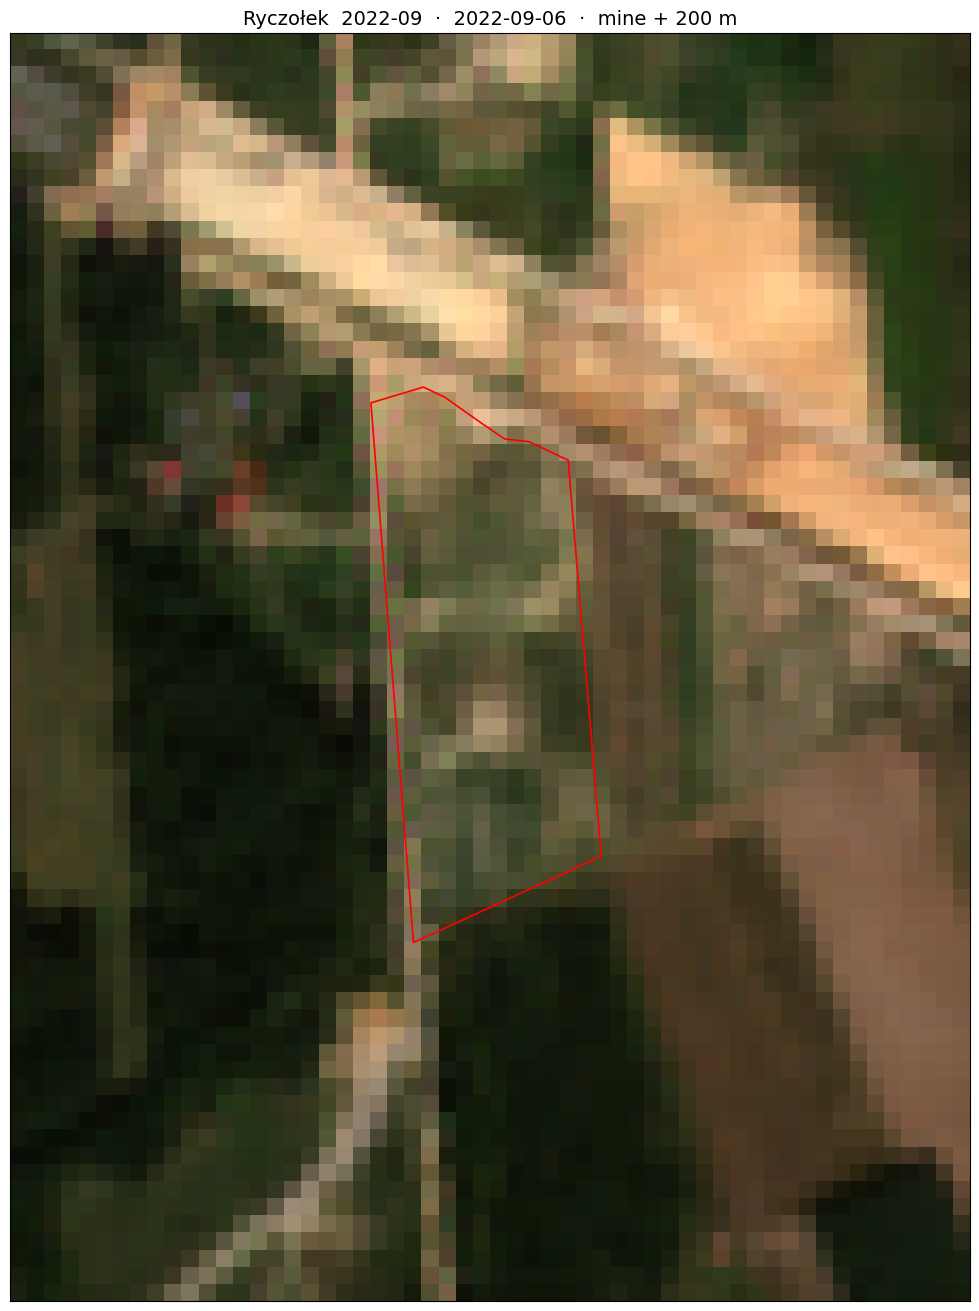

2022-10  no cloud-free scene


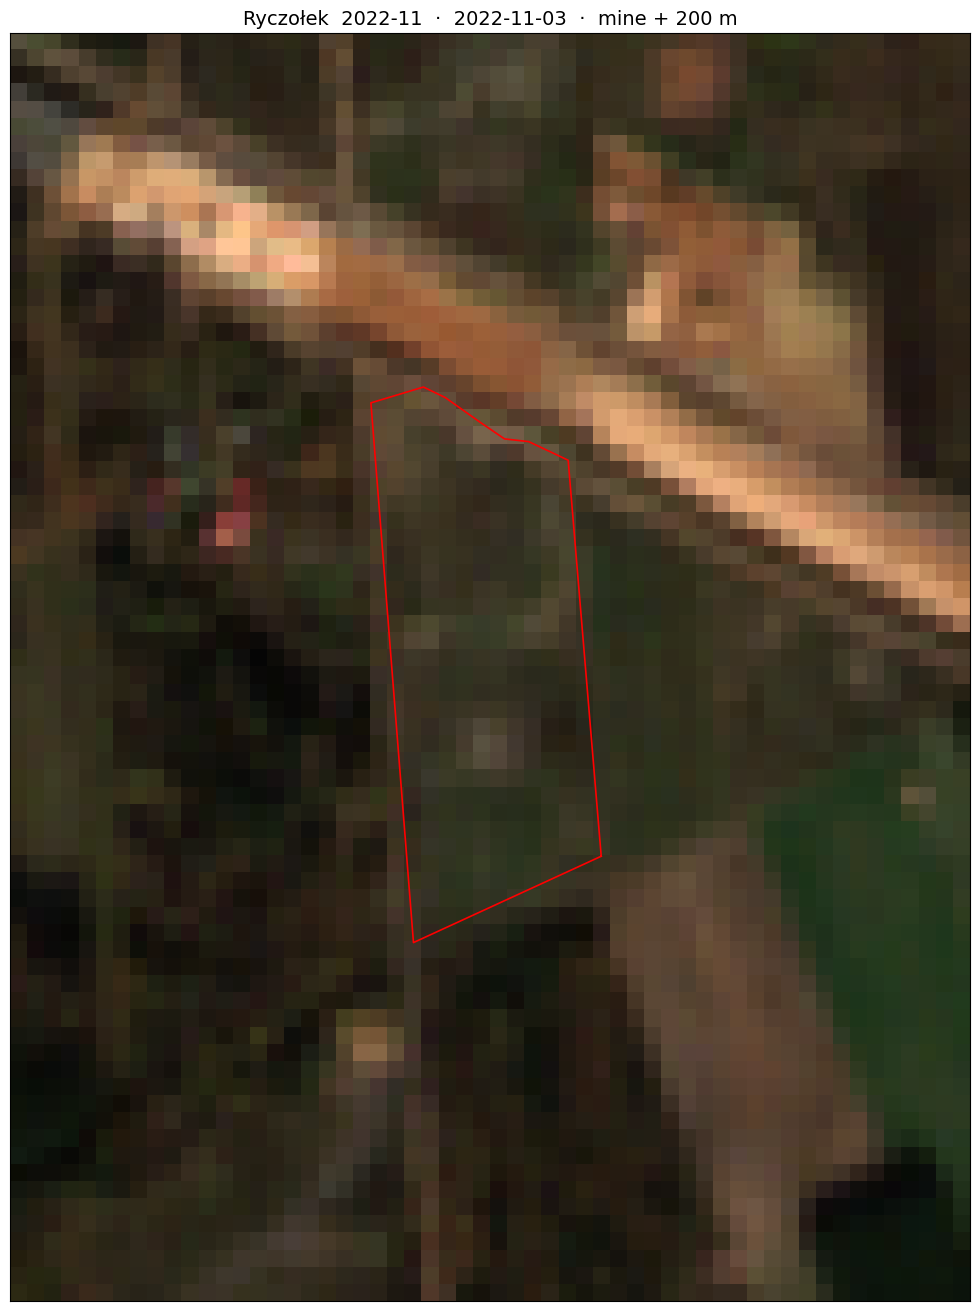

2022-12  no cloud-free scene


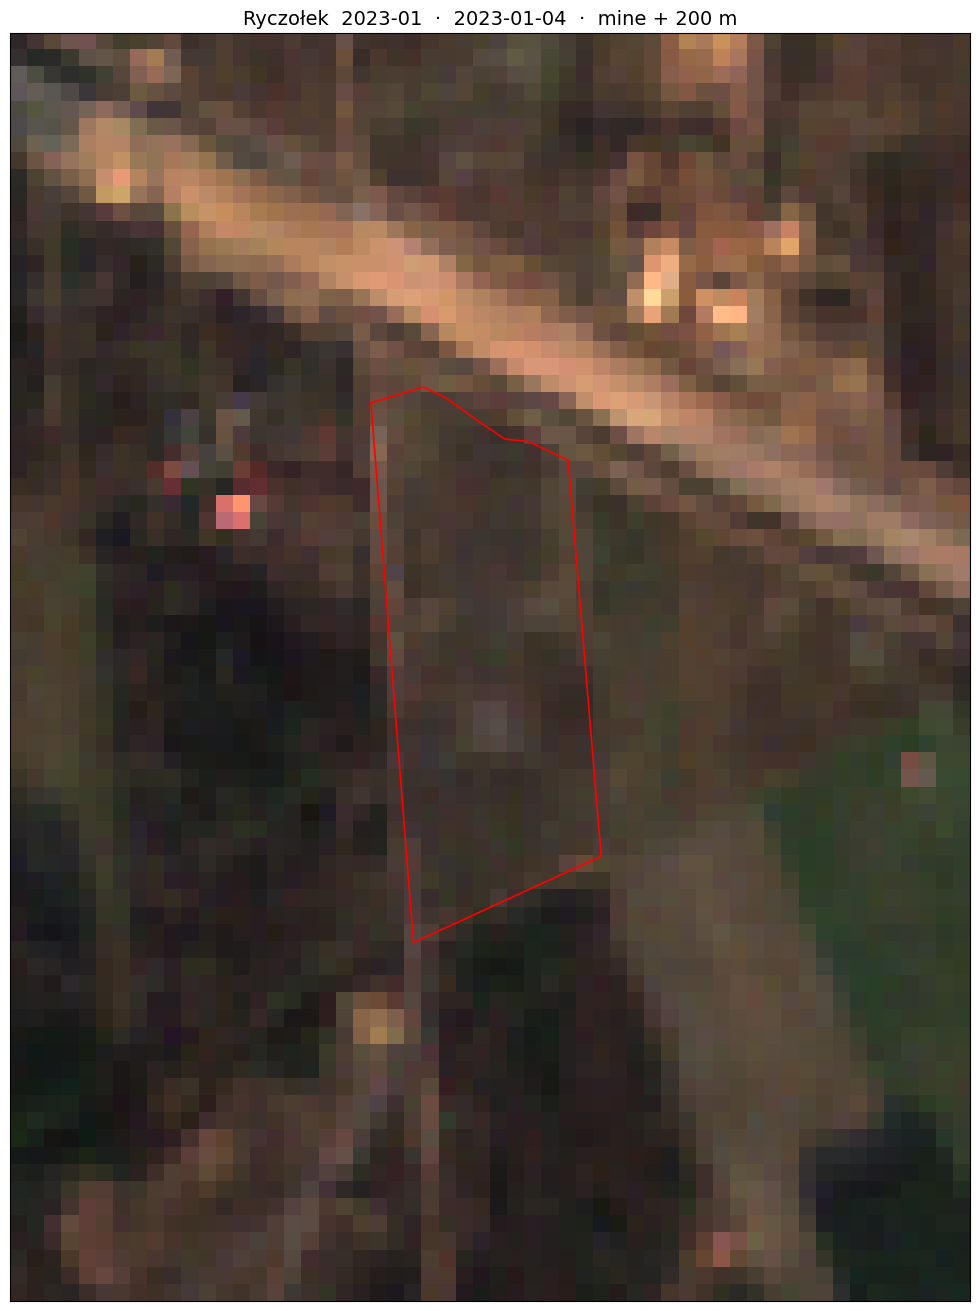

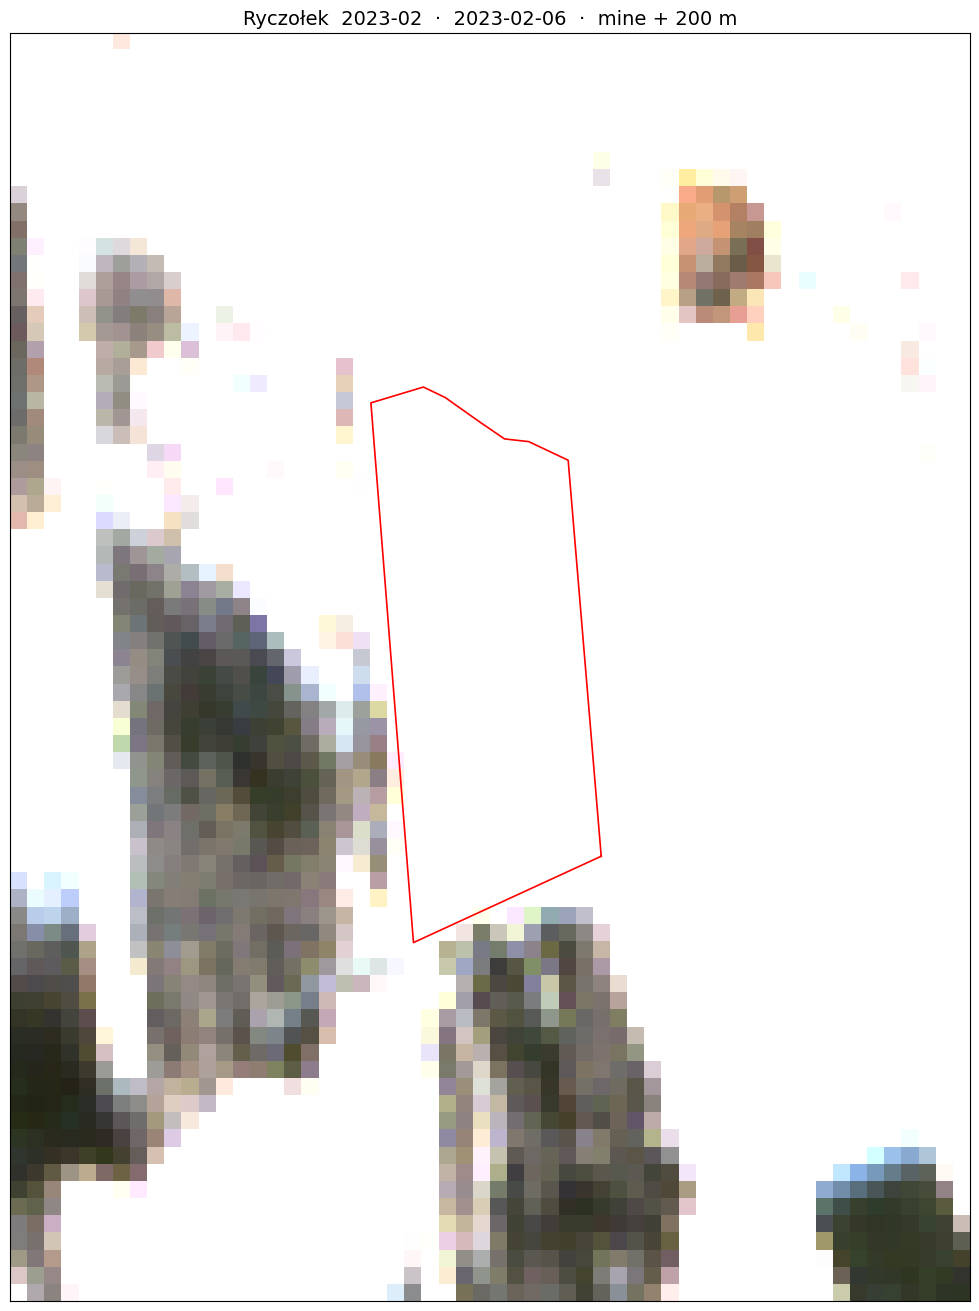

2023-03  no cloud-free scene


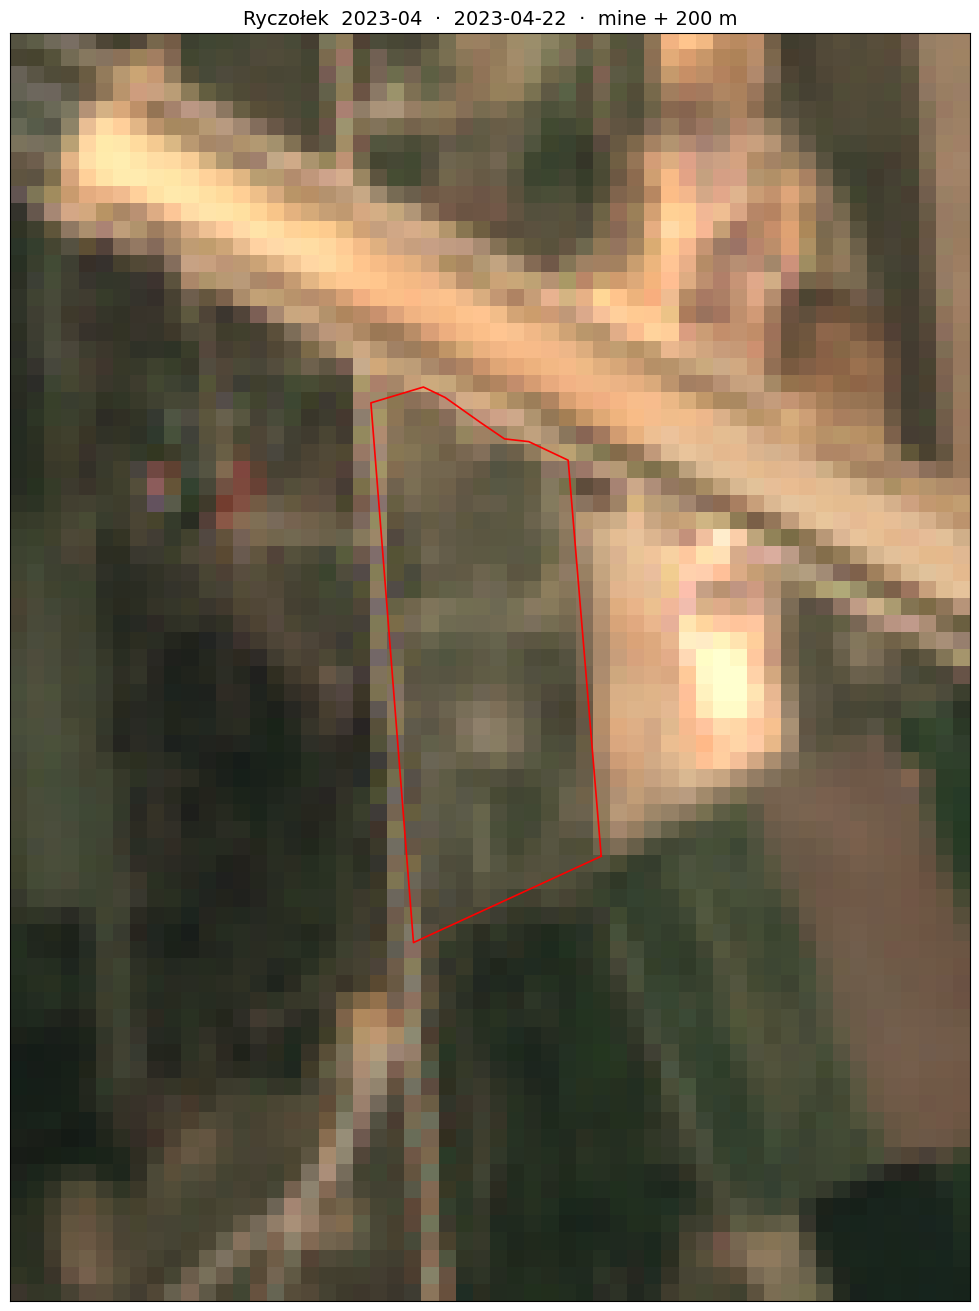

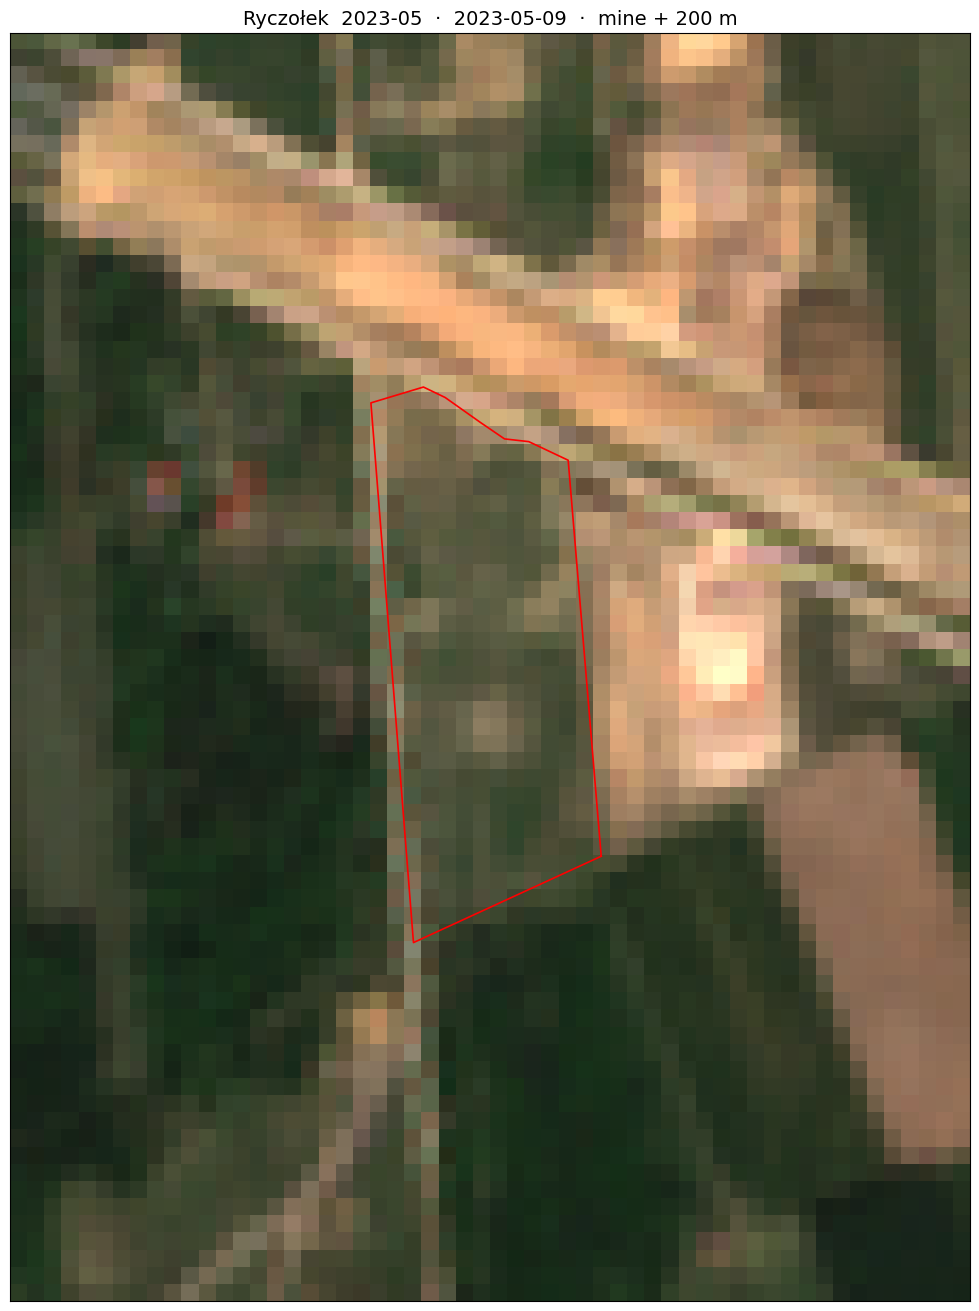

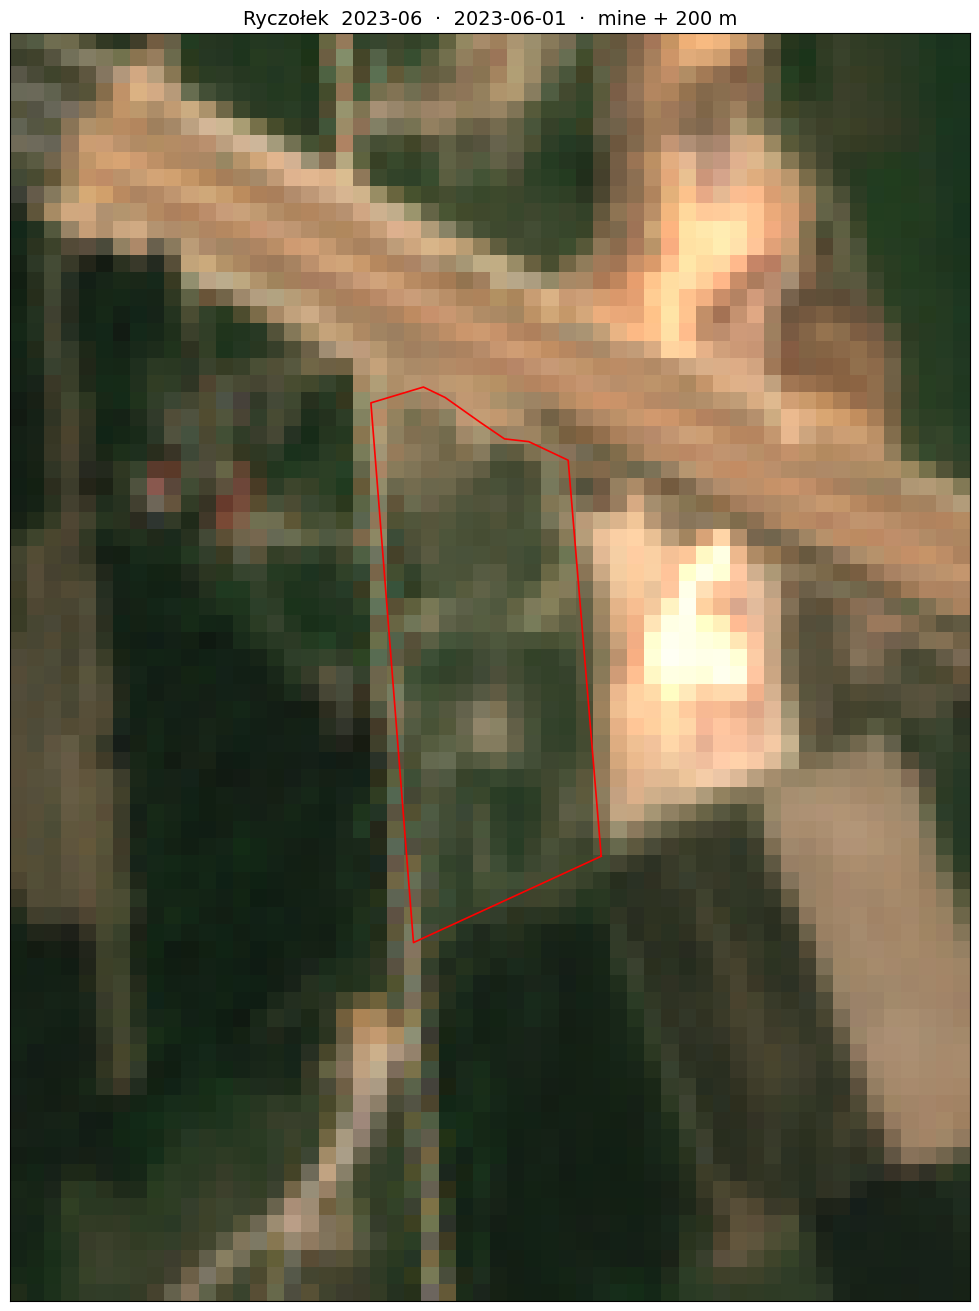

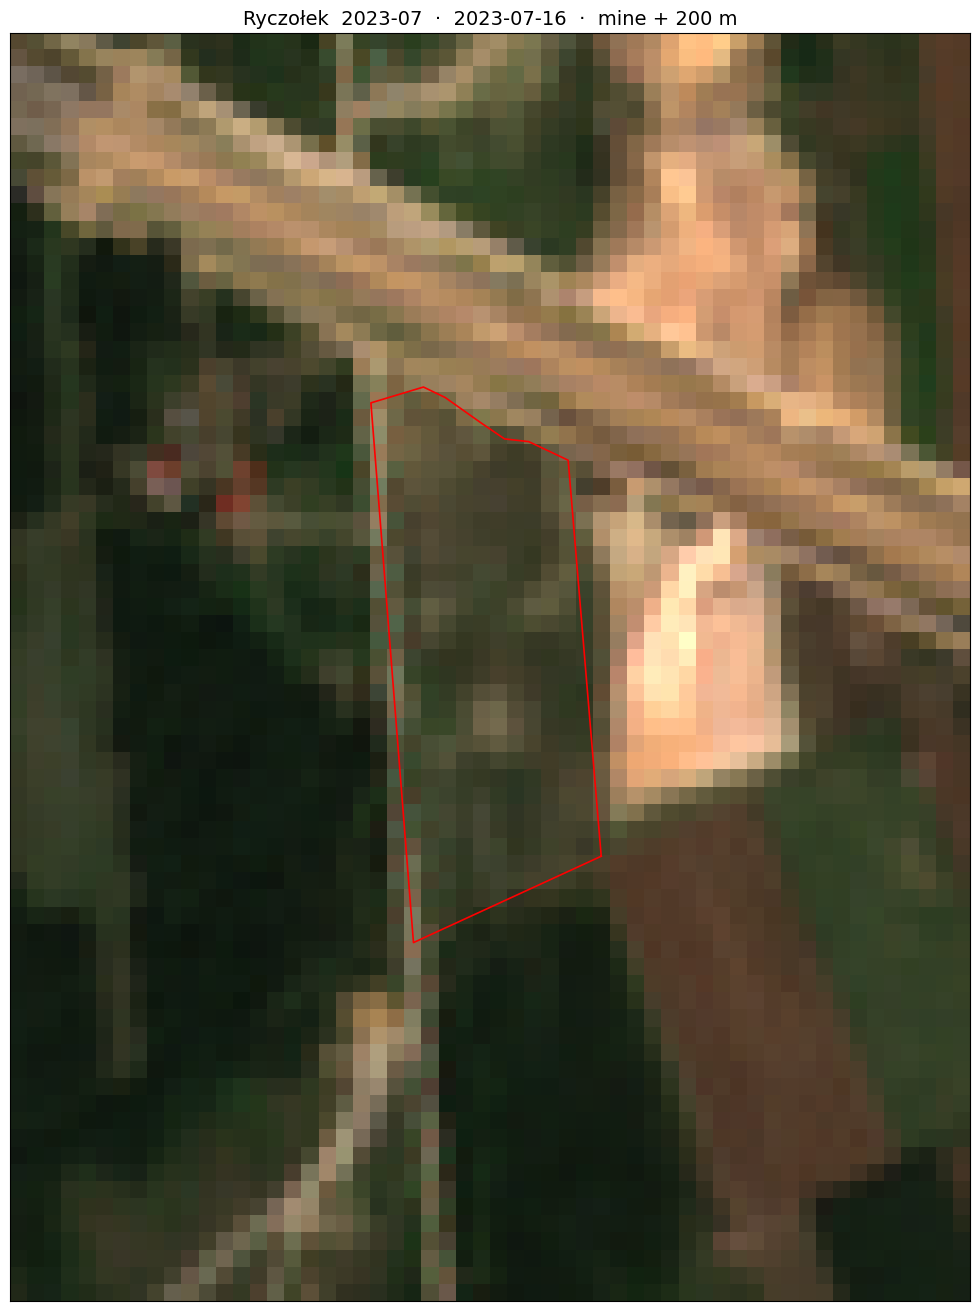

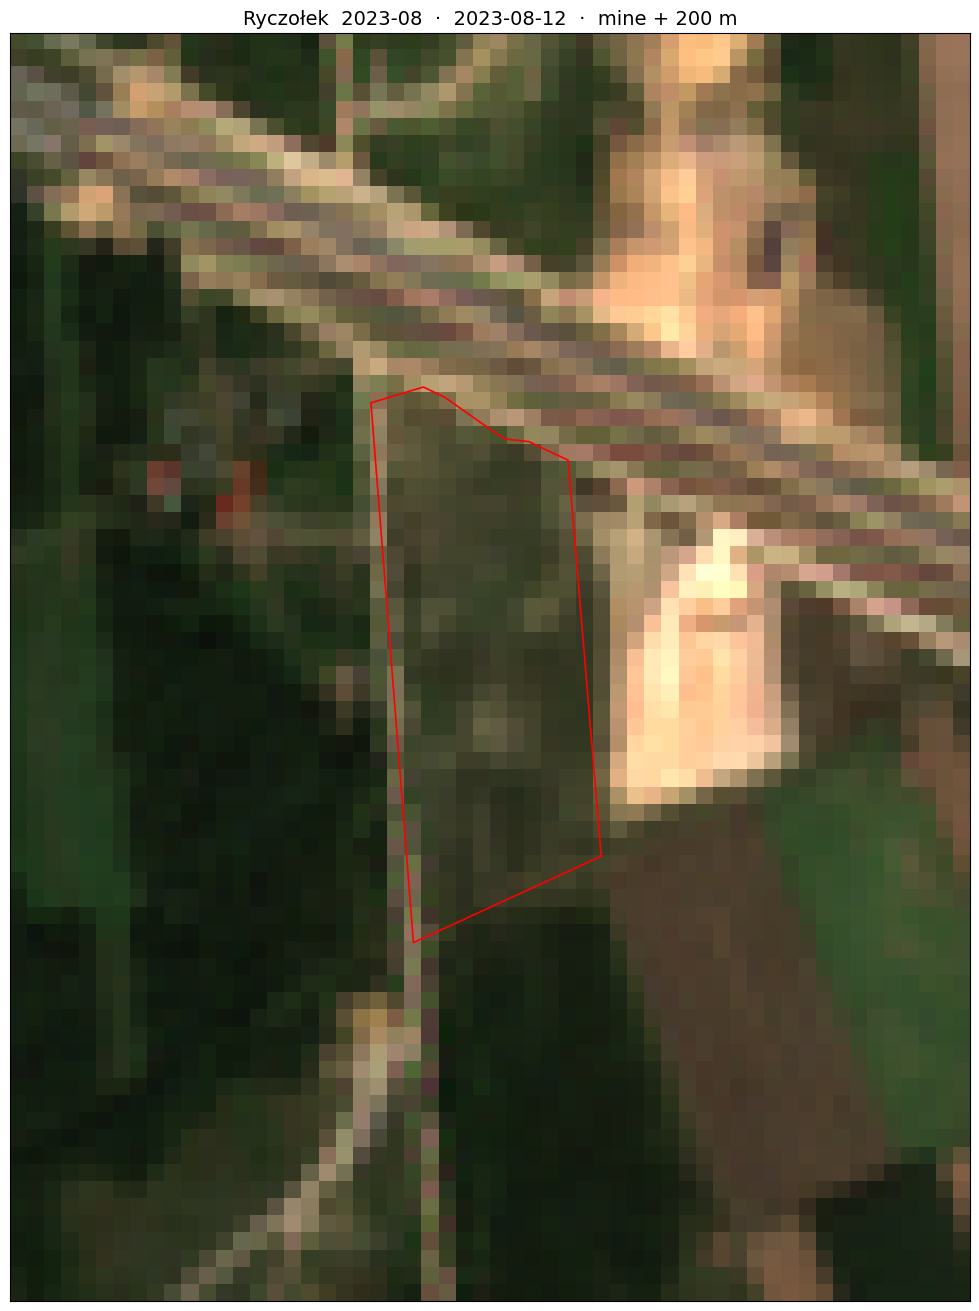

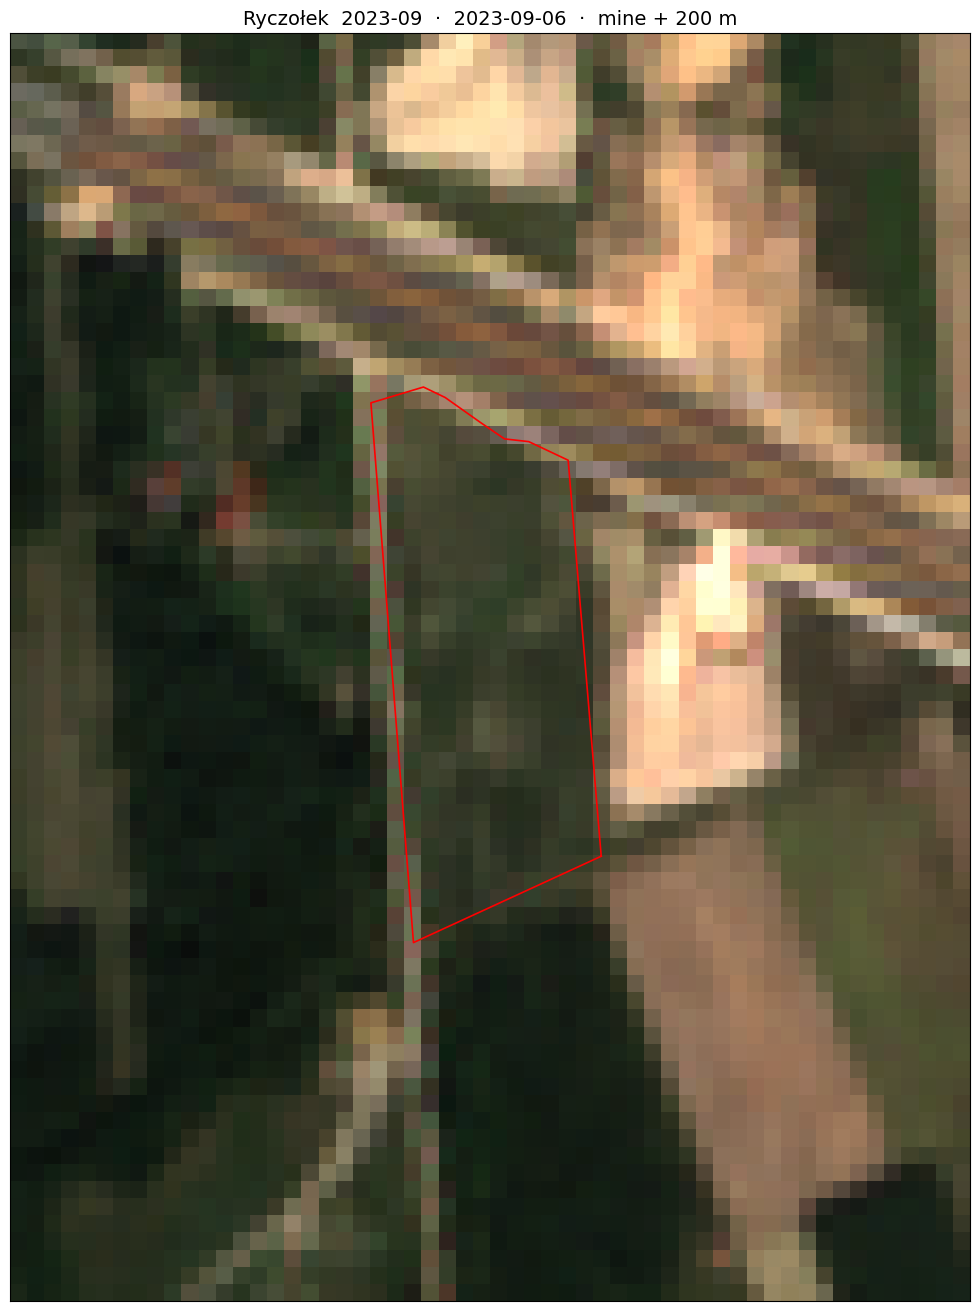

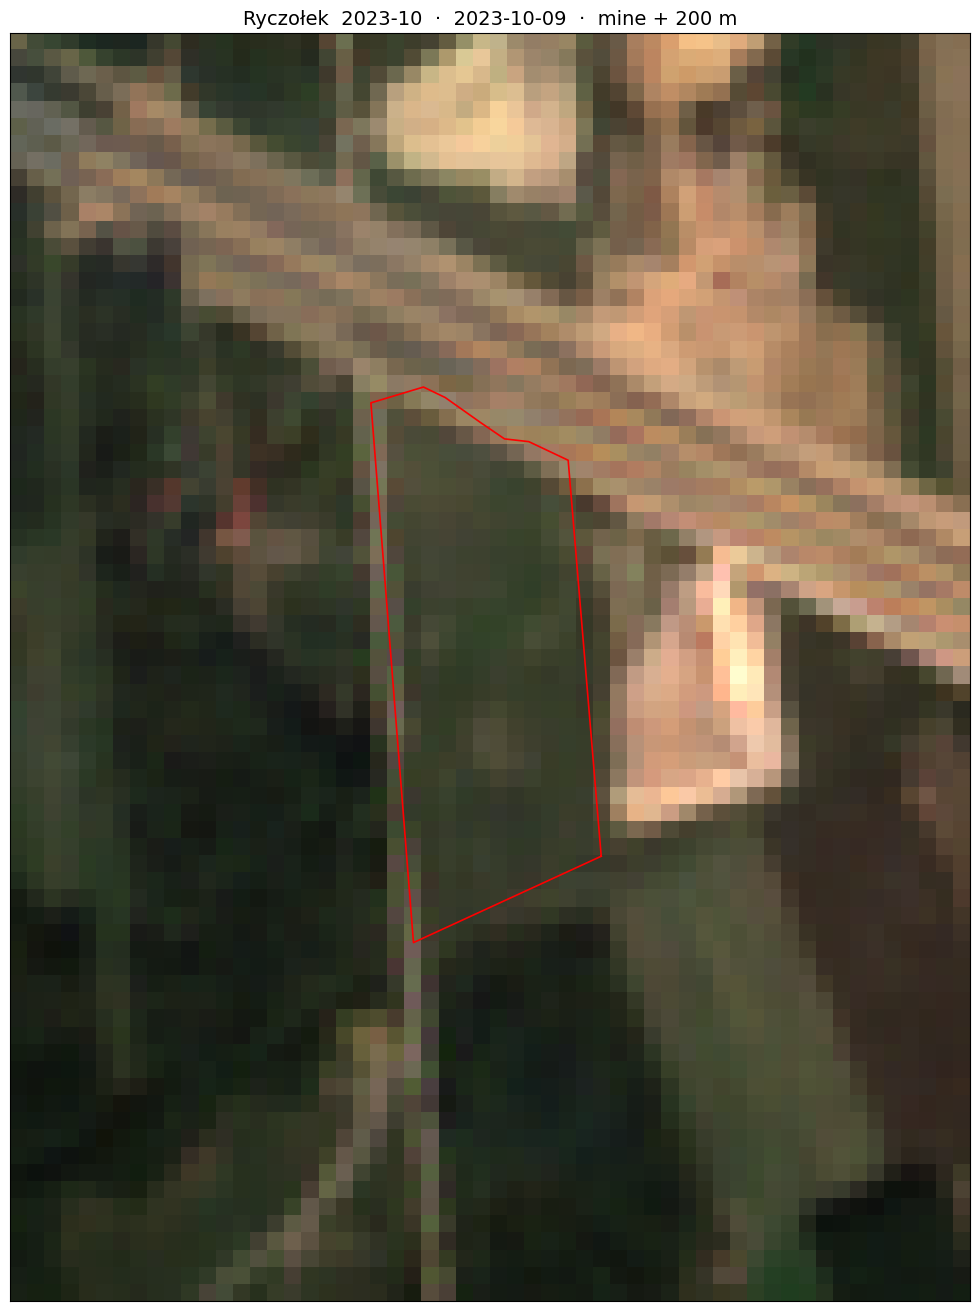

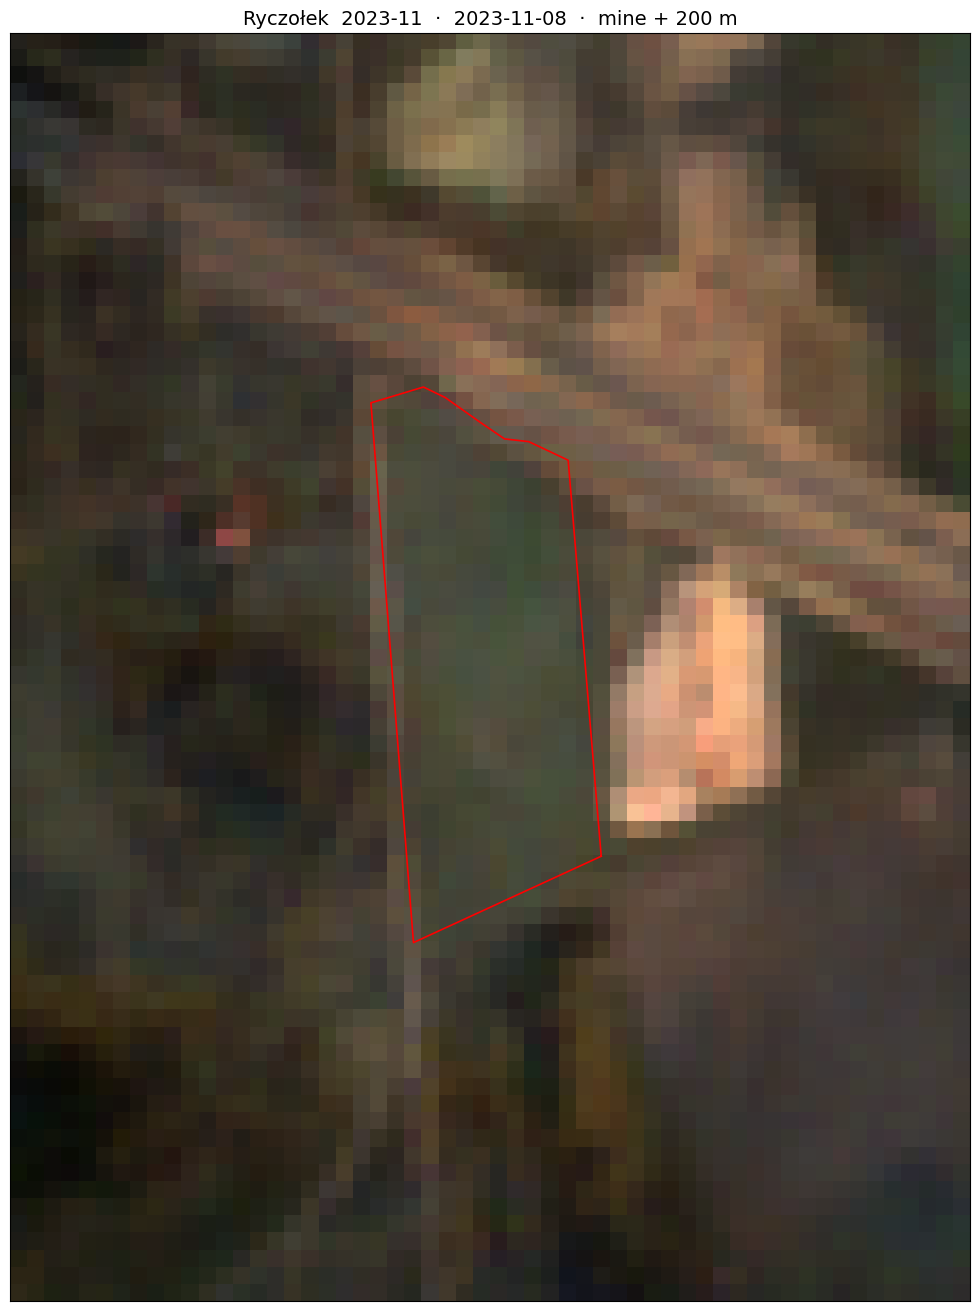

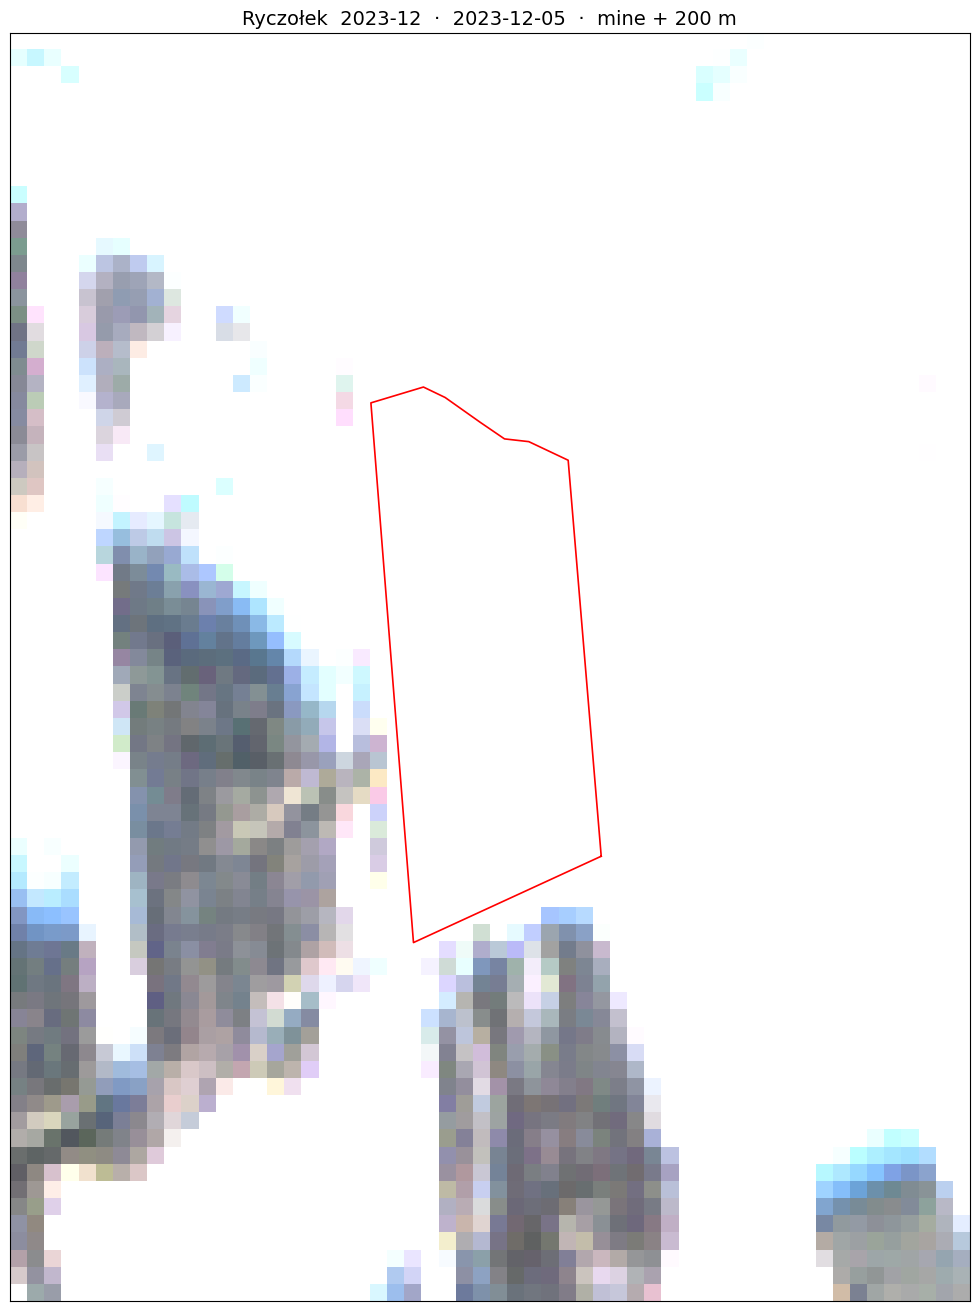

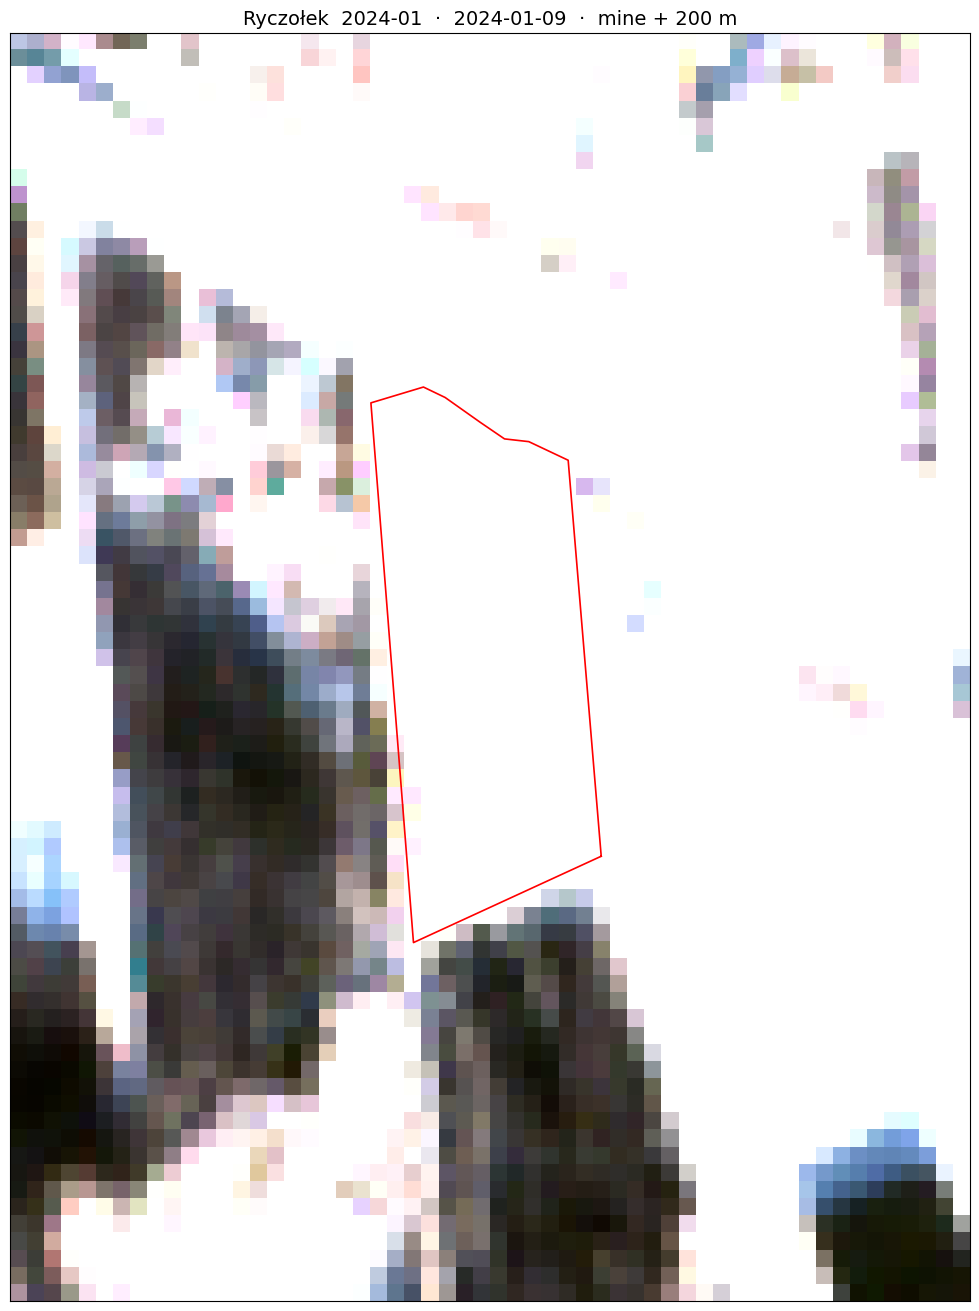

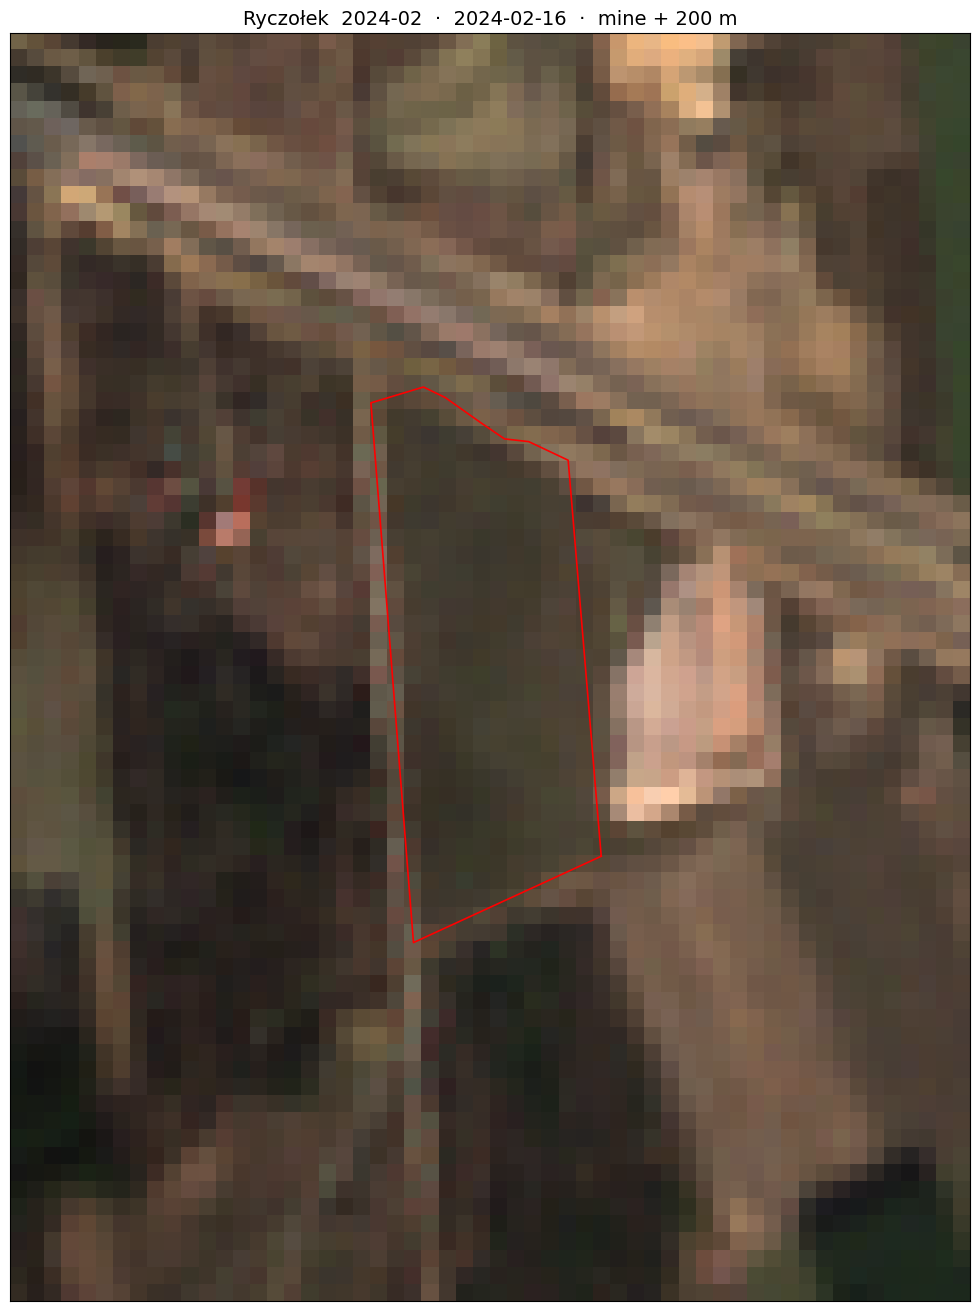

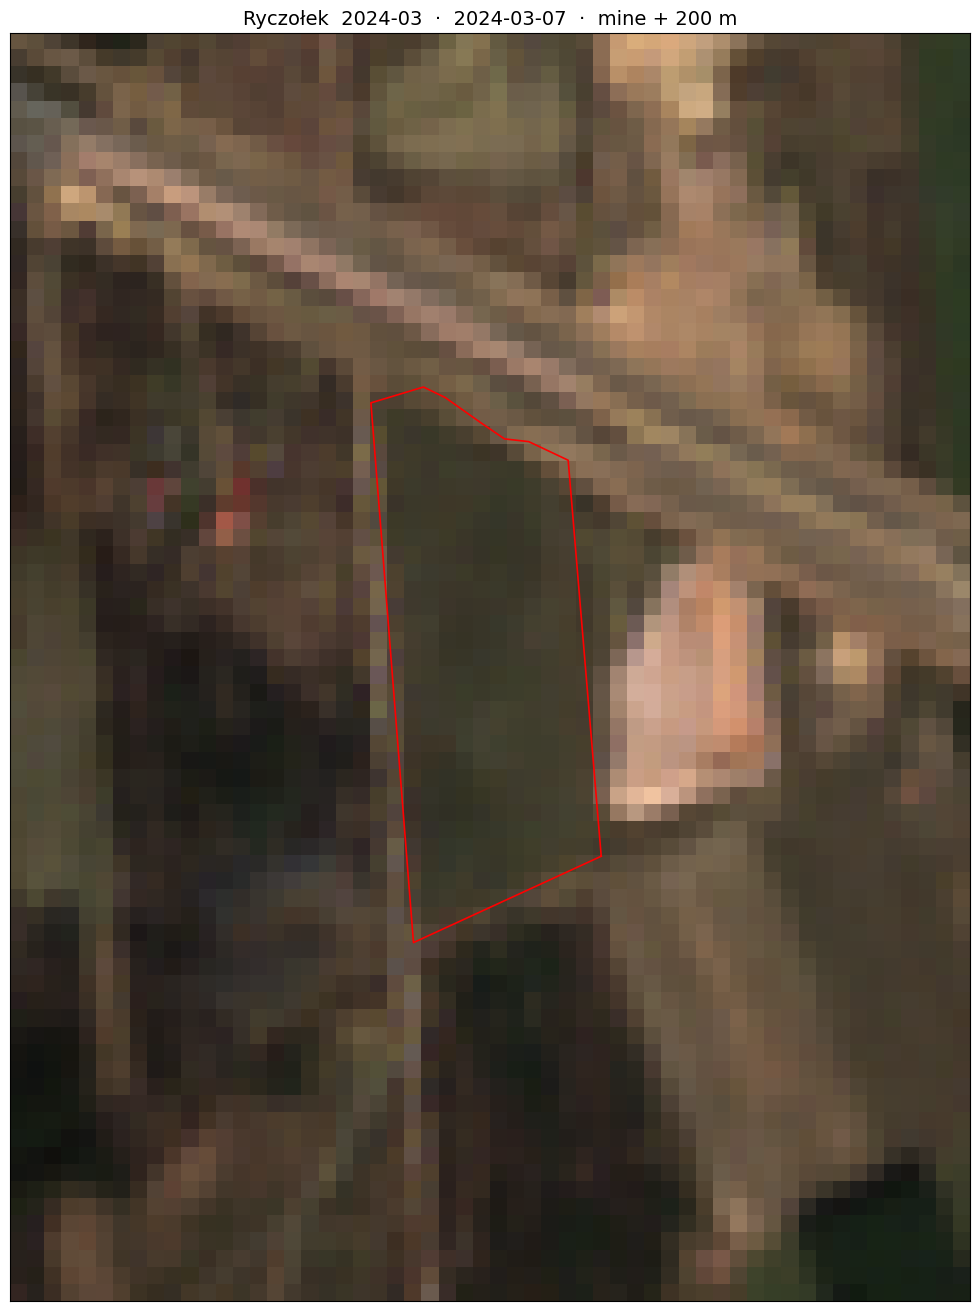

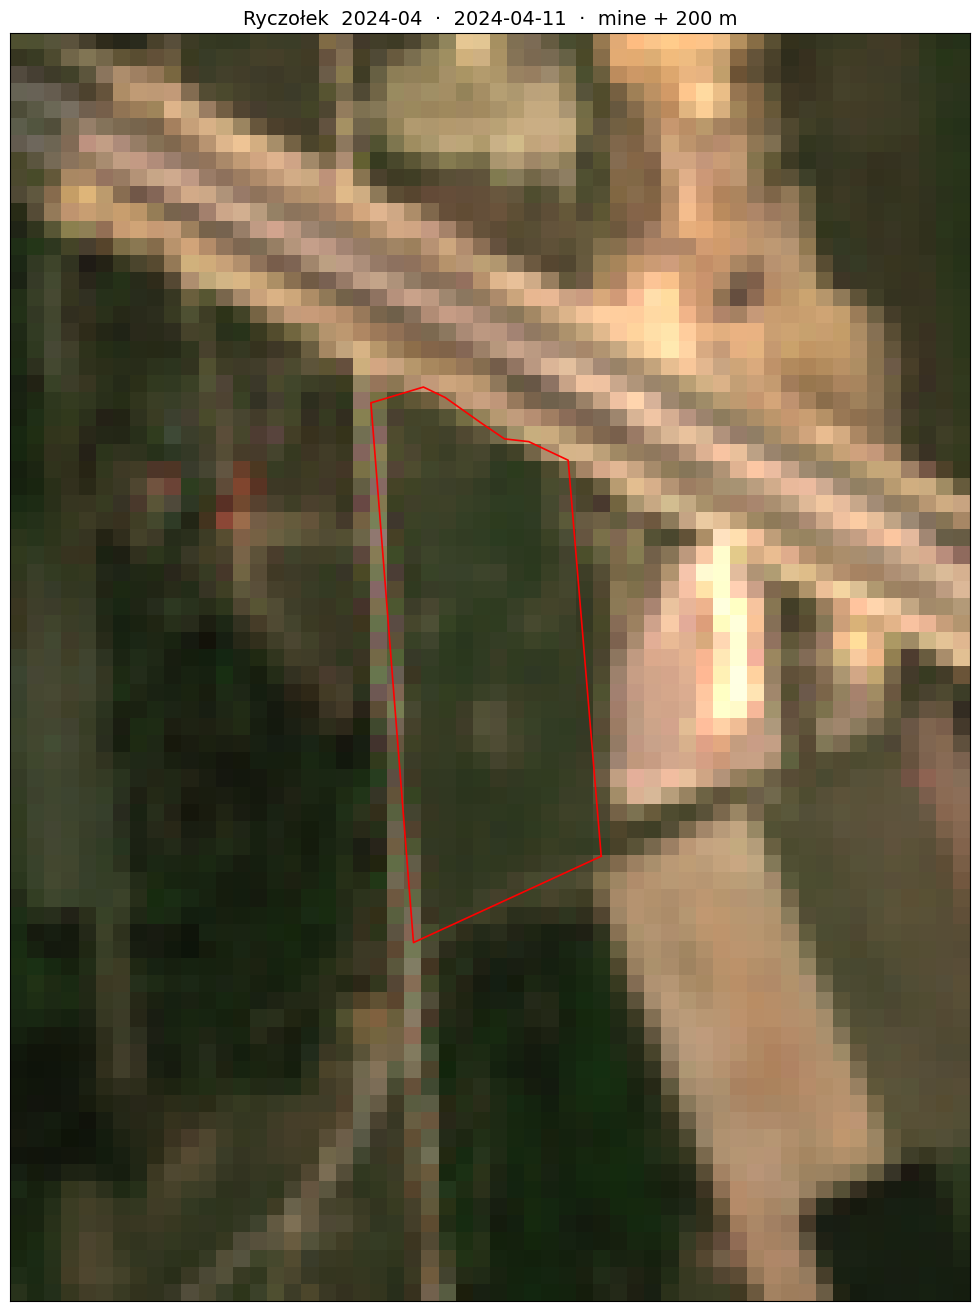

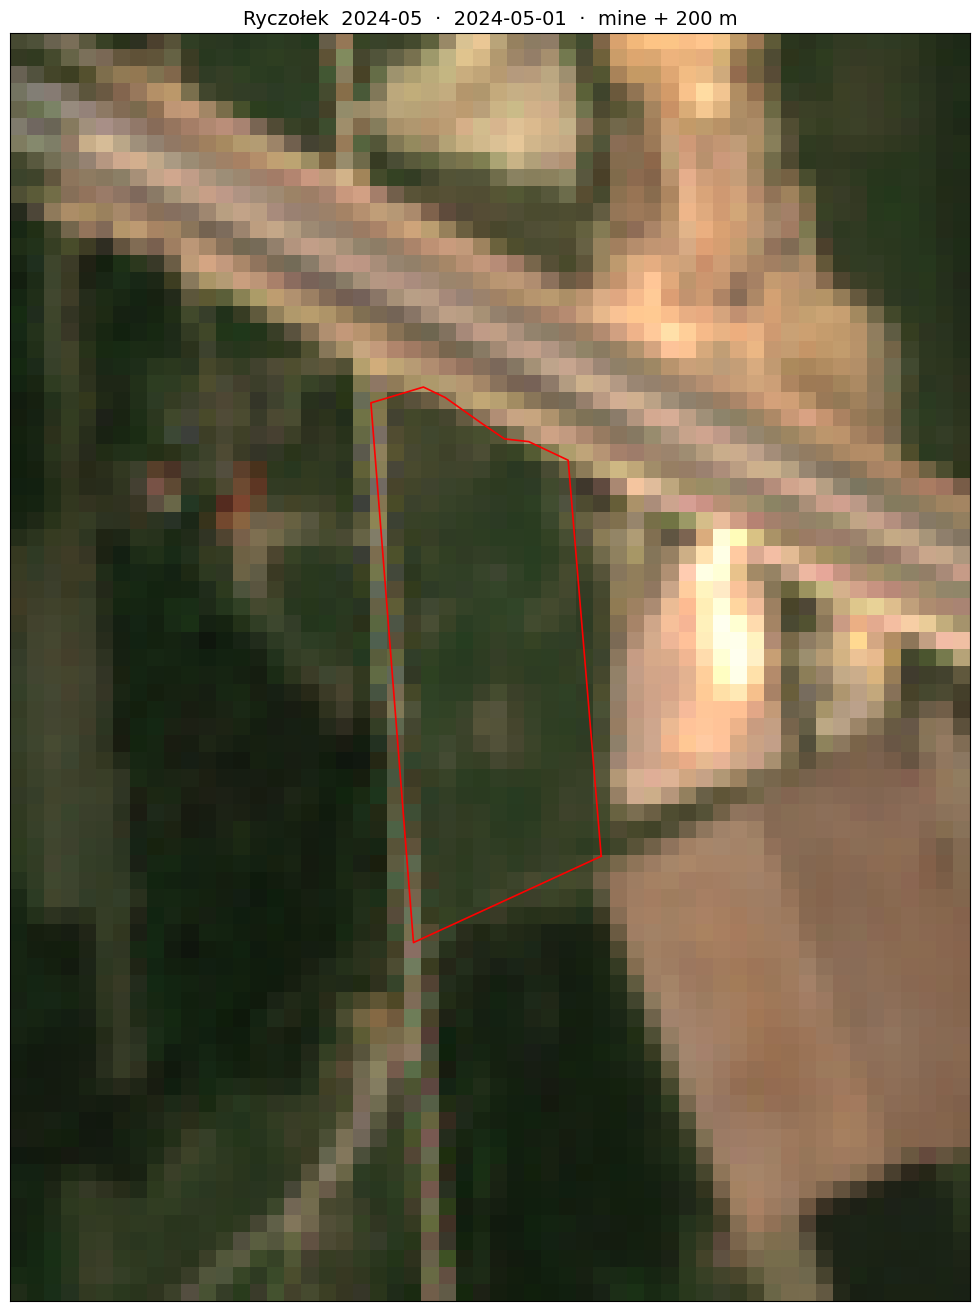

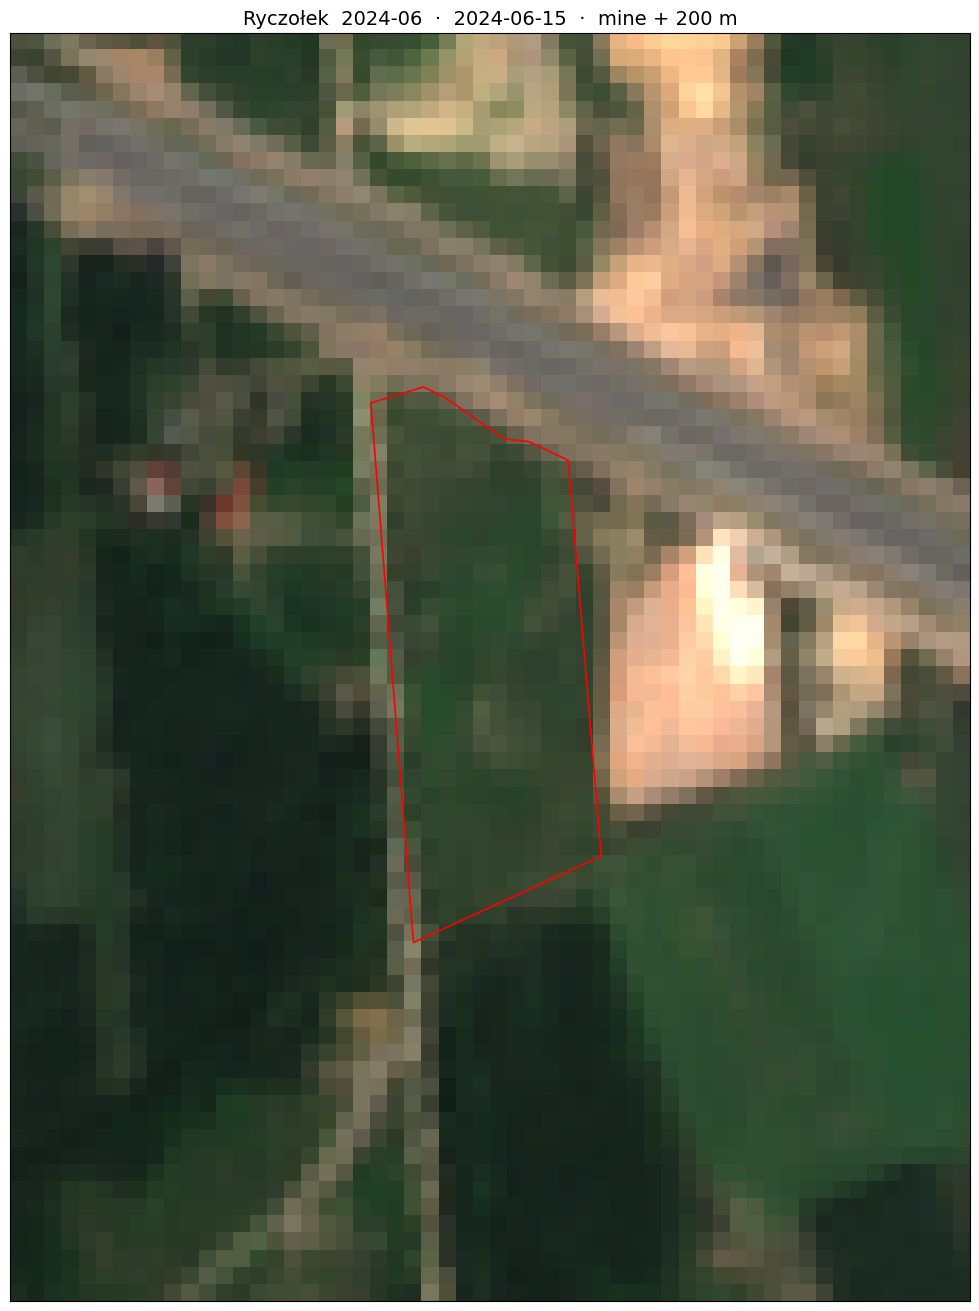

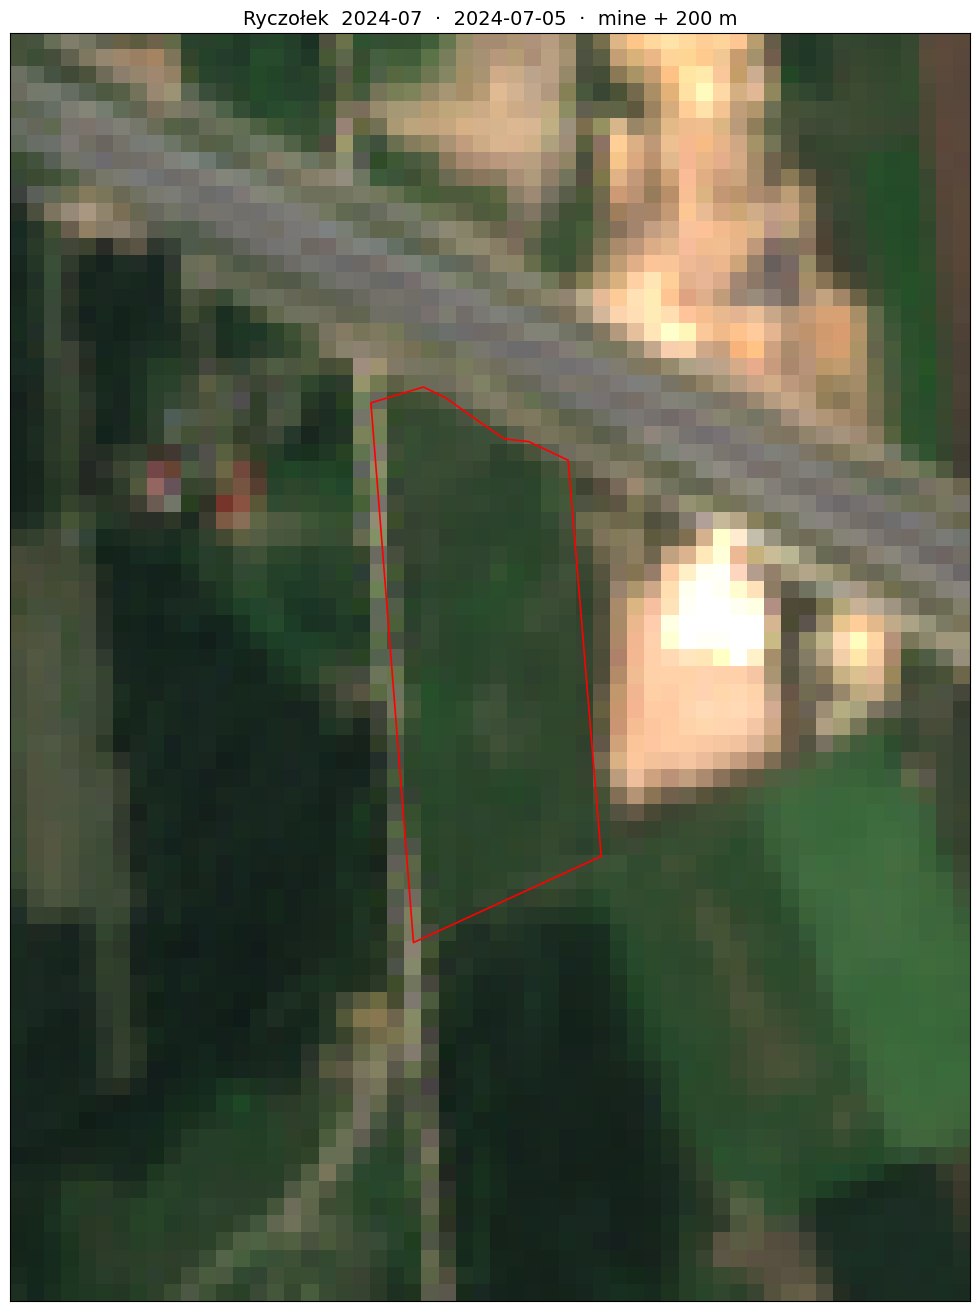

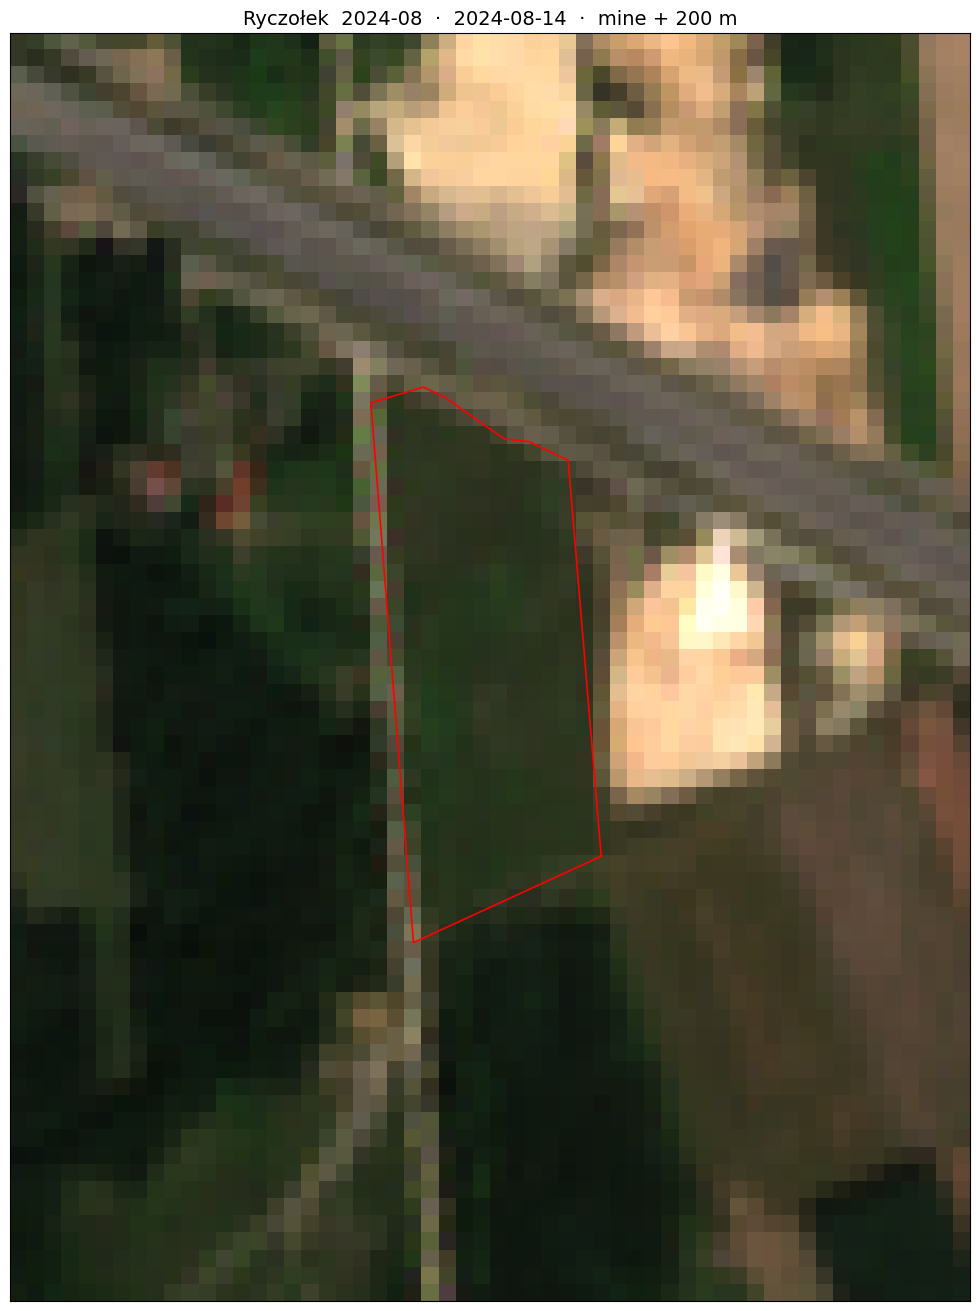

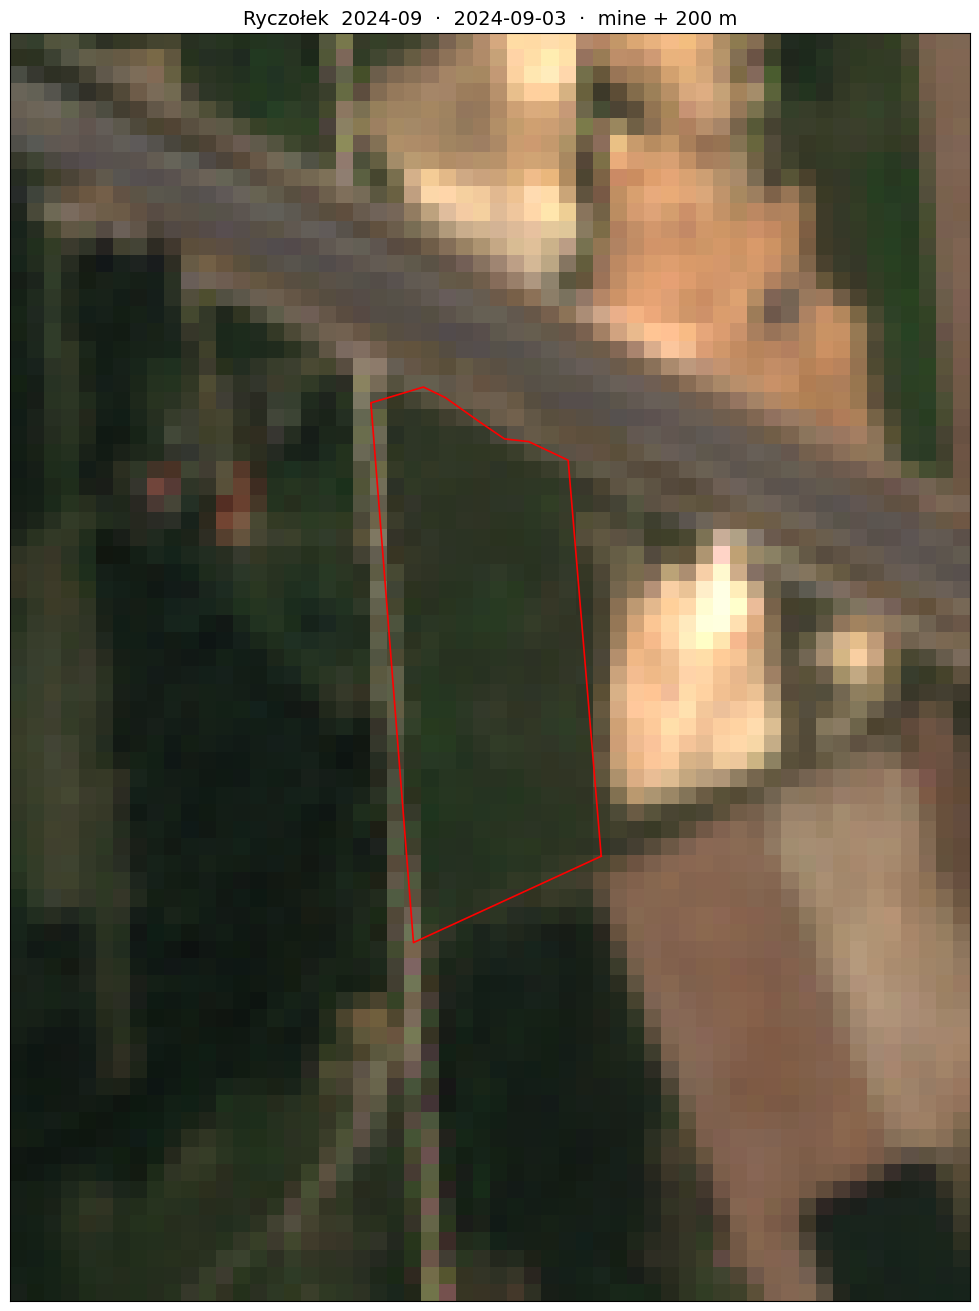

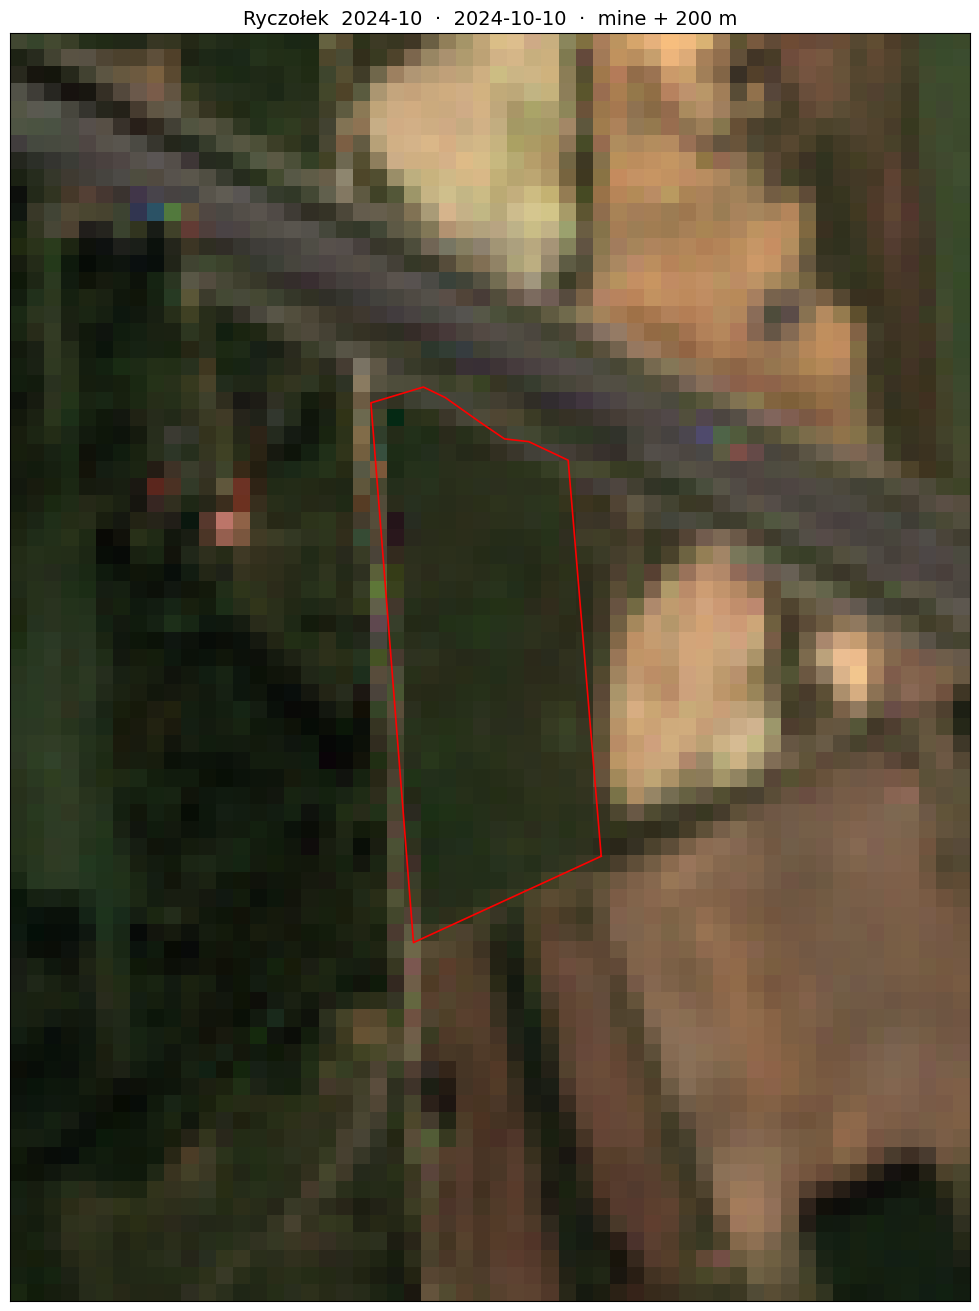

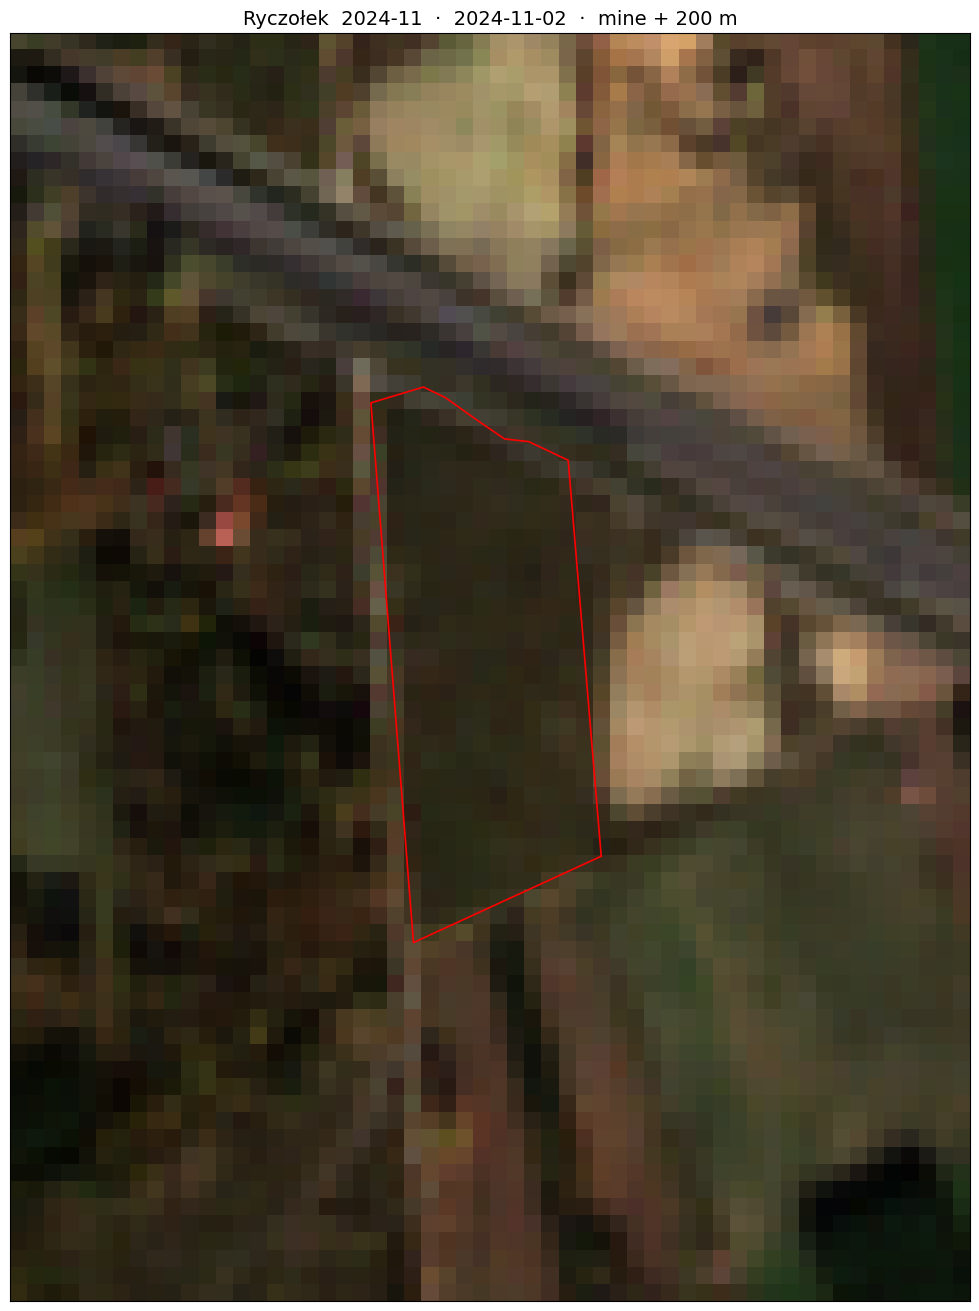

2024-12  no cloud-free scene


In [3]:
def rgb_view(image_id):
    image = ee.Image("COPERNICUS/S2_SR_HARMONIZED/" + image_id).select(["B4", "B3", "B2"])
    minx, miny, maxx, maxy = extent
    corners = ((minx, miny), (maxx, miny), (maxx, maxy), (minx, maxy))
    east, north = zip(*(to_utm.transform(x, y) for x, y in corners))
    left = float(np.floor(min(east) / 10.0) * 10.0)
    right = float(np.ceil(max(east) / 10.0) * 10.0)
    bottom = float(np.floor(min(north) / 10.0) * 10.0)
    top = float(np.ceil(max(north) / 10.0) * 10.0)
    width = int(round((right - left) / 10.0))
    height = int(round((top - bottom) / 10.0))
    struct = ee.data.computePixels({
        "expression": image,
        "fileFormat": "NUMPY_NDARRAY",
        "bandIds": ["B4", "B3", "B2"],
        "grid": {
            "dimensions": {"width": width, "height": height},
            "affineTransform": {
                "scaleX": 10,
                "shearX": 0,
                "translateX": left,
                "shearY": 0,
                "scaleY": -10,
                "translateY": top,
            },
            "crsCode": "EPSG:%d" % utm_epsg,
        },
    })
    rgb = np.stack([np.asarray(struct[band], dtype=np.float32) for band in ("B4", "B3", "B2")], axis=-1)
    rgb[~np.isfinite(rgb) | (rgb < 0)] = np.nan
    shown = np.clip(rgb / 3000.0, 0, 1)
    return np.nan_to_num(shown, nan=0.0), (left, right, bottom, top)


def draw_mine(ax):
    polygons = [mine_utm] if mine_utm.geom_type == "Polygon" else list(mine_utm.geoms)
    for polygon in polygons:
        xs, ys = polygon.exterior.xy
        ax.plot(xs, ys, color="red", linewidth=1.2)


for row in monthly:
    if not row["id"]:
        print("%s  no cloud-free scene" % row["month"])
        continue
    shown, box = rgb_view(row["id"])
    left, right, bottom, top = box
    fig_w = 10
    fig_h = fig_w * (top - bottom) / (right - left)
    fig, ax = plt.subplots(figsize=(fig_w, fig_h))
    ax.imshow(shown, extent=(left, right, bottom, top), origin="upper", interpolation="nearest")
    draw_mine(ax)
    ax.set_xlim(left, right)
    ax.set_ylim(bottom, top)
    ax.set_aspect("equal")
    ax.set_title("Ryczołek  %s  ·  %s  ·  mine + %d m" % (row["month"], row["date"], BUFFER_M), fontsize=14)
    ax.set_xticks([])
    ax.set_yticks([])
    fig.tight_layout()
    display(fig)
    plt.close(fig)
